In [1]:
# Cell 01 — Setup
# Output: Imports only; no installation or network access during Run All.
# Missing a package? Run the next line in a new code cell. Then restart Python.
# %pip install numpy scipy pandas matplotlib scikit-image scikit-learn pillow ipykernel PyWavelets
from pathlib import Path
import json, platform, hashlib, warnings, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from scipy import ndimage as ndi
from scipy.stats import rankdata, spearmanr
from skimage import color, restoration, filters
from PIL import Image
from IPython.display import display, Math
from sklearn.metrics import accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
np.random.seed(2026)
plt.rcParams.update({'figure.dpi':100, 'font.size':10, 'axes.grid':False})
pd.set_option('display.max_columns',30)


In [2]:
# Cell 02 — Configuration and output helpers
# Output: Configuration table; all parameters fixed and editable.
# Run the notebook from its extracted folder. Edit DATA_DIR if images are elsewhere.
DATA_DIR = Path('images')
OUT = Path('results'); OUT.mkdir(exist_ok=True)
IDS = ['2120','2318','2528','2630']
FILENAMES = {k:f'0000000367_0000000000_000000{k}.jpg' for k in IDS}
CFG = dict(bins=256, gaussian_sigma=1.0, median_size=3, nlm_patch=5,
           nlm_distance=6, nlm_h_factor=0.8, unsharp_amount=1.0,
           laplacian_amount=0.15, log_alpha=9.0, plip_M=1.01, plip_power=0.7,
           background_sigma=24.0, opening_size=65, ratio_epsilon=1/255,
           ratio_log_scale=2.0, window_sizes=[8,16,32], selected_window=16,
           selected_denoising='NLM', selected_pipeline='Gray|GaussianBG|Subtraction',
           selected_distance='chi2')
# These are starting choices, not winners. Set them before looking at test scores.
SPLITS = {'2120':'train','2318':'train','2528':'validation','2630':'test'}
ROI_CONFIRMED = False  # The GT cell will turn this on after the file checks pass.
# A box can hold an animal AND grass. It is not an animal outline.
# Keep each image in one group. Do not mix its patches across train and test.
# These four images are from one sequence. Any result is just a small first check.
EPS=1e-12
COLORS={'Original':'black','animal':'tab:orange','background':'tab:blue','mixed':'tab:purple'}
AUDIT=[]; TABLES={}
def safe_name(name): return re.sub(r'[^A-Za-z0-9_.-]+','_',name)
def savefig(name):
    plt.tight_layout(); plt.savefig(OUT/f'{safe_name(name)}.png',dpi=150,bbox_inches='tight'); plt.show(); plt.close()
def table(df,name):
    TABLES[name]=df.copy(); df.to_csv(OUT/f'{safe_name(name)}.csv',index=False); display(df)
def status(message):
    print(message); AUDIT.append(message)
def chart(df,x,y,name):
    if df.empty or y not in df or not df[y].notna().any():
        status(f'{name}: no eligible confirmed observations.'); return
    fig,ax=plt.subplots(figsize=(12,4)); df.plot.bar(x=x,y=y,ax=ax,legend=False)
    ax.set_title(name.replace('_',' ')); ax.set_ylabel(y); savefig(name)
table(pd.DataFrame([CFG]),'configuration')


,bins,gaussian_sigma,median_size,nlm_patch,nlm_distance,nlm_h_factor,unsharp_amount,laplacian_amount,log_alpha,plip_M,plip_power,background_sigma,opening_size,ratio_epsilon,ratio_log_scale,window_sizes,selected_window,selected_denoising,selected_pipeline,selected_distance
0,256,1.0,3,5,6,0.8,1.0,0.15,9.0,1.01,0.7,24.0,65,0.003922,2.0,"[8, 16, 32]",16,NLM,Gray|GaussianBG|Subtraction,chi2


In [3]:
# Cell 03 — Load the four original JPGs
# Output: Actual dimensions, ranges, split and input SHA256 hashes.
images={}; meta=[]
for k,name in FILENAMES.items():
    path=DATA_DIR/name
    if not path.exists():
        raise FileNotFoundError(f'Missing {path}. Extract the ZIP with its images folder or edit DATA_DIR.')
    raw=np.asarray(Image.open(path))
    if raw.ndim==3:
        spread=np.max(np.ptp(raw[...,:3].astype(float),axis=-1))
        if spread>0: warnings.warn(f'{name}: RGB channels differ; Pillow grayscale conversion used.')
    gray=np.asarray(Image.open(path).convert('L'))
    images[k]=gray.astype(np.float64)/255.0
    meta.append(dict(frame=k,file=name,height=gray.shape[0],width=gray.shape[1],
                     dtype=str(gray.dtype),minimum=int(gray.min()),maximum=int(gray.max()),
                     split=SPLITS[k],sha256=hashlib.sha256(path.read_bytes()).hexdigest()))
table(pd.DataFrame(meta),'image_metadata')
# Keep the image size. Pixel sizes and box positions stay the same.


,frame,file,height,width,dtype,minimum,maximum,split,sha256
0,2120,0000000367_0000000000_0000002120.jpg,321,700,uint8,102,255,train,f212521dacf0f412690d30fc10c65eac514e9fb33fea82...
1,2318,0000000367_0000000000_0000002318.jpg,321,700,uint8,101,255,train,9034f974b5d99d800ebf6b67517713699aea6ad185dde2...
2,2528,0000000367_0000000000_0000002528.jpg,321,700,uint8,99,255,validation,d4a89afd402da8e5a29864f0d1b383c8679978135da0e1...
3,2630,0000000367_0000000000_0000002630.jpg,321,700,uint8,106,251,test,3b5da9546e304b951137103e61781a0b94eb5dae5f2851...


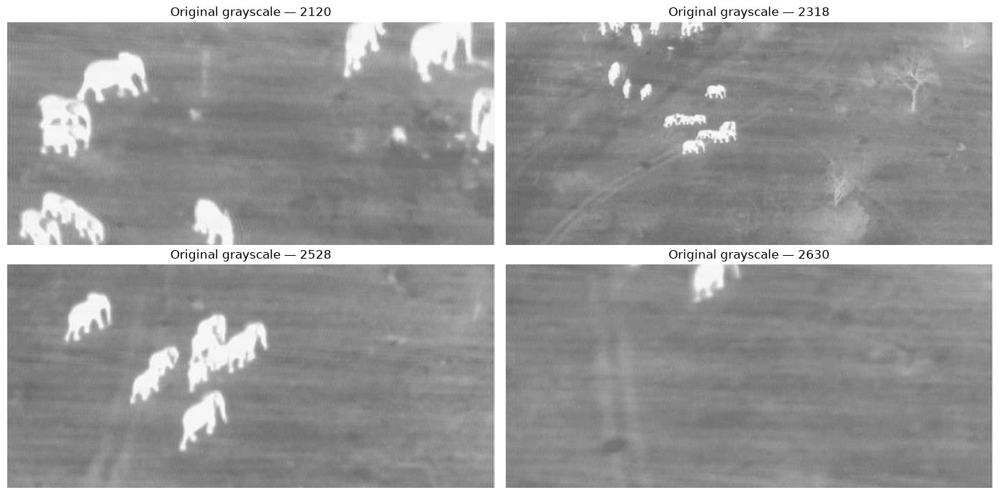

In [4]:
# Cell 04 — Original images
# Output: Four unmodified images on a common display scale.
fig,axes=plt.subplots(2,2,figsize=(14,7))
for ax,(k,a) in zip(axes.flat,images.items()):
    ax.imshow(a,cmap='gray',vmin=0,vmax=1); ax.set_title(f'Original grayscale — {k}'); ax.axis('off')
savefig('original_images')


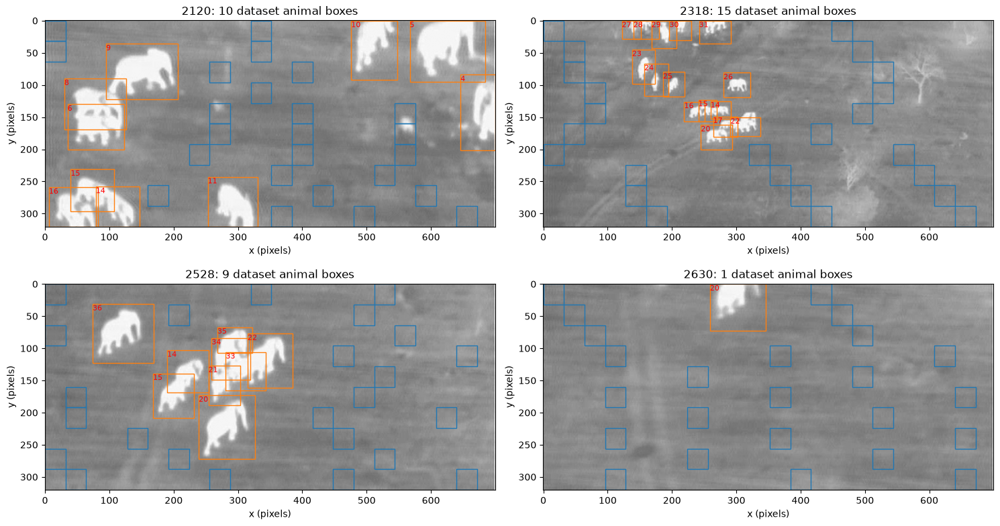

,frame,animal_boxes,background_patches,label_source
0,2120,10,24,Dataset bounding boxes
1,2318,15,24,Dataset bounding boxes
2,2528,9,24,Dataset bounding boxes
3,2630,1,24,Dataset bounding boxes


,frame,track_id,x,y,width,height,flag_6,flag_7,flag_8,flag_9
17184,2120,4,646,84,54,118,0,1,0,0
17185,2120,5,567,0,117,95,0,1,0,0
17186,2120,6,35,130,88,71,0,1,1,0
17187,2120,8,30,90,96,79,0,1,1,0
17188,2120,9,95,36,112,86,0,1,0,0
17189,2120,10,476,0,72,92,0,1,0,0
17190,2120,11,253,243,78,78,0,1,0,0
17191,2120,14,79,258,68,63,0,1,0,0
17192,2120,15,40,231,67,66,0,1,0,0
17193,2120,16,6,259,76,62,0,1,0,0


Background labels mean outside all known boxes. This assumes the animal labels are complete.


In [5]:
# Cell 05 — Read the real animal boxes
# Output: Dataset boxes, safe background patches, and four labeled images.
# These boxes come from the dataset, not from our earlier guesses.
# A box includes some grass. It is NOT a pixel-perfect animal mask.
GT_PATH=Path('annotations/0000000367_0000000000.csv')
GT_COLUMNS=['frame','track_id','x','y','width','height','flag_6','flag_7','flag_8','flag_9']
GT=pd.read_csv(GT_PATH,header=None,names=GT_COLUMNS)
assert GT.shape[1]==10 and not GT.isna().any().any()
# We checked x, y, width, height against the tracking GT files.
# The four flag meanings are not given here. Keep them, but do not guess what they mean.
GT=GT[(GT.width>0)&(GT.height>0)].copy()
def crop(a,b):
    x0,y0,x1,y1=b; return a[y0:y1,x0:x1]
def gt_boxes(frame,shape):
    h,w=shape; boxes=[]
    for r in GT[GT.frame==int(frame)].itertuples():
        b=(max(0,int(r.x)),max(0,int(r.y)),min(w,int(r.x+r.width)),min(h,int(r.y+r.height)))
        if b[2]>b[0] and b[3]>b[1]: boxes.append((int(r.track_id),b))
    return boxes
def background_boxes(shape,animal_boxes,limit=24,buffer=8):
    # A background patch must miss ALL animal boxes, plus an 8-pixel safety gap.
    # Pick patches across the photo in a fixed order. Do not pick by brightness.
    h,w=shape; candidates=[]
    for y in range(0,h-31,32):
        for x in range(0,w-31,32):
            b=(x,y,x+32,y+32)
            hits=any(min(b[2]+buffer,a[2])>max(b[0]-buffer,a[0]) and
                     min(b[3]+buffer,a[3])>max(b[1]-buffer,a[1]) for a in animal_boxes)
            if not hits: candidates.append(b)
    if len(candidates)>limit:
        candidates=[candidates[i] for i in np.linspace(0,len(candidates)-1,limit).round().astype(int)]
    return candidates
def center_patch(a,cx,cy,size):
    # At the photo edge, use the real pixels that exist. Do not invent padding pixels.
    h=size//2
    return a[max(0,cy-h):min(a.shape[0],cy+h),max(0,cx-h):min(a.shape[1],cx+h)]
ROIS={}; GT_IDS={}; rows=[]
for k,a in images.items():
    pairs=gt_boxes(k,a.shape);GT_IDS[k]=[tid for tid,b in pairs]
    animal=[b for tid,b in pairs];background=background_boxes(a.shape,animal)
    assert animal and background,k
    ROIS[k]={'animal':animal,'background':background,'mixed':[]}
    rows.append(dict(frame=k,animal_boxes=len(animal),background_patches=len(background),label_source='Dataset bounding boxes'))
ROI_CONFIRMED=True  # Real dataset labels are loaded. These are box labels, not pixel labels.
fig,axes=plt.subplots(2,2,figsize=(15,8))
for ax,(k,a) in zip(axes.flat,images.items()):
    ax.imshow(a,cmap='gray',vmin=0,vmax=1)
    for label in ['animal','background']:
        for j,(x0,y0,x1,y1) in enumerate(ROIS[k][label]):
            ax.add_patch(Rectangle((x0,y0),x1-x0,y1-y0,fill=False,color=COLORS[label],lw=1))
            if label=='animal':ax.text(x0,y0+10,str(GT_IDS[k][j]),color='red',fontsize=8)
    ax.set_title(f'{k}: {len(ROIS[k]["animal"])} dataset animal boxes');ax.set_xlabel('x (pixels)');ax.set_ylabel('y (pixels)')
savefig('dataset_gt_and_background')
table(pd.DataFrame(rows),'dataset_gt_counts')
table(GT[GT.frame.isin([int(k) for k in IDS])],'four_frame_gt')
(OUT/'roi_configuration.json').write_text(json.dumps({'source':str(GT_PATH),'boxes':ROIS,'splits':SPLITS},indent=2))
print('Background labels mean outside all known boxes. This assumes the animal labels are complete.')


In [6]:
# Cell 06 — Histogram and plotting utilities
# Output: Reusable fixed-bin histograms, distances and consistent plot layouts.
# Use 256 equal bins from 0 to 1. The last bin includes 1.
# For the original image, this puts each 8-bit gray level in its own bin.
EDGES=np.linspace(0,1,257); CENTERS=(EDGES[:-1]+EDGES[1:])/2
BANK={'Original':images}; GROUPS={}; METRICS={}
def hist(a,edges=EDGES):
    x=np.asarray(a).ravel(); x=x[np.isfinite(x)]
    if not x.size: return np.full(len(edges)-1,np.nan)
    h=np.histogram(x,bins=edges)[0].astype(float)
    assert h.sum()==x.size, 'Histogram range excludes values'
    return h/h.sum()
def distance(p,q,kind='chi2'):
    p=np.asarray(p); q=np.asarray(q)
    if kind=='L1': return np.sum(np.abs(p-q),axis=-1)
    if kind=='L2': return np.sqrt(np.sum((p-q)**2,axis=-1))
    if kind=='chi2': return 0.5*np.sum((p-q)**2/(p+q+EPS),axis=-1)
    raise ValueError(kind)
def entropy(p): return float(-np.sum(p*np.log2(p+EPS)))
def statistics(a):
    p=hist(a)
    return dict(mean=float(a.mean()),median=float(np.median(a)),mode=float(CENTERS[np.argmax(p)]),
                variance=float(a.var()),std=float(a.std()),entropy_bits=entropy(p))
def register(name,fn):
    BANK[name]={k:np.clip(fn(a),0,1) for k,a in images.items()}
    return name
def comparisons(names,tag):
    names=list(dict.fromkeys(['Original']+list(names)))
    fig,axes=plt.subplots(4,len(names),figsize=(4*len(names),9),squeeze=False)
    for row,k in enumerate(IDS):
        for col,name in enumerate(names):
            ax=axes[row,col]; ax.imshow(BANK[name][k],cmap='gray',vmin=0,vmax=1)
            ax.set_title(f'{k} | {name}',fontsize=9); ax.axis('off')
    savefig(tag)
def overlays(names,tag):
    names=list(dict.fromkeys(['Original']+list(names)))
    fig,axes=plt.subplots(2,2,figsize=(14,7),sharex=True,sharey=True)
    for ax,k in zip(axes.flat,IDS):
        for name in names: ax.plot(CENTERS,hist(BANK[name][k]),label=name,lw=1)
        ax.set_title(k); ax.set_xlabel('Normalized intensity'); ax.set_ylabel('Probability / bin'); ax.legend(fontsize=7)
    savefig(tag)
def roi_overlays(names,tag):
    fig,axes=plt.subplots(len(names),4,figsize=(16,3*len(names)),squeeze=False,sharex=True,sharey=True)
    for r,name in enumerate(names):
        for c,k in enumerate(IDS):
            ax=axes[r,c]
            for label in ['animal','background']:
                patches=[crop(BANK[name][k],b).ravel() for b in ROIS[k][label]]
                if patches: ax.plot(CENTERS,hist(np.concatenate(patches)),color=COLORS[label],label=label+' ROI')
            ax.set_title(f'{name} | {k}',fontsize=9); ax.set_xlabel('Normalized intensity'); ax.set_ylabel('Probability / bin')
            ax.legend(fontsize=7)
    fig.suptitle('Dataset box ROIs' if ROI_CONFIRMED else 'Proposed ROIs — exploratory only',y=1.01)
    savefig(tag)


In [7]:
# Cell 07 — Evaluation and remapping controls
# Output: Guarded animal/background evaluation, descriptive diagnostics, rank-remapping control.
# We have no perfect clean image. So we do not claim a PSNR or SSIM quality score.
# These numbers describe the images. A big margin is not an accuracy score.
def pairmean(ps,qs=None):
    ds=([distance(p,q) for i,p in enumerate(ps) for q in ps[i+1:]] if qs is None
        else [distance(p,q) for p in ps for q in qs])
    return float(np.mean(ds)) if ds else np.nan
def separation(name,frame_ids=None):
    frame_ids=frame_ids or [k for k in IDS if SPLITS[k]!='test']
    if not ROI_CONFIRMED: return dict(between=np.nan,within_animal=np.nan,within_background=np.nan,margin=np.nan)
    by={label:[hist(crop(BANK[name][k],b)) for k in frame_ids for b in ROIS[k][label]] for label in ['animal','background']}
    ab=pairmean(by['animal'],by['background']); aa=pairmean(by['animal']); bb=pairmean(by['background'])
    return dict(between=ab,within_animal=aa,within_background=bb,margin=ab-(aa+bb)/2)
def evaluate(names,tag):
    rows=[]
    for name in names:
        row=dict(method=name,roi_status='confirmed' if ROI_CONFIRMED else 'pending manual confirmation',**separation(name))
        changes=[]; edges=[]; saturation=[]; bg_edges=[]
        for k in IDS:
            a=BANK[name][k]; src=images[k]
            changes.append(distance(hist(src),hist(a)))
            edges.append(np.mean(filters.sobel(a)))
            saturation.append(np.mean((a<=0)|(a>=1)))
            if ROI_CONFIRMED and SPLITS[k]!='test':
                bg_edges.extend([float(filters.sobel(crop(a,b)).mean()) for b in ROIS[k]['background']])
        row.update(histogram_change=float(np.mean(changes)),mean_edge_strength=float(np.mean(edges)),
                   endpoint_fraction=float(np.mean(saturation)),background_edge_strength=float(np.mean(bg_edges)) if bg_edges else np.nan)
        rows.append(row)
    df=pd.DataFrame(rows); METRICS[tag]=df; table(df,tag)
    chart(df,'method','margin',tag+'_separation')
    chart(df,'method','histogram_change',tag+'_histogram_change')
    return df
def decision(df,default,stage):
    print(f'{stage}: predeclared setting = {default}. No automatic winner claimed.')
    if ROI_CONFIRMED:
        display(df[['method','margin']].sort_values('margin',ascending=False))
        print('Margin ranking uses train/validation dataset boxes; it is exploratory.')
    else: print('Selection deferred: manually confirm ROIs and rerun. Descriptive image statistics remain available.')
# Rank means brightness order. An increasing curve keeps this order, except for ties.
def rank_image(a): return ((rankdata(a.ravel(),method='average')-0.5)/a.size).reshape(a.shape)


In [8]:
# Cell 08 — Baseline histogram formula
# Output: Separate LaTeX formulas.
display(Math('p_j=\\frac{1}{N}\\sum_{x\\in\\Omega}\\mathbf{1}[e_j\\leq I(x)<e_{j+1}],\\qquad \\sum_jp_j=1'))
display(Math('H(p)=-\\sum_jp_j\\log_2p_j,\\quad M=\\overline D_{AB}-\\frac{\\overline D_{AA}+\\overline D_{BB}}{2}'))


<IPython.core.display.Math object>

<IPython.core.display.Math object>

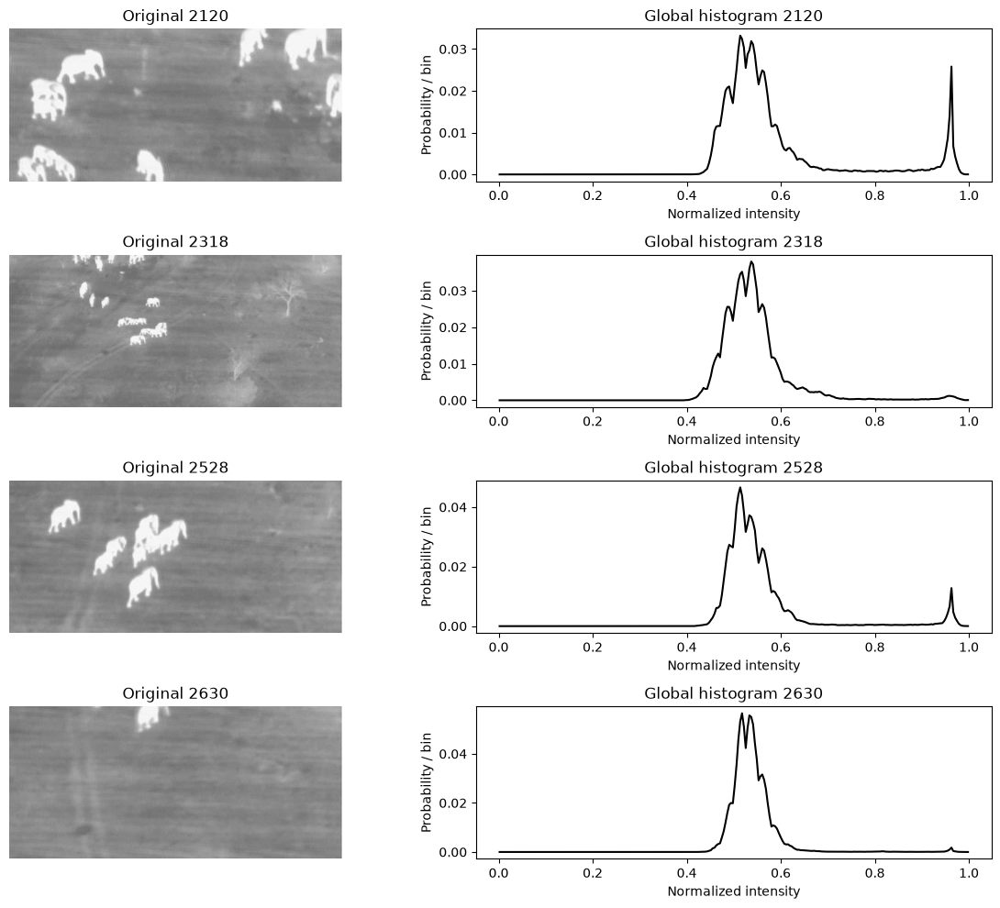

In [9]:
# Cell 09 — Global baseline histograms
# Output: Original images and corresponding global histograms.
fig,axes=plt.subplots(4,2,figsize=(12,10))
for r,(k,a) in enumerate(images.items()):
    axes[r,0].imshow(a,cmap='gray',vmin=0,vmax=1); axes[r,0].set_title('Original '+k); axes[r,0].axis('off')
    axes[r,1].plot(CENTERS,hist(a),color='black'); axes[r,1].set_title('Global histogram '+k)
    axes[r,1].set_xlabel('Normalized intensity'); axes[r,1].set_ylabel('Probability / bin')
savefig('baseline_global')


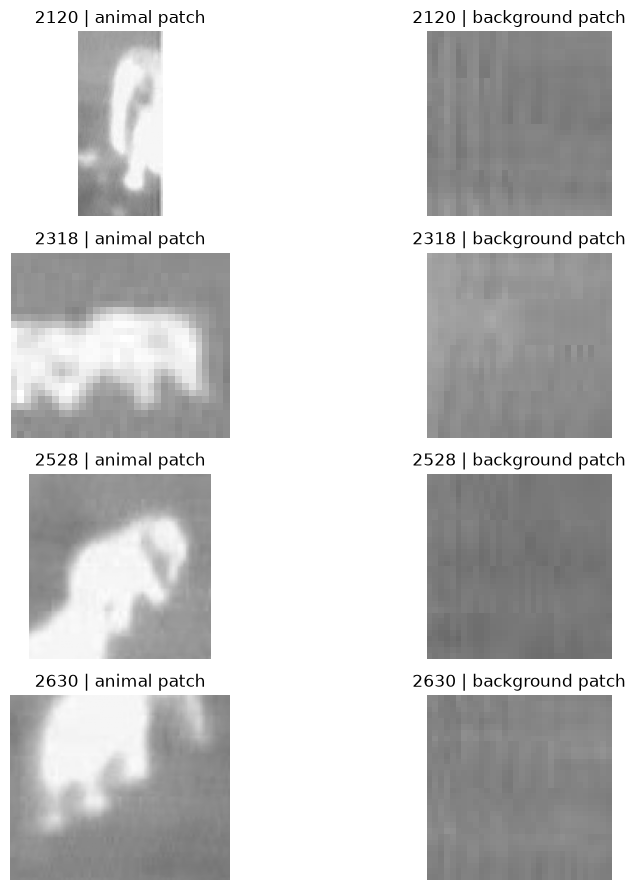

In [10]:
# Cell 10 — Check real animal and background crops
# Output: One animal box and one safe background patch from each photo.
fig,axes=plt.subplots(4,2,figsize=(10,9))
for r,k in enumerate(IDS):
    for c,label in enumerate(['animal','background']):
        axes[r,c].imshow(crop(images[k],ROIS[k][label][0]),cmap='gray',vmin=0,vmax=1)
        axes[r,c].set_title(f'{k} | {label} patch');axes[r,c].axis('off')
savefig('gt_patch_examples')


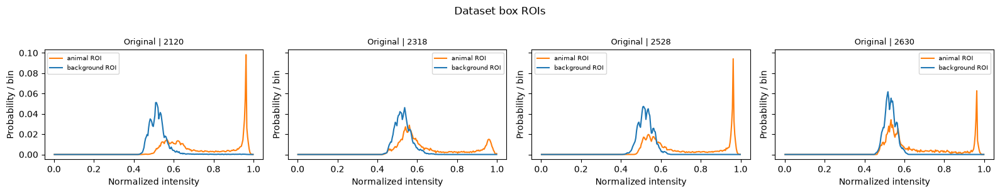

In [11]:
# Cell 11 — Baseline ROI histogram overlays
# Output: Animal/background overlays; using real dataset boxes.
roi_overlays(['Original'],'baseline_roi_histograms')


In [12]:
# Cell 12 — Baseline descriptive statistics
# Output: Actual patch mean, median, mode, variance, standard deviation and entropy.
rows=[]
for k,a in images.items():
    rows.append(dict(frame=k,region='global',**statistics(a)))
    for label,boxes in ROIS[k].items():
        for j,b in enumerate(boxes): rows.append(dict(frame=k,region=f'dataset {label} {j}',**statistics(crop(a,b))))
table(pd.DataFrame(rows),'baseline_statistics')


,frame,region,mean,median,mode,variance,std,entropy_bits
0,2120,global,0.587218,0.541176,0.513672,0.018775,0.137023,6.111712
1,2120,dataset animal 0,0.728918,0.662745,0.962891,0.026477,0.162717,6.607837
2,2120,dataset animal 1,0.772343,0.709804,0.962891,0.024320,0.155948,5.809603
3,2120,dataset animal 2,0.784538,0.823529,0.962891,0.028657,0.169284,6.294160
4,2120,dataset animal 3,0.780939,0.839216,0.962891,0.030614,0.174969,6.266992
...,...,...,...,...,...,...,...,...
130,2630,dataset background 19,0.527041,0.525490,0.517578,0.000229,0.015134,3.865200
131,2630,dataset background 20,0.524540,0.521569,0.501953,0.000731,0.027029,4.628872
132,2630,dataset background 21,0.555572,0.556863,0.560547,0.000252,0.015875,3.981060
133,2630,dataset background 22,0.582927,0.588235,0.591797,0.000371,0.019271,4.241888


,method,roi_status,between,within_animal,within_background,margin,histogram_change,mean_edge_strength,endpoint_fraction,background_edge_strength
0,Original,confirmed,0.661588,0.200011,0.437106,0.34303,0.0,0.013785,0.000028,0.010951


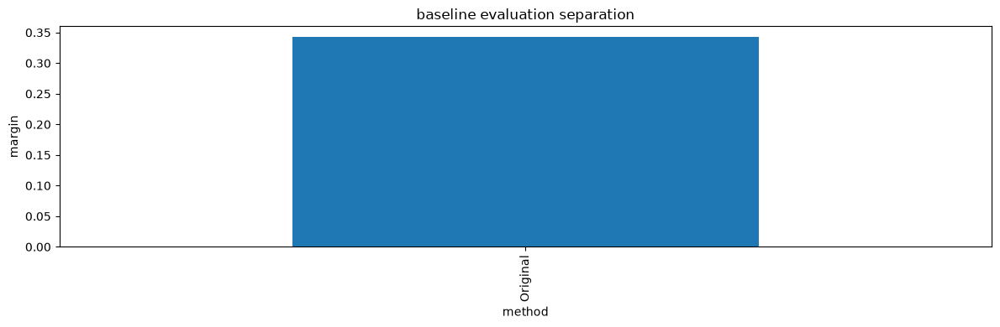

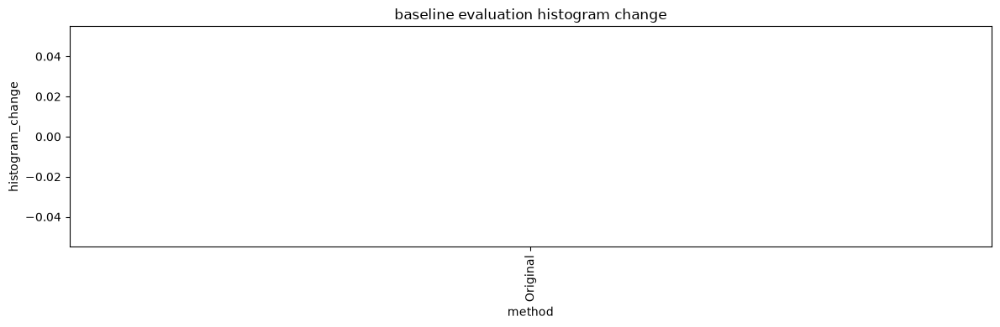

In [13]:
# Cell 13 — Baseline separation evaluation
# Output: Confirmed-ROI separation or explicit missing values; no invented scores.
baseline_metrics=evaluate(['Original'],'baseline_evaluation')


In [14]:
# Cell 14 — Grayscale representation formula
# Output: Separate LaTeX formulas.
display(Math('u=I/255,\\quad R_s=G_s=B_s=u'))


<IPython.core.display.Math object>

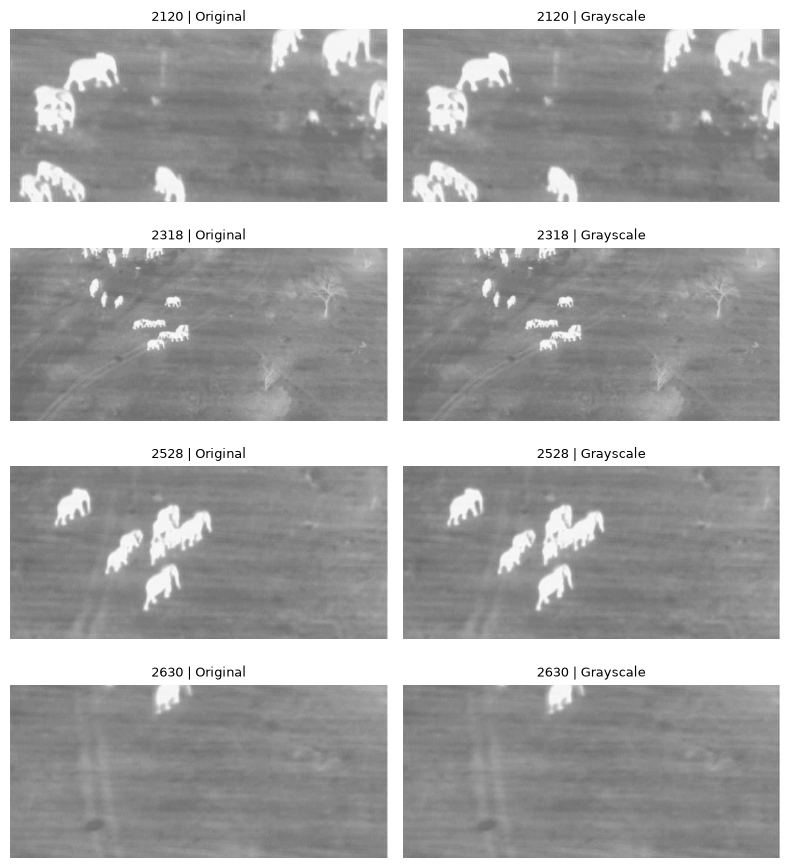

In [15]:
# Cell 15 — Grayscale image comparison
# Output: Original and represented brightness for all four frames; shared [0,1] display.
# We use sRGB and D65 as math rules. We do not know the camera calibration.
register('Grayscale',lambda a:a)
comparisons(['Grayscale'],'representation_Grayscale_images')


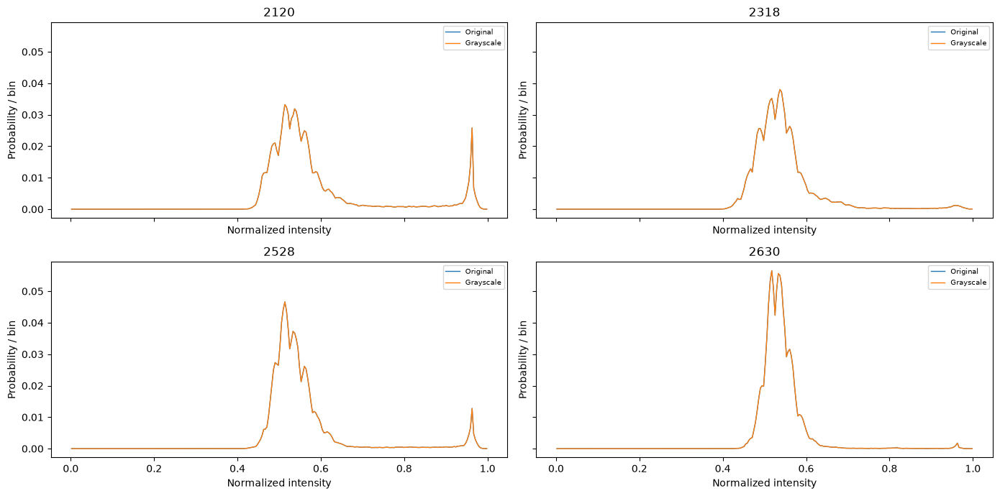

In [16]:
# Cell 16 — Grayscale histogram overlay
# Output: Original and representation probabilities on the same 256 bins.
overlays(['Grayscale'],'representation_Grayscale_histograms')


,method,roi_status,between,within_animal,within_background,margin,histogram_change,mean_edge_strength,endpoint_fraction,background_edge_strength
0,Original,confirmed,0.661588,0.200011,0.437106,0.34303,0.0,0.013785,0.000028,0.010951
1,Grayscale,confirmed,0.661588,0.200011,0.437106,0.34303,0.0,0.013785,0.000028,0.010951


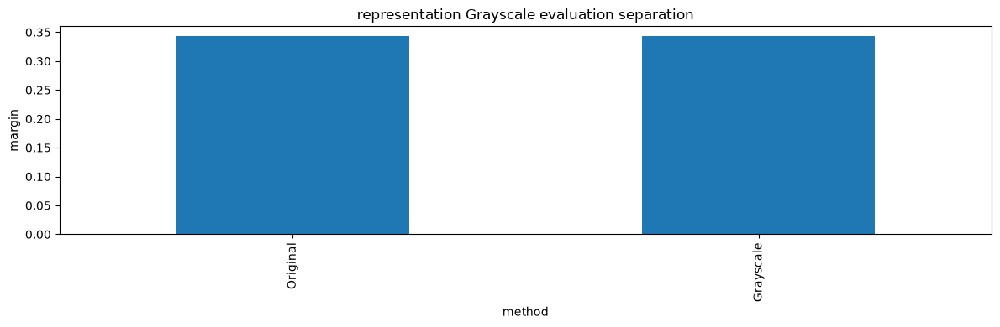

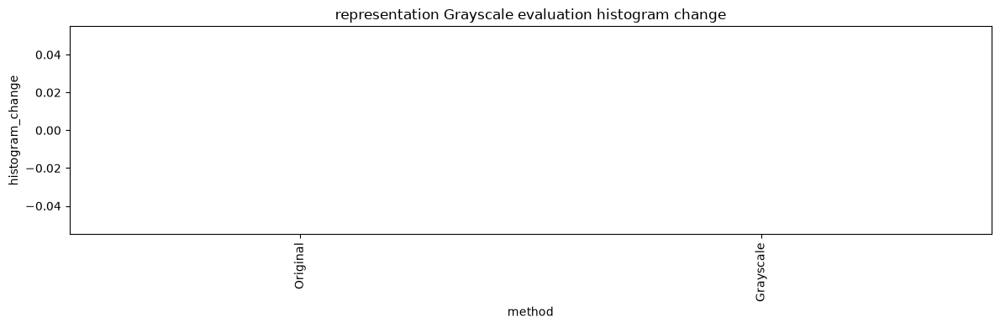

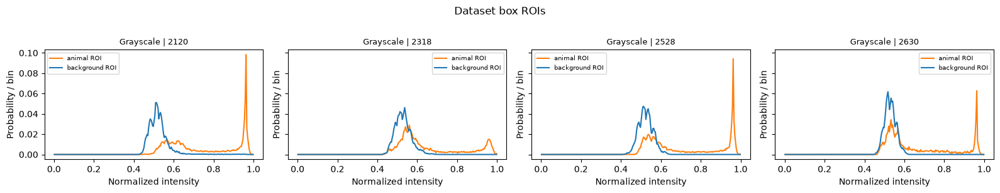

In [17]:
# Cell 17 — Grayscale animal/background evaluation
# Output: Separation table/charts and ROI histograms; using real dataset boxes.
evaluate(['Original','Grayscale'],'representation_Grayscale_evaluation')
roi_overlays(['Grayscale'],'representation_Grayscale_roi')


In [18]:
# Cell 18 — HSV-V representation formula
# Output: Separate LaTeX formulas.
display(Math('V=\\max(R_s,G_s,B_s)=u\\quad\\mathrm{when}\\quad R_s=G_s=B_s=u'))


<IPython.core.display.Math object>

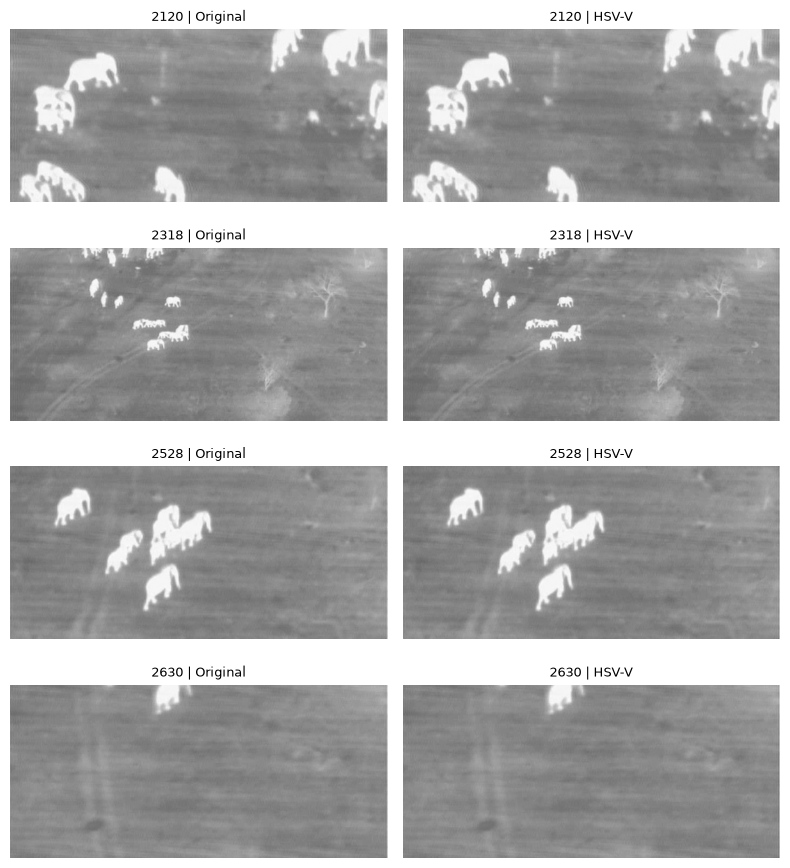

In [19]:
# Cell 19 — HSV-V image comparison
# Output: Original and represented brightness for all four frames; shared [0,1] display.
# We use sRGB and D65 as math rules. We do not know the camera calibration.
register('HSV-V',lambda a:color.rgb2hsv(color.gray2rgb(a))[...,2])
comparisons(['HSV-V'],'representation_HSV-V_images')


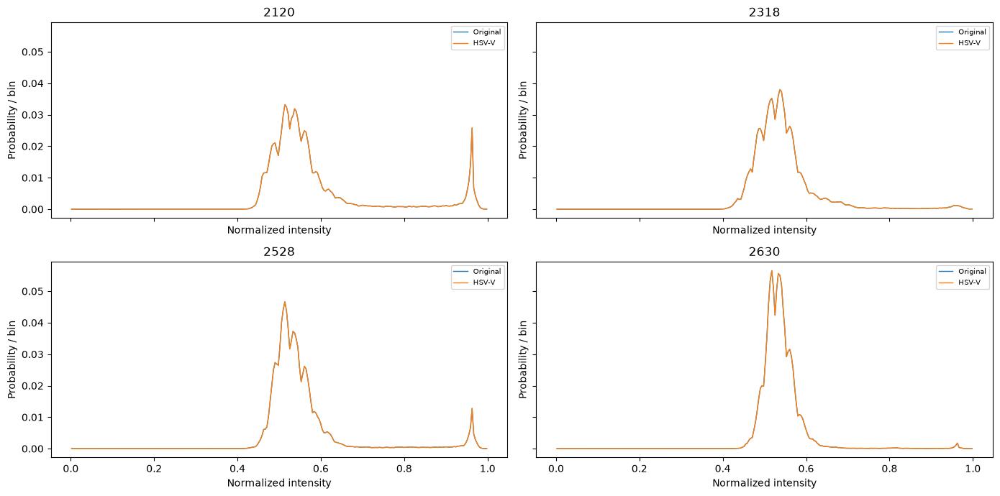

In [20]:
# Cell 20 — HSV-V histogram overlay
# Output: Original and representation probabilities on the same 256 bins.
overlays(['HSV-V'],'representation_HSV-V_histograms')


,method,roi_status,between,within_animal,within_background,margin,histogram_change,mean_edge_strength,endpoint_fraction,background_edge_strength
0,Original,confirmed,0.661588,0.200011,0.437106,0.34303,0.0,0.013785,0.000028,0.010951
1,HSV-V,confirmed,0.661588,0.200011,0.437106,0.34303,0.0,0.013785,0.000028,0.010951


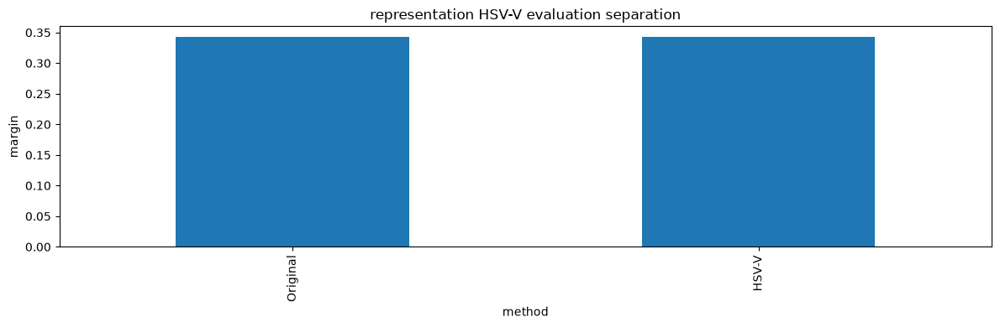

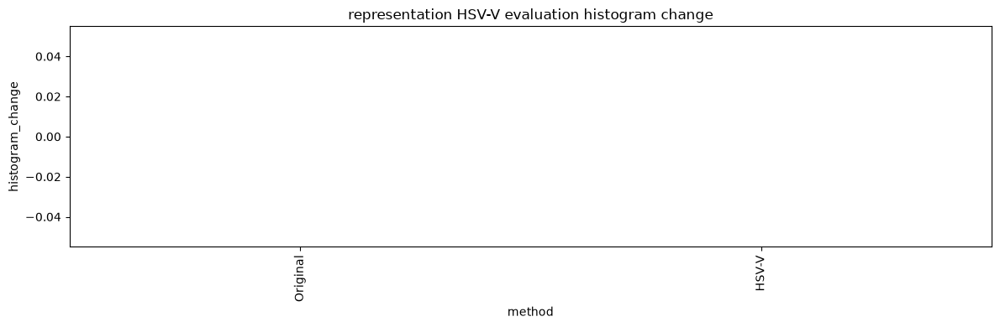

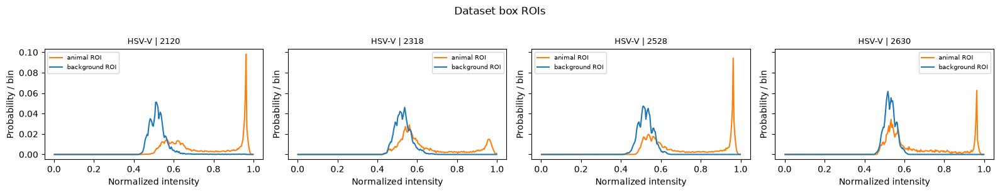

In [21]:
# Cell 21 — HSV-V animal/background evaluation
# Output: Separation table/charts and ROI histograms; using real dataset boxes.
evaluate(['Original','HSV-V'],'representation_HSV-V_evaluation')
roi_overlays(['HSV-V'],'representation_HSV-V_roi')


In [22]:
# Cell 22 — XYZ-Y representation formula
# Output: Separate LaTeX formulas.
display(Math('c_{lin}=\\begin{cases}c_s/12.92&c_s\\leq0.04045\\\\((c_s+0.055)/1.055)^{2.4}&c_s>0.04045\\end{cases}\\quad Y=0.212671R_{lin}+0.715160G_{lin}+0.072169B_{lin}'))


<IPython.core.display.Math object>

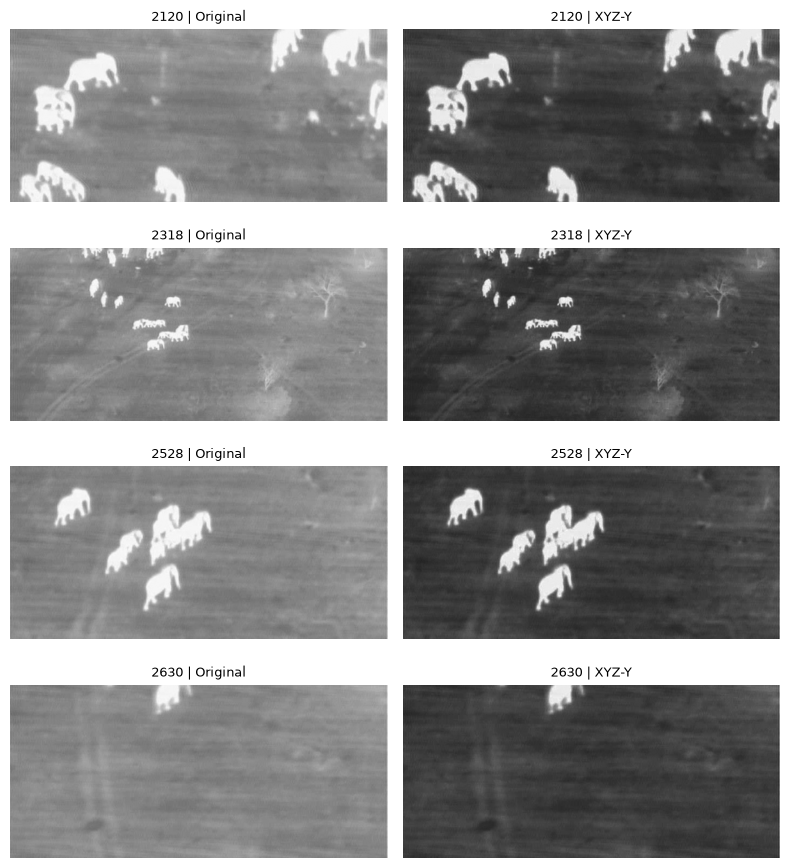

In [23]:
# Cell 23 — XYZ-Y image comparison
# Output: Original and represented brightness for all four frames; shared [0,1] display.
# We use sRGB and D65 as math rules. We do not know the camera calibration.
register('XYZ-Y',lambda a:color.rgb2xyz(color.gray2rgb(a))[...,1])
comparisons(['XYZ-Y'],'representation_XYZ-Y_images')


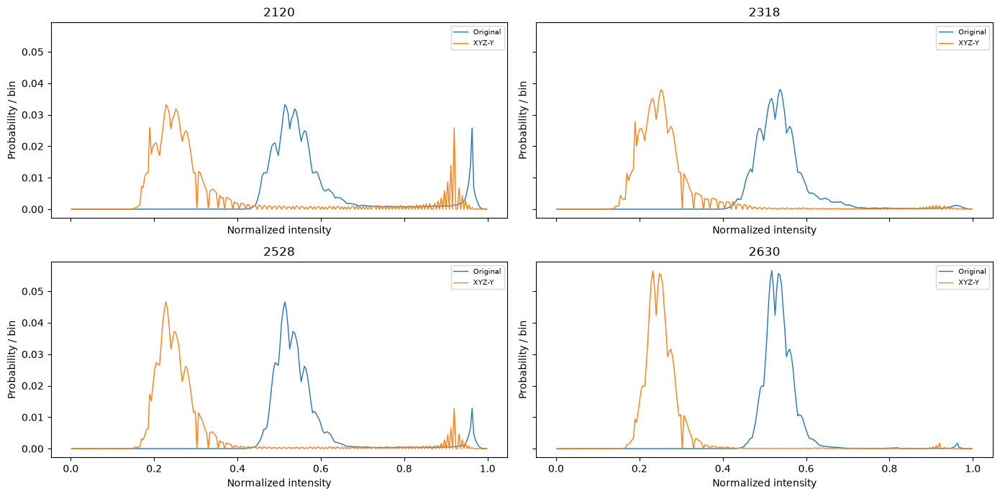

In [24]:
# Cell 24 — XYZ-Y histogram overlay
# Output: Original and representation probabilities on the same 256 bins.
overlays(['XYZ-Y'],'representation_XYZ-Y_histograms')


,method,roi_status,between,within_animal,within_background,margin,histogram_change,mean_edge_strength,endpoint_fraction,background_edge_strength
0,Original,confirmed,0.661588,0.200011,0.437106,0.343030,0.000000,0.013785,0.000028,0.010951
1,XYZ-Y,confirmed,0.661542,0.200001,0.436853,0.343115,0.942701,0.016351,0.000028,0.011088


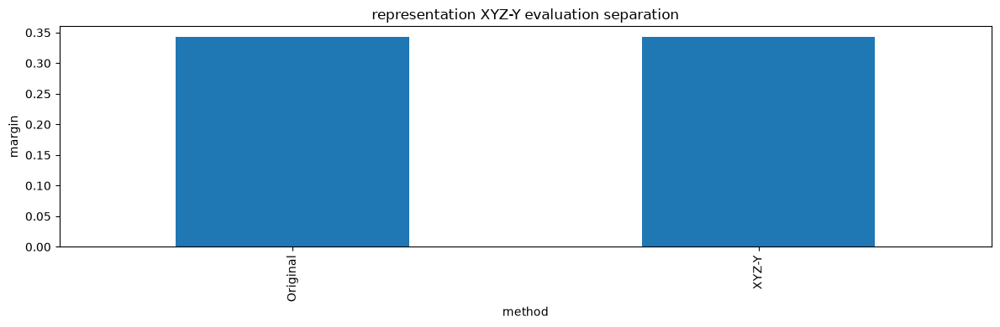

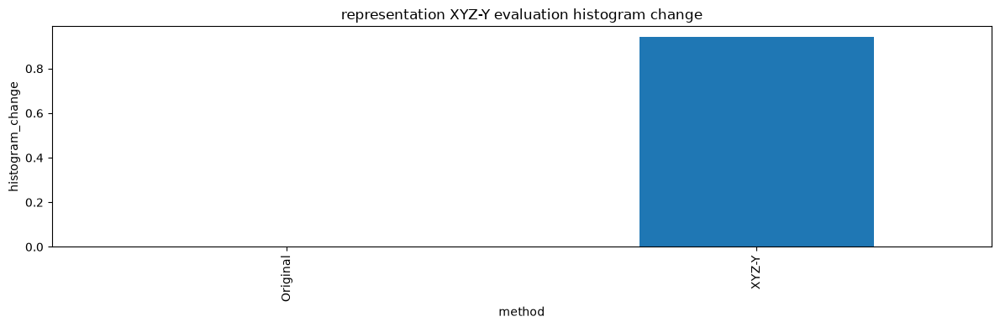

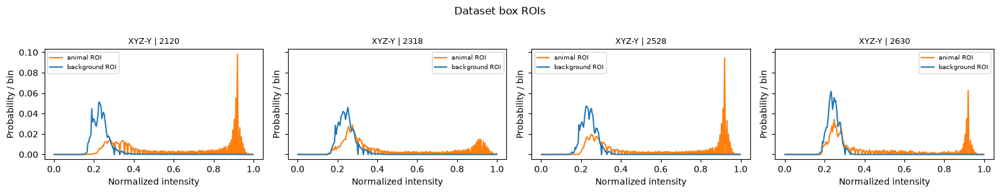

In [25]:
# Cell 25 — XYZ-Y animal/background evaluation
# Output: Separation table/charts and ROI histograms; using real dataset boxes.
evaluate(['Original','XYZ-Y'],'representation_XYZ-Y_evaluation')
roi_overlays(['XYZ-Y'],'representation_XYZ-Y_roi')


In [26]:
# Cell 26 — Lab-L* representation formula
# Output: Separate LaTeX formulas.
display(Math('f(t)=\\begin{cases}t^{1/3}&t>(6/29)^3\\\\t/[3(6/29)^2]+4/29&\\mathrm{otherwise}\\end{cases}\\quad L^*=116f(Y/Y_n)-16,\\quad u_L=L^*/100'))


<IPython.core.display.Math object>

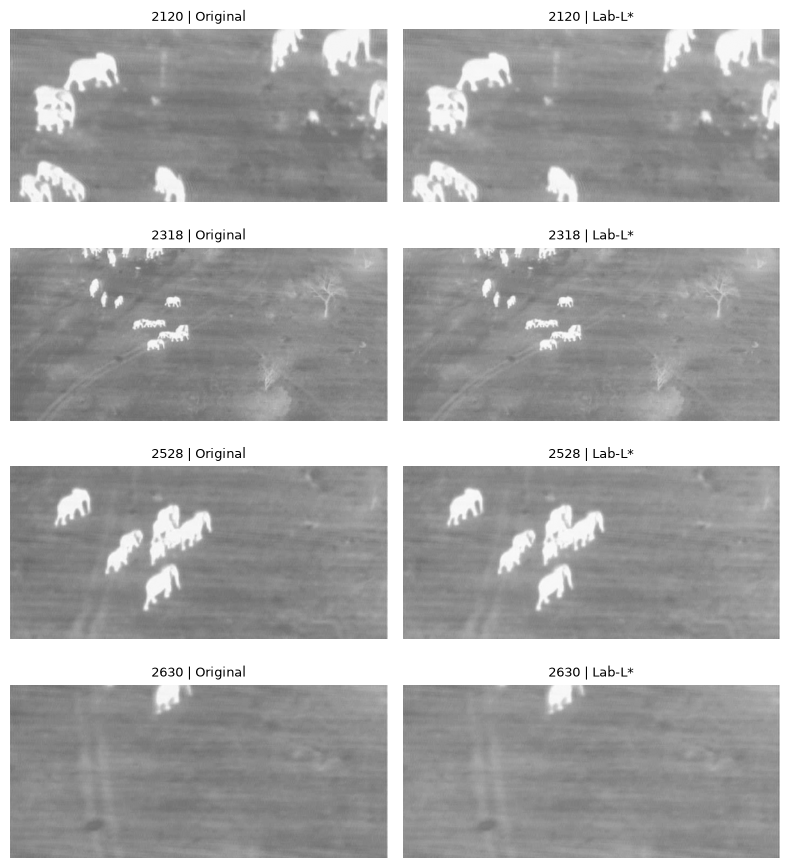

In [27]:
# Cell 27 — Lab-L* image comparison
# Output: Original and represented brightness for all four frames; shared [0,1] display.
# We use sRGB and D65 as math rules. We do not know the camera calibration.
register('Lab-L*',lambda a:color.rgb2lab(color.gray2rgb(a),illuminant='D65')[...,0]/100)
comparisons(['Lab-L*'],'representation_Lab-L_images')


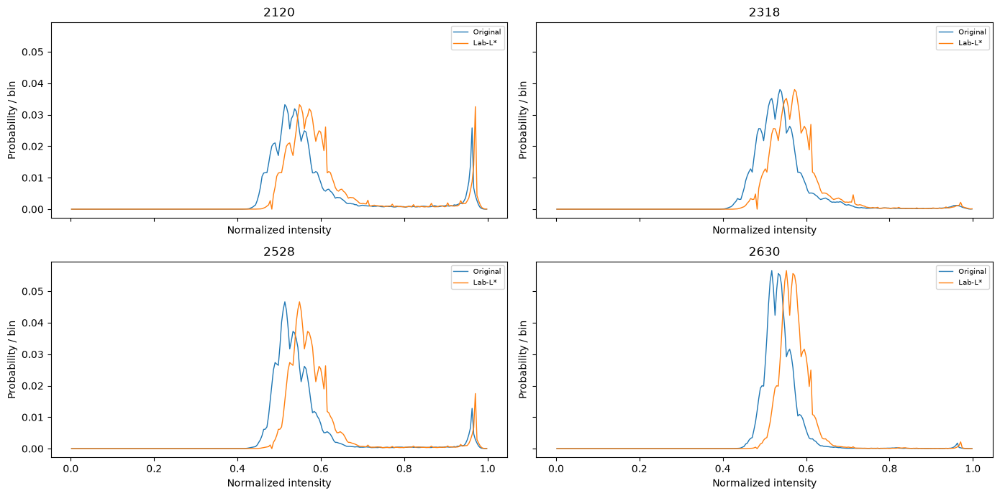

In [28]:
# Cell 28 — Lab-L* histogram overlay
# Output: Original and representation probabilities on the same 256 bins.
overlays(['Lab-L*'],'representation_Lab-L_histograms')


,method,roi_status,between,within_animal,within_background,margin,histogram_change,mean_edge_strength,endpoint_fraction,background_edge_strength
0,Original,confirmed,0.661588,0.200011,0.437106,0.343030,0.000000,0.013785,0.000028,0.010951
1,Lab-L*,confirmed,0.661283,0.196692,0.436989,0.344442,0.187777,0.013381,0.000028,0.010829


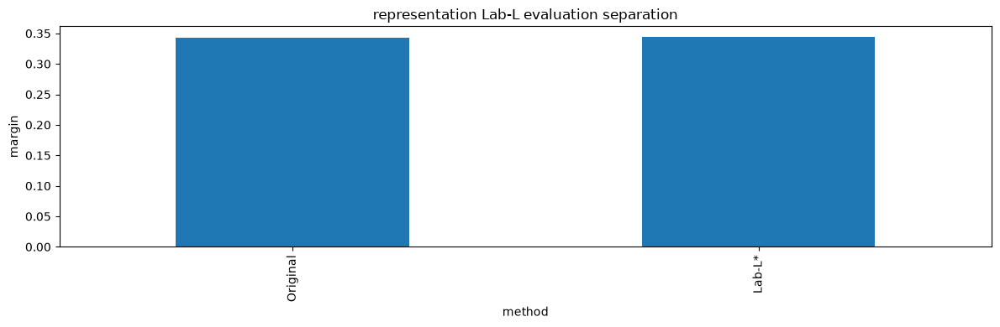

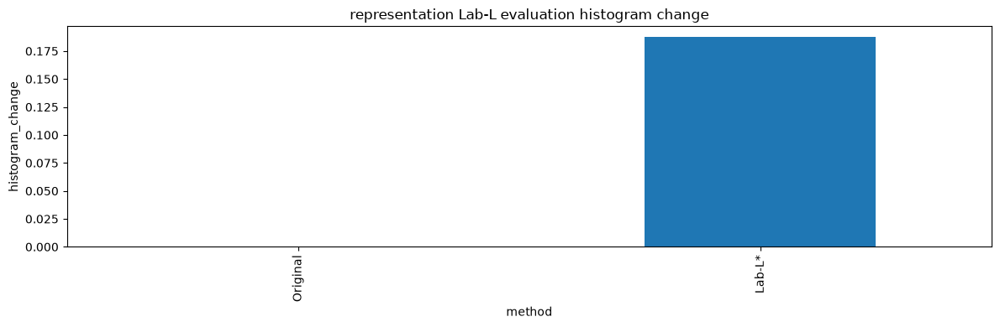

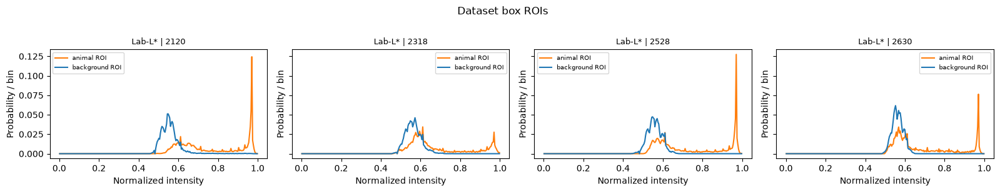

In [29]:
# Cell 29 — Lab-L* animal/background evaluation
# Output: Separation table/charts and ROI histograms; using real dataset boxes.
evaluate(['Original','Lab-L*'],'representation_Lab-L_evaluation')
roi_overlays(['Lab-L*'],'representation_Lab-L_roi')


In [30]:
# Cell 30 — Luv-L* representation formula
# Output: Separate LaTeX formulas.
display(Math('L^*_{Luv}=116f(Y/Y_n)-16=L^*_{Lab},\\qquad u_L=L^*/100'))


<IPython.core.display.Math object>

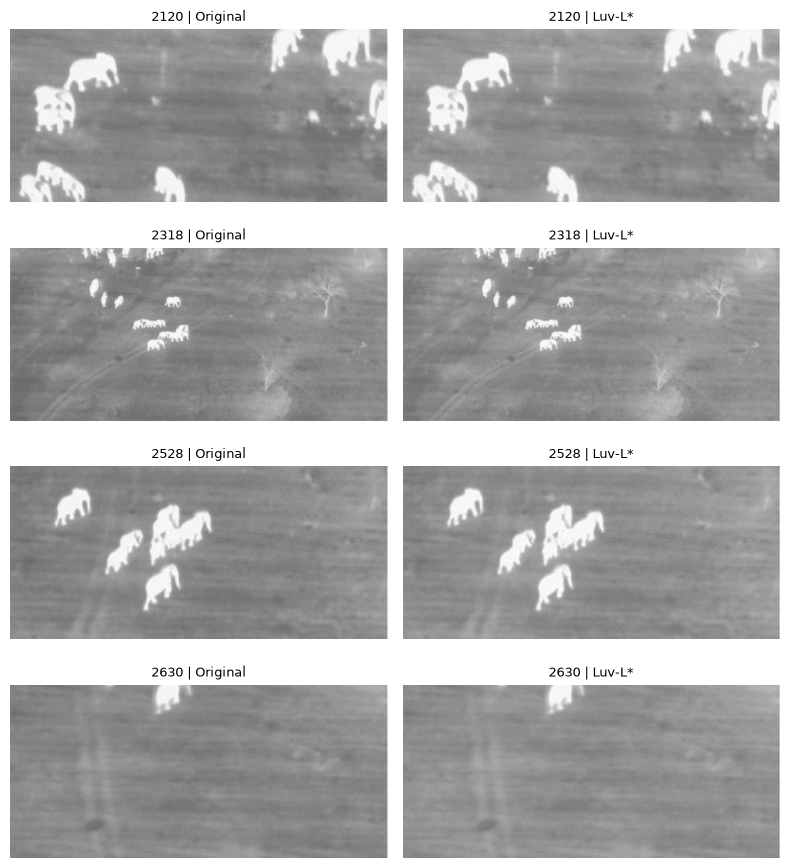

In [31]:
# Cell 31 — Luv-L* image comparison
# Output: Original and represented brightness for all four frames; shared [0,1] display.
# We use sRGB and D65 as math rules. We do not know the camera calibration.
register('Luv-L*',lambda a:color.rgb2luv(color.gray2rgb(a))[...,0]/100)
comparisons(['Luv-L*'],'representation_Luv-L_images')


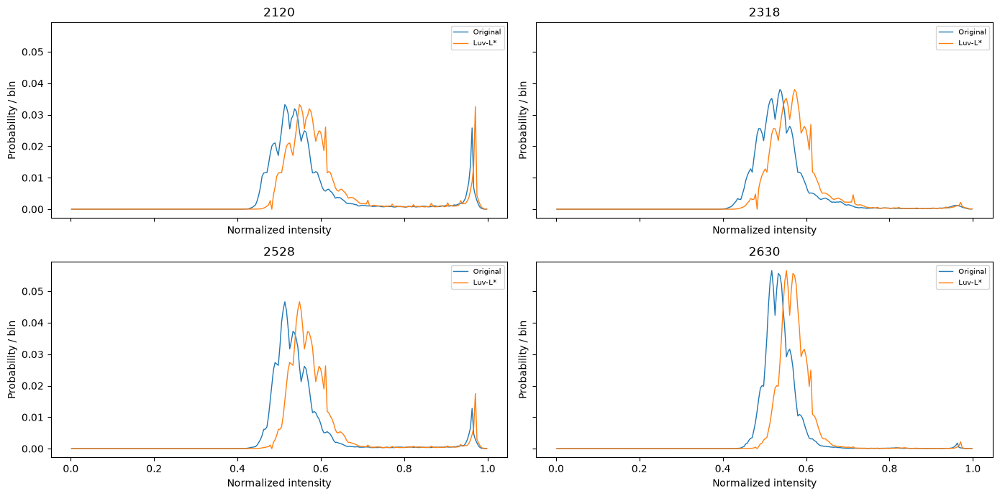

In [32]:
# Cell 32 — Luv-L* histogram overlay
# Output: Original and representation probabilities on the same 256 bins.
overlays(['Luv-L*'],'representation_Luv-L_histograms')


,method,roi_status,between,within_animal,within_background,margin,histogram_change,mean_edge_strength,endpoint_fraction,background_edge_strength
0,Original,confirmed,0.661588,0.200011,0.437106,0.343030,0.000000,0.013785,0.000028,0.010951
1,Luv-L*,confirmed,0.661283,0.196692,0.436989,0.344442,0.187777,0.013381,0.000028,0.010829


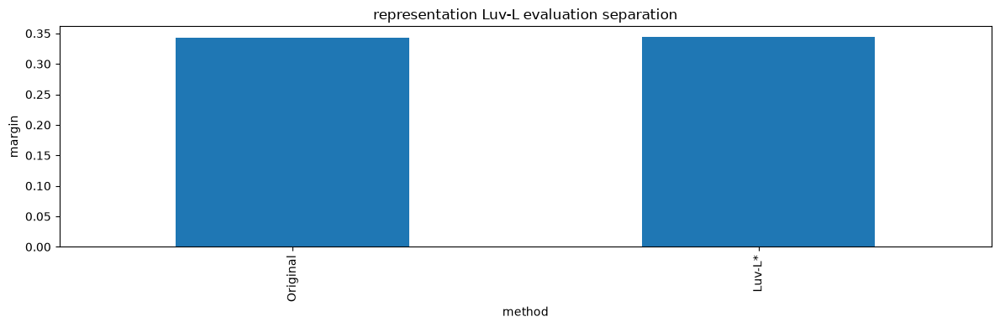

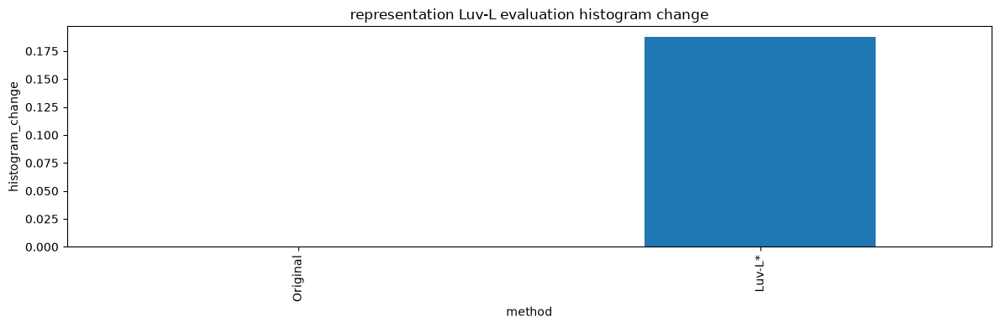

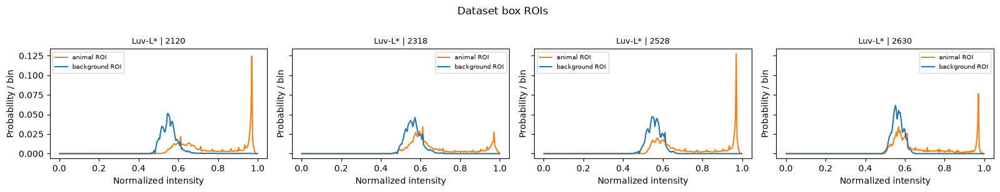

In [33]:
# Cell 33 — Luv-L* animal/background evaluation
# Output: Separation table/charts and ROI histograms; using real dataset boxes.
evaluate(['Original','Luv-L*'],'representation_Luv-L_evaluation')
roi_overlays(['Luv-L*'],'representation_Luv-L_roi')


In [34]:
# Cell 34 — Denoising formulas
# Output: Separate LaTeX formulas.
display(Math('G_\\sigma(x)=\\frac{e^{-\\|x\\|^2/(2\\sigma^2)}}{2\\pi\\sigma^2},\\quad J_G=G_\\sigma*I'))
display(Math('J_M(x)=\\mathrm{median}_{y\\in\\mathcal N(x)}I(y)'))
display(Math('J_{NLM}(x)=\\frac{\\sum_yw(x,y)I(y)}{\\sum_yw(x,y)},\\quad w(x,y)\\propto\\exp[-\\max(d^2(P_x,P_y)-2\\sigma_n^2,0)/h^2]'))


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

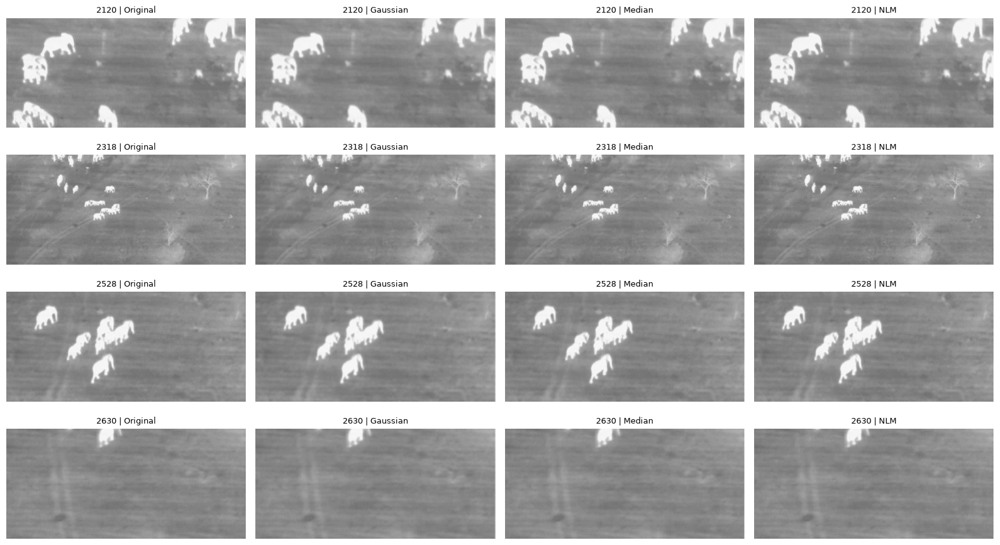

Estimated noise sigma: {'2120': 0.00392156862745098, '2318': 0.00392156862745098, '2528': 0.00392156862745098, '2630': 0.00392156862745098}


In [35]:
# Cell 35 — Apply denoising
# Output: Original/Gaussian/Median/NLM grids and estimated noise parameters.
# Do not add fake noise. The noise level below is only an estimate.
NOISE={k:max(float(restoration.estimate_sigma(a,channel_axis=None)),1/255) for k,a in images.items()}
register('Gaussian',lambda a:ndi.gaussian_filter(a,CFG['gaussian_sigma'],mode='reflect'))
register('Median',lambda a:ndi.median_filter(a,size=CFG['median_size'],mode='reflect'))
BANK['NLM']={k:restoration.denoise_nl_means(a,h=CFG['nlm_h_factor']*NOISE[k],sigma=NOISE[k],
                       patch_size=CFG['nlm_patch'],patch_distance=CFG['nlm_distance'],fast_mode=True,channel_axis=None) for k,a in images.items()}
DENOISE=['Original','Gaussian','Median','NLM']; GROUPS['Denoising']=DENOISE
comparisons(DENOISE,'denoising_images')
print('Estimated noise sigma:',NOISE)


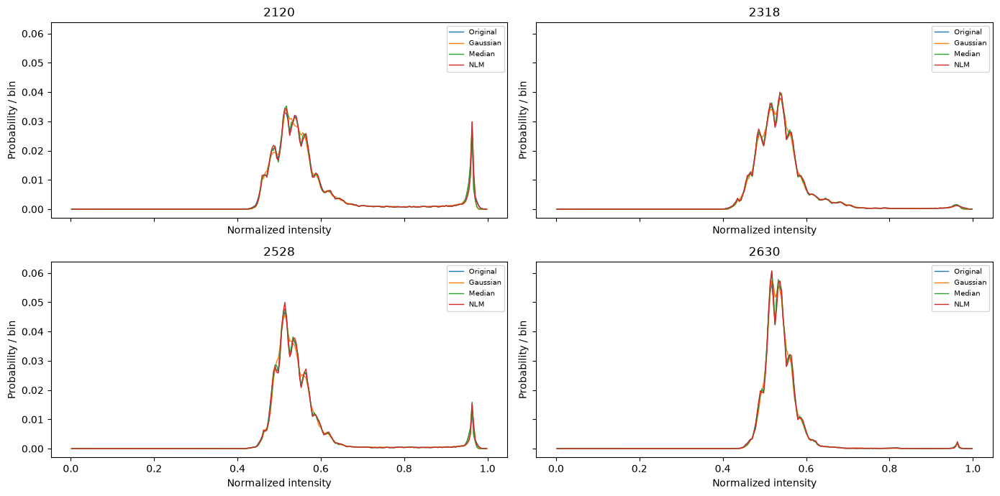

In [36]:
# Cell 36 — Denoising global overlays
# Output: Global normalized histogram overlays.
overlays(DENOISE,'denoising_histograms')


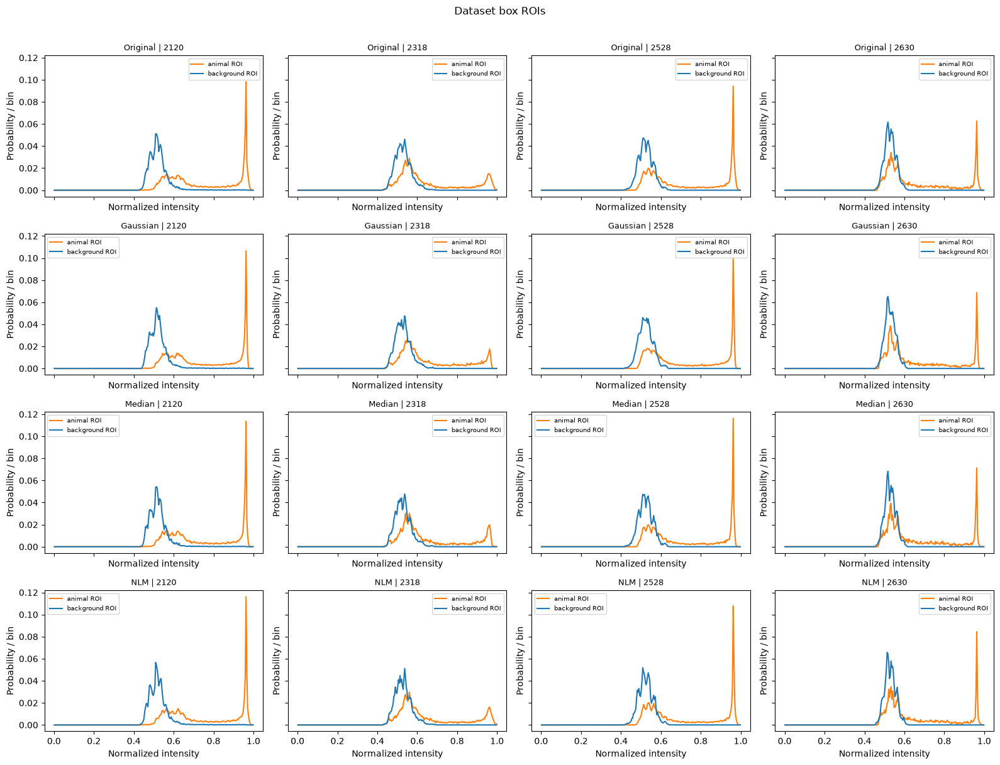

In [37]:
# Cell 37 — Denoising ROI overlays
# Output: Animal/background ROI histogram comparisons.
roi_overlays(DENOISE,'denoising_roi_histograms')


,method,roi_status,between,within_animal,within_background,margin,histogram_change,mean_edge_strength,endpoint_fraction,background_edge_strength
0,Original,confirmed,0.661588,0.200011,0.437106,0.343030,0.000000,0.013785,0.000028,0.010951
1,Gaussian,confirmed,0.703294,0.215817,0.498094,0.346339,0.003701,0.009842,0.000000,0.007116
2,Median,confirmed,0.693757,0.233264,0.486127,0.334061,0.001663,0.010913,0.000000,0.008004
3,NLM,confirmed,0.670555,0.209359,0.459588,0.336082,0.001246,0.012623,0.000026,0.009733


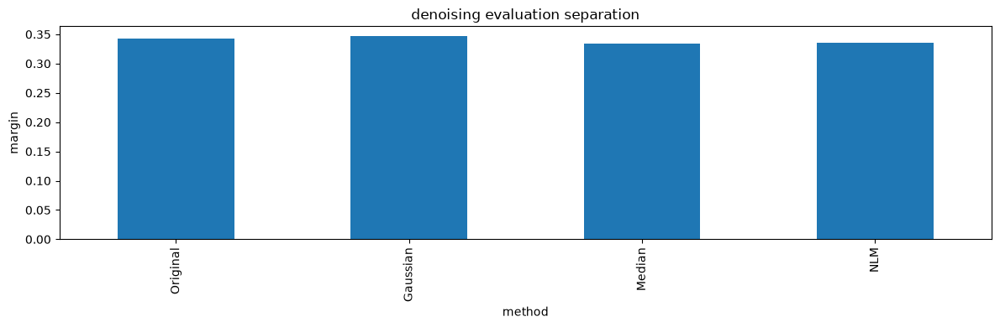

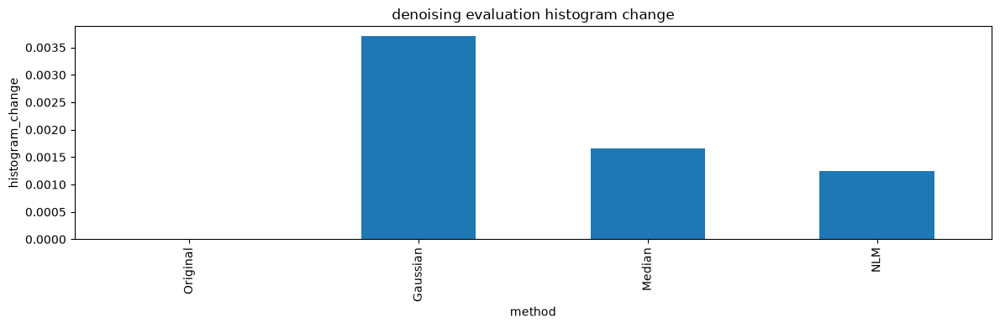

In [38]:
# Cell 38 — Denoising evaluation
# Output: Separation, histogram change, edge strength and endpoint fractions.
denoise_metrics=evaluate(DENOISE,'denoising_evaluation')


In [39]:
# Cell 39 — Denoising decision
# Output: Predeclared configuration; exploratory ranking only if labels are confirmed.
decision(denoise_metrics,CFG['selected_denoising'],'Denoising')


Denoising: predeclared setting = NLM. No automatic winner claimed.


,method,margin
1,Gaussian,0.346339
0,Original,0.343030
3,NLM,0.336082
2,Median,0.334061


Margin ranking uses train/validation dataset boxes; it is exploratory.


In [40]:
# Cell 40 — Original minus Gaussian: formula
# Output: A separate formula. Small sigma shows fine detail; large sigma removes slow background changes.
display(Math(r'G_\sigma=\mathrm{GaussianFilter}(I,\sigma),\quad D_\sigma=I-G_\sigma,\quad \sigma\in\{1,24\}\ \mathrm{pixels}'))
display(Math(r'S_\sigma=(D_\sigma+1)/2,\quad D_\sigma=0\Rightarrow S_\sigma=0.5'))


<IPython.core.display.Math object>

<IPython.core.display.Math object>

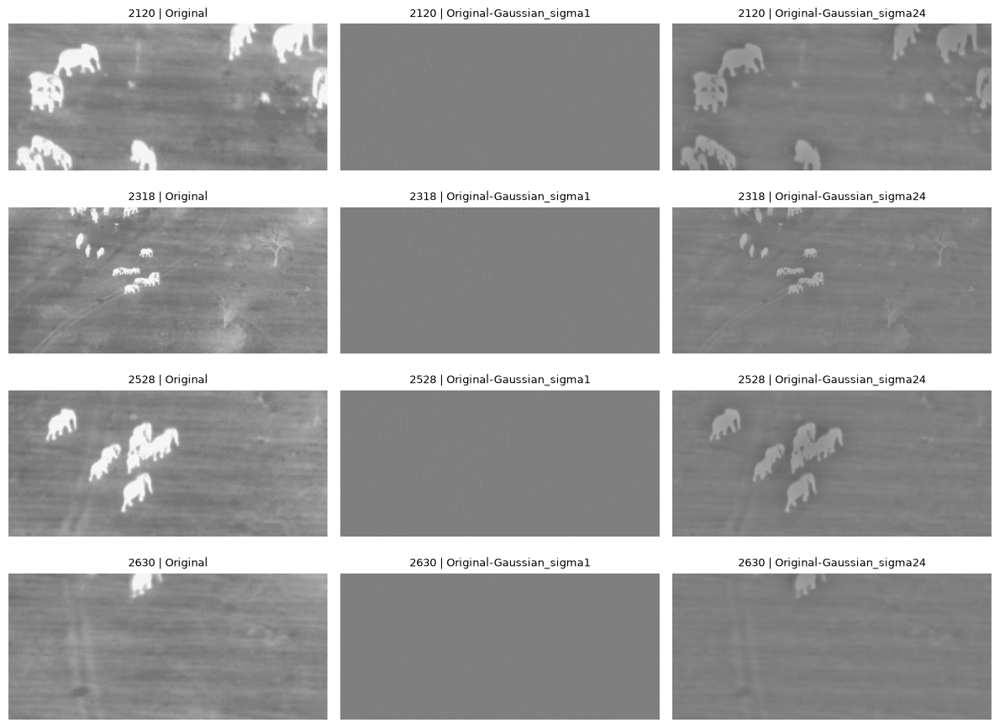

Original is brightness. Difference images are signed changes; gray 0.5 means no change.


In [41]:
# Cell 41 — Original minus Gaussian: images
# Output: Original and two Gaussian residuals together for all four photos.
# sigma=1 subtracts the denoised image. sigma=24 subtracts a broad background guess.
# Keep signed values. White and dark changes both matter.
GAUSSIAN_RESIDUAL={}
for sigma in [1,24]:
    name=f'Original-Gaussian_sigma{sigma}'
    GAUSSIAN_RESIDUAL[name]={k:a-ndi.gaussian_filter(a,sigma,mode='reflect') for k,a in images.items()}
    BANK[name]={k:(d+1)/2 for k,d in GAUSSIAN_RESIDUAL[name].items()}
HP=['Original','Original-Gaussian_sigma1','Original-Gaussian_sigma24']
GROUPS['Original minus Gaussian']=HP
comparisons(HP,'original_minus_gaussian_images')
print('Original is brightness. Difference images are signed changes; gray 0.5 means no change.')


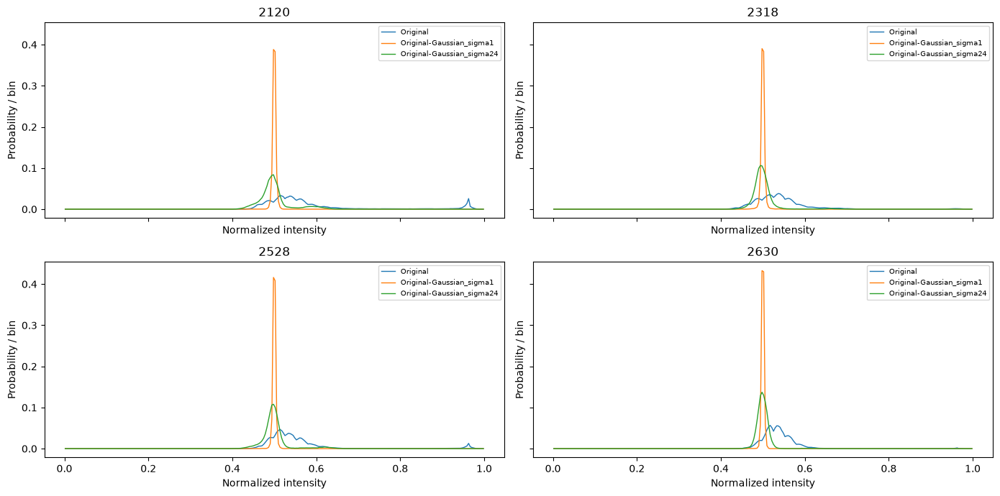

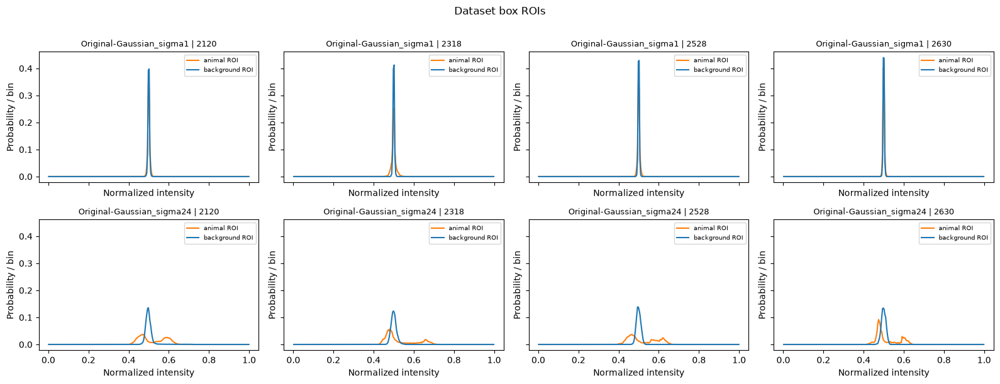

In [42]:
# Cell 42 — Original minus Gaussian: histograms
# Output: Original/processed overlays and animal/background overlays.
overlays(HP,'original_minus_gaussian_histograms')
roi_overlays(HP[1:],'original_minus_gaussian_class_histograms')


,method,roi_status,between,within_animal,within_background,margin,histogram_change,mean_edge_strength,endpoint_fraction,background_edge_strength
0,Original,confirmed,0.661588,0.200011,0.437106,0.343030,0.000000,0.013785,0.000028,0.010951
1,Original-Gaussian_sigma1,confirmed,0.112184,0.050780,0.018913,0.077337,0.769032,0.002994,0.000000,0.002736
2,Original-Gaussian_sigma24,confirmed,0.651492,0.251650,0.184075,0.433630,0.382019,0.006844,0.000000,0.005449


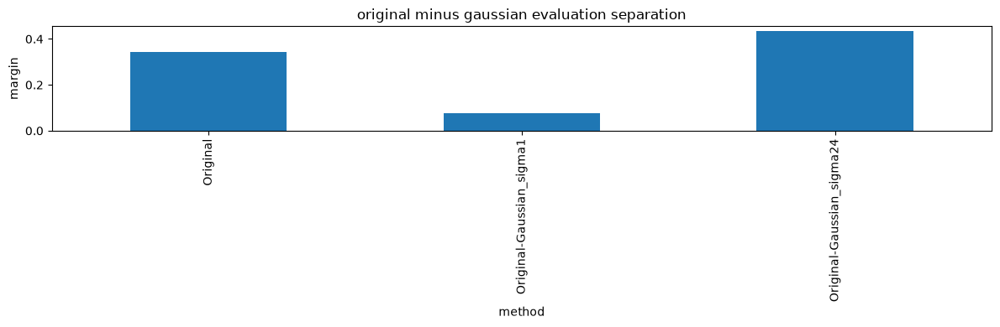

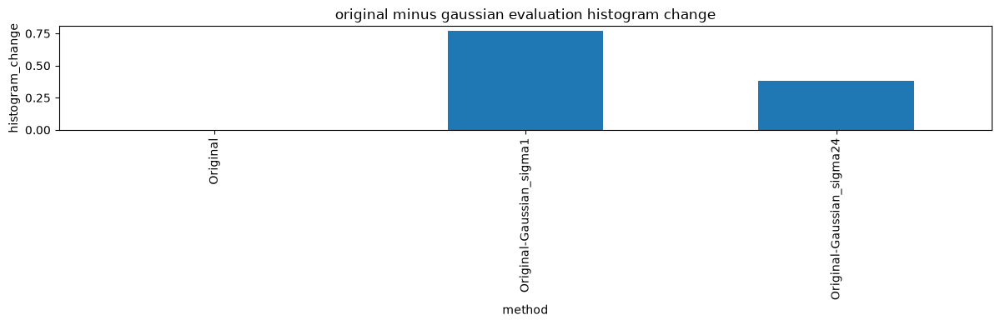

A small histogram change is not a better score. Look at class separation and the later test accuracy.
sigma=24 is the same operation as Gray + GaussianBG + Subtraction. We count it once in the big comparison.


In [43]:
# Cell 43 — Original minus Gaussian: evaluation
# Output: Real-box separation distances, margin, and charts.
hp_metrics=evaluate(HP,'original_minus_gaussian_evaluation')
print('A small histogram change is not a better score. Look at class separation and the later test accuracy.')
print('sigma=24 is the same operation as Gray + GaussianBG + Subtraction. We count it once in the big comparison.')


In [44]:
# Cell 44 — Sharpening formulas
# Output: Separate LaTeX formulas.
display(Math('J_U=\\mathrm{clip}_{[0,1]}\\{I+\\alpha(I-G_\\sigma*I)\\}'))
display(Math('\\Delta I=I_{x+1,y}+I_{x-1,y}+I_{x,y+1}+I_{x,y-1}-4I_{x,y},\\quad J_L=\\mathrm{clip}_{[0,1]}(I-\\beta\\Delta I)'))


<IPython.core.display.Math object>

<IPython.core.display.Math object>

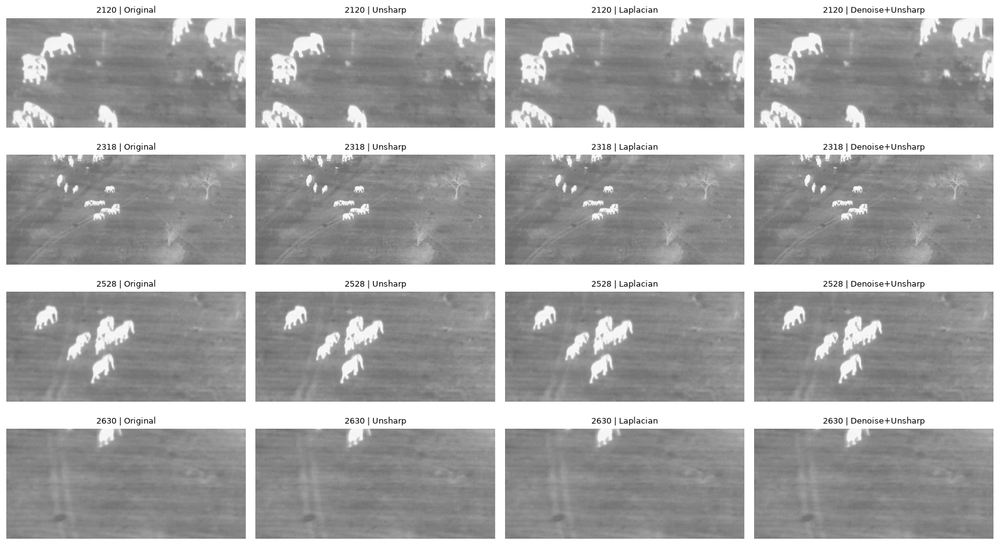

In [45]:
# Cell 45 — Apply sharpening
# Output: Original and three sharpening alternatives.
def unsharp(a): return np.clip(a+CFG['unsharp_amount']*(a-ndi.gaussian_filter(a,CFG['gaussian_sigma'],mode='reflect')),0,1)
register('Unsharp',unsharp)
register('Laplacian',lambda a:np.clip(a-CFG['laplacian_amount']*ndi.laplace(a,mode='reflect'),0,1))
BANK['Denoise+Unsharp']={k:unsharp(a) for k,a in BANK[CFG['selected_denoising']].items()}
SHARP=['Original','Unsharp','Laplacian','Denoise+Unsharp']; GROUPS['Sharpening']=SHARP
comparisons(SHARP,'sharpening_images')


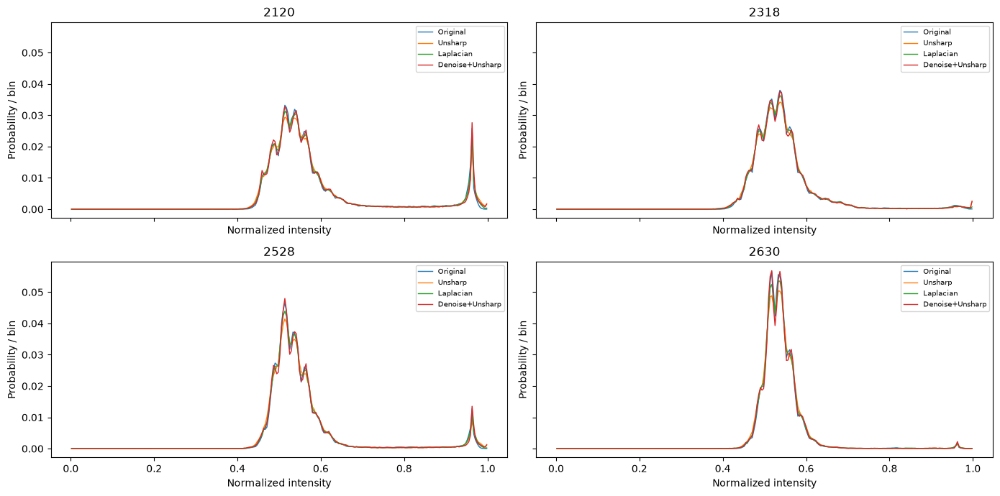

In [46]:
# Cell 46 — Sharpening global overlays
# Output: Global histogram overlays.
overlays(SHARP,'sharpening_histograms')


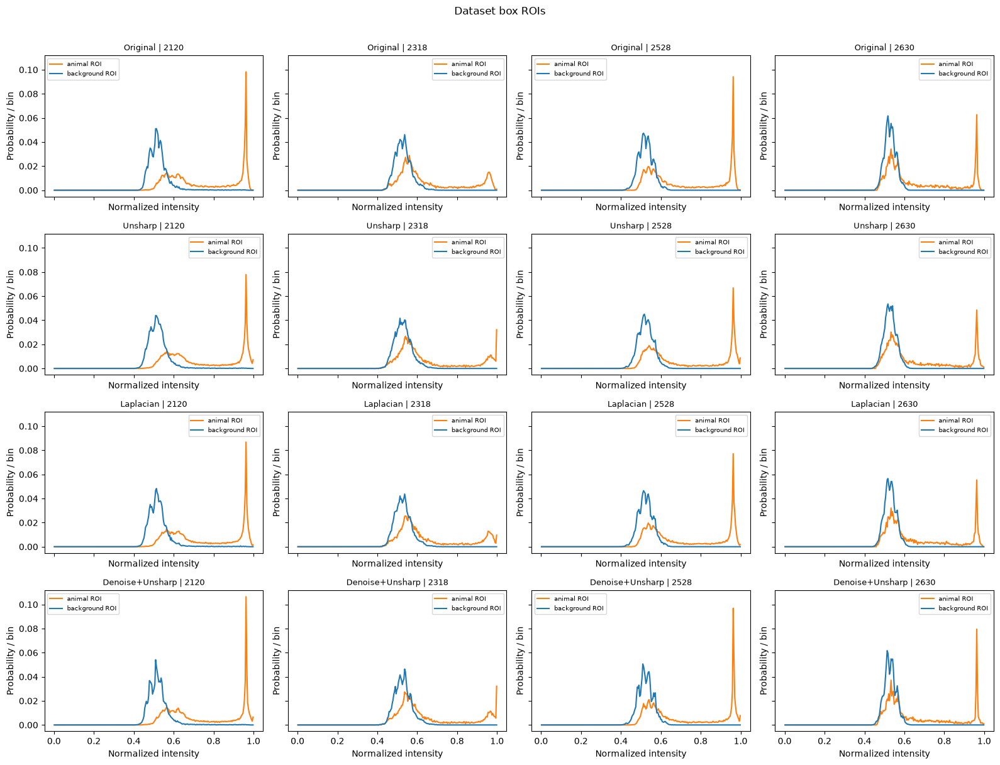

In [47]:
# Cell 47 — Sharpening ROI overlays
# Output: Animal/background ROI histograms.
roi_overlays(SHARP,'sharpening_roi_histograms')


,method,roi_status,between,within_animal,within_background,margin,histogram_change,mean_edge_strength,endpoint_fraction,background_edge_strength
0,Original,confirmed,0.661588,0.200011,0.437106,0.343030,0.000000,0.013785,0.000028,0.010951
1,Unsharp,confirmed,0.608649,0.190496,0.372969,0.326916,0.006143,0.018788,0.001044,0.015779
2,Laplacian,confirmed,0.637509,0.192370,0.405089,0.338780,0.002127,0.015886,0.000215,0.013079
3,Denoise+Unsharp,confirmed,0.624662,0.203040,0.408569,0.318857,0.004495,0.016635,0.000985,0.013525


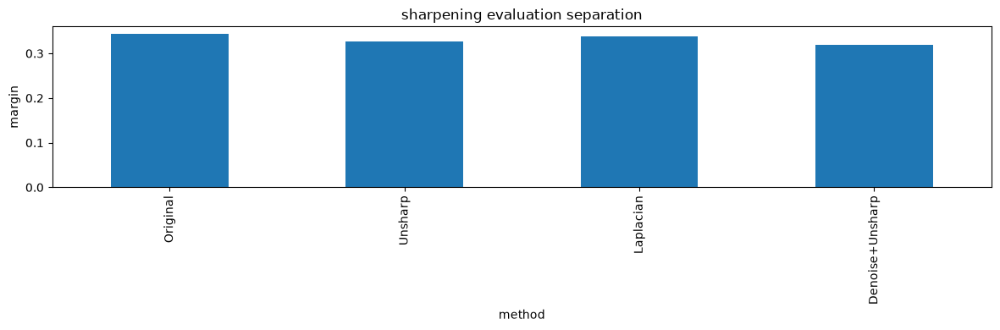

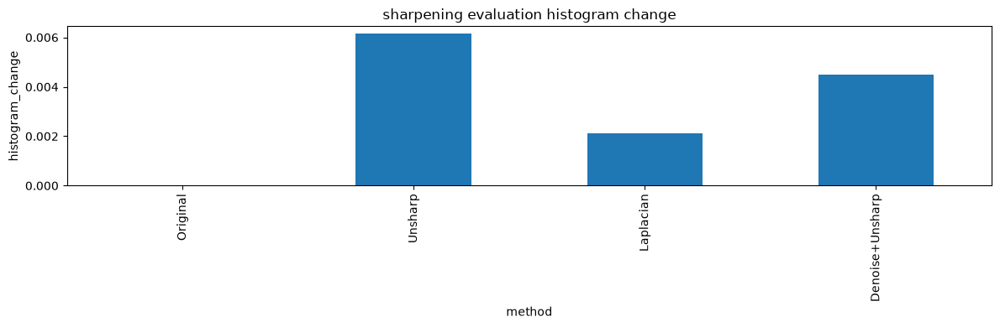

In [48]:
# Cell 48 — Sharpening evaluation
# Output: Separation, edge strength, background edge amplification and clipping.
sharp_metrics=evaluate(SHARP,'sharpening_evaluation')


In [49]:
# Cell 49 — Sharpening decision
# Output: No sharpening retained as a valid option; no forced winner.
decision(sharp_metrics,'Original (no sharpening)','Sharpening')


Sharpening: predeclared setting = Original (no sharpening). No automatic winner claimed.


,method,margin
0,Original,0.343030
2,Laplacian,0.338780
1,Unsharp,0.326916
3,Denoise+Unsharp,0.318857


Margin ranking uses train/validation dataset boxes; it is exploratory.


In [50]:
# Cell 50 — Logarithmic intensity formula
# Output: Separate LaTeX formulas.
display(Math('J_{log}(u)=\\frac{\\log(1+au)}{\\log(1+a)},\\qquad a>0,\\quad u\\in[0,1]'))


<IPython.core.display.Math object>

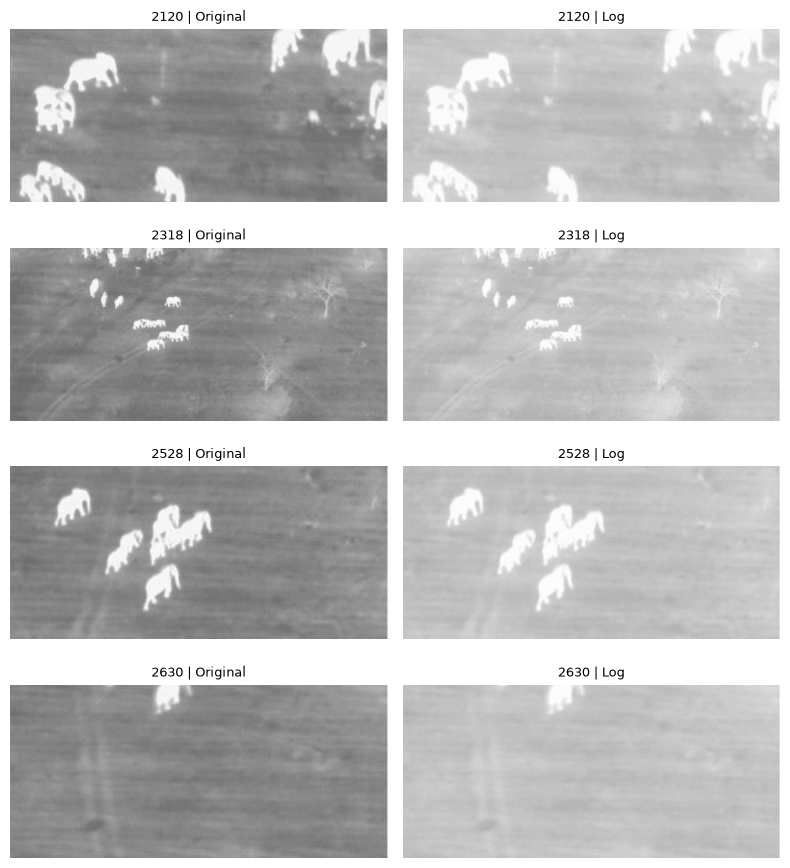

In [51]:
# Cell 51 — Logarithmic intensity image comparison
# Output: Original/log images with global, fixed range normalization.
register('Log',lambda a:np.log1p(CFG['log_alpha']*a)/np.log1p(CFG['log_alpha']))
comparisons(['Log'],'log_images')


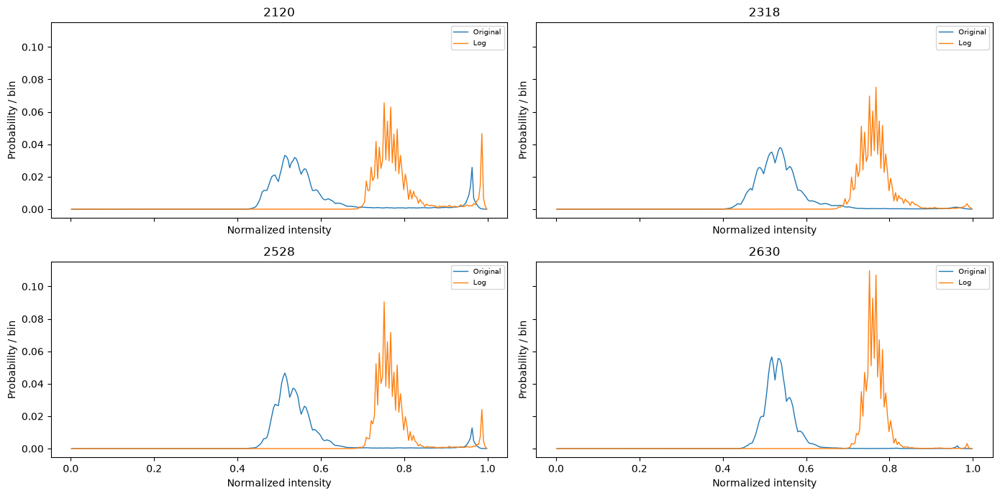

In [52]:
# Cell 52 — Logarithmic histogram overlays
# Output: Original/log normalized histograms.
overlays(['Log'],'log_histograms')


,method,roi_status,between,within_animal,within_background,margin,histogram_change,mean_edge_strength,endpoint_fraction,background_edge_strength
0,Original,confirmed,0.661588,0.200011,0.437106,0.34303,0.000000,0.013785,0.000028,0.010951
1,Log,confirmed,0.658190,0.183975,0.432826,0.34979,0.932128,0.008617,0.000028,0.007408


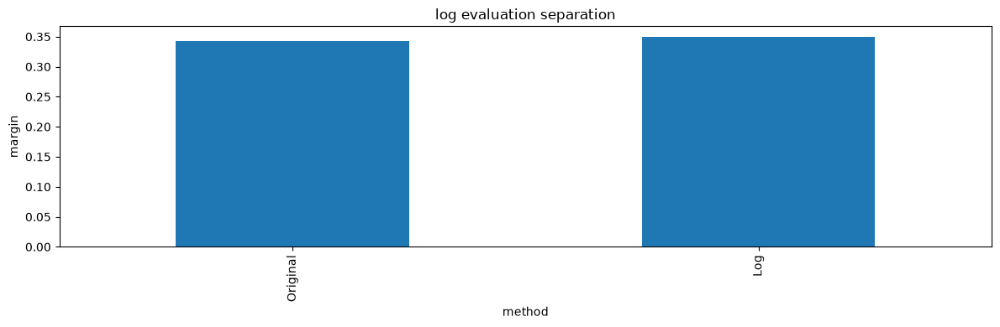

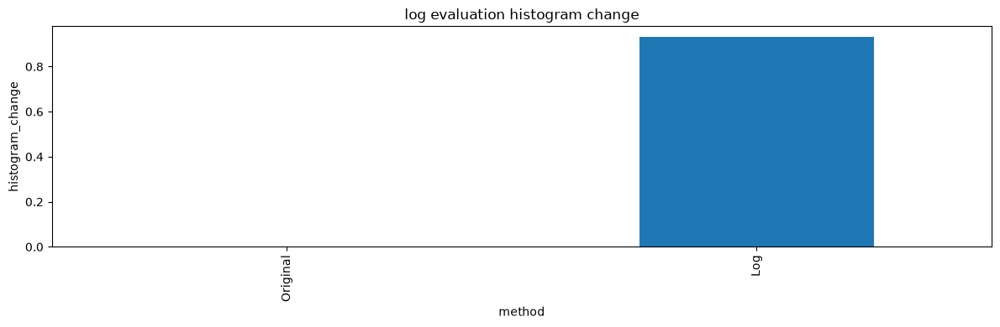

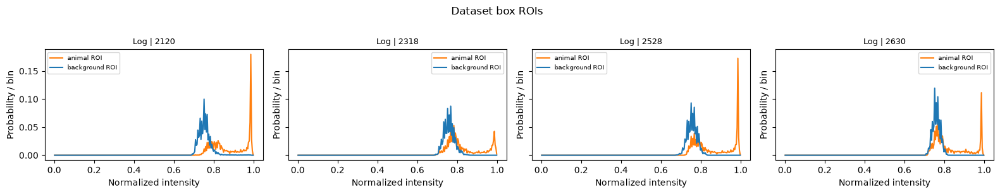

In [53]:
# Cell 53 — Logarithmic evaluation
# Output: Animal/background metrics and ROI distributions.
log_metrics=evaluate(['Original','Log'],'log_evaluation')
roi_overlays(['Log'],'log_roi_histograms')


In [54]:
# Cell 54 — Explicit PLIP special-case convention
# Output: Separate LaTeX formulas.
display(Math('g=1-u,\\quad T_c(g)=M[1-(1-g/M)^c],\\quad J_{PLIP}=1-T_c(1-u)'))
display(Math('\\phi(g)=-M\\log(1-g/M),\\quad \\phi^{-1}(z)=M(1-e^{-z/M}),\\qquad M>1'))


<IPython.core.display.Math object>

<IPython.core.display.Math object>

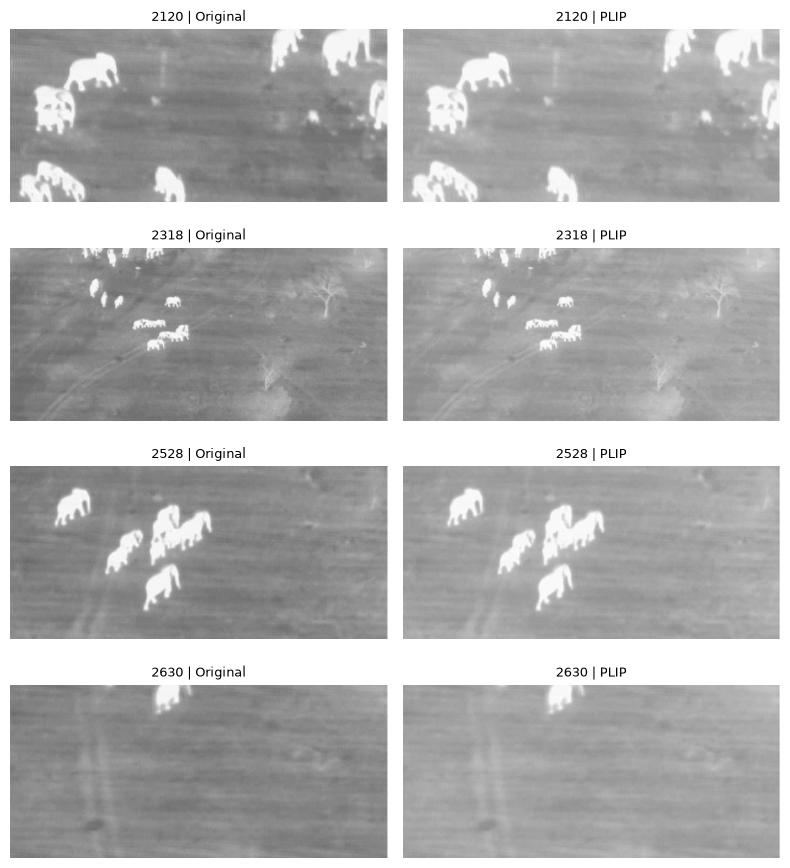

In [55]:
# Cell 55 — PLIP intensity image comparison
# Output: Original/PLIP intensity comparison; explicit graytone convention.
# Here we set gamma=k=lambda=M and beta=1 for PLIP.
# g=1-u means darkness. u means brightness. Do not swap them. Oops-proof rule!
# This is one PLIP version. Your class may use a different one.
# Source: https://patents.google.com/patent/US8285076B2/en (PLIP arithmetic definitions).
# If your class uses other values, change both the formula and the code.
M=CFG['plip_M']
def plip_transform(a):
    g=1-a; return np.clip(1-M*(1-(1-g/M)**CFG['plip_power']),0,1)
register('PLIP',plip_transform)
comparisons(['PLIP'],'plip_images')


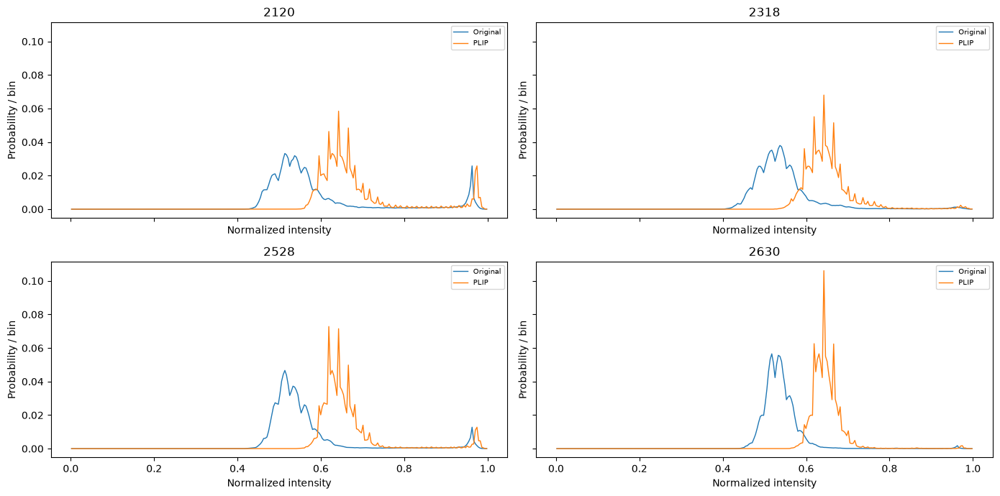

In [56]:
# Cell 56 — PLIP histogram overlays
# Output: Original/PLIP probability overlays.
overlays(['PLIP'],'plip_histograms')


,method,roi_status,between,within_animal,within_background,margin,histogram_change,mean_edge_strength,endpoint_fraction,background_edge_strength
0,Original,confirmed,0.661588,0.200011,0.437106,0.343030,0.000000,0.013785,0.000028,0.010951
1,PLIP,confirmed,0.660050,0.192986,0.434848,0.346133,0.746257,0.011293,0.000028,0.009240


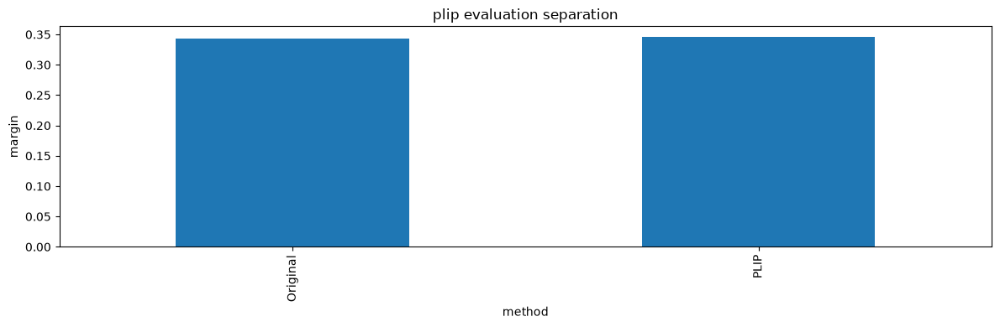

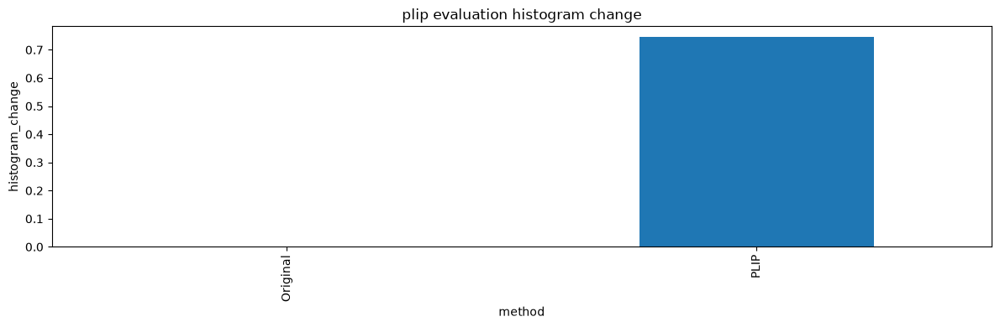

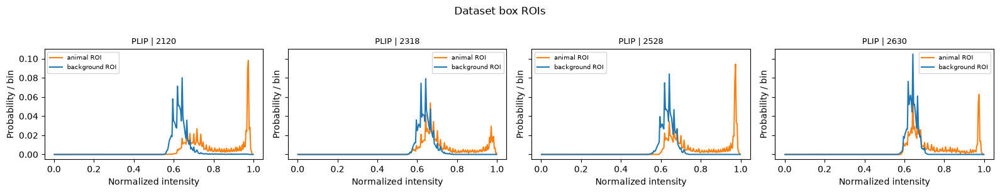

In [57]:
# Cell 57 — PLIP evaluation
# Output: Guarded separation and descriptive intensity statistics.
plip_metrics=evaluate(['Original','PLIP'],'plip_evaluation')
roi_overlays(['PLIP'],'plip_roi_histograms')


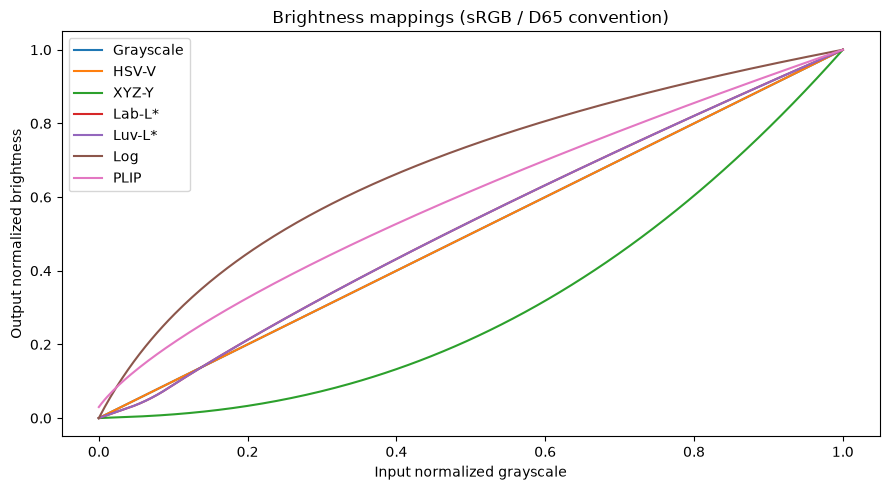

,frame,representation,spearman_rank,rank_image_max_error,maximum_change
0,2120,Grayscale,1.0,0.0,0.000000
1,2120,HSV-V,1.0,0.0,0.000000
2,2120,XYZ-Y,1.0,0.0,0.287132
3,2120,Lab-L*,1.0,0.0,0.033889
4,2120,Luv-L*,1.0,0.0,0.033889
5,2120,Log,1.0,0.0,0.262758
6,2120,PLIP,1.0,0.0,0.127335
7,2318,Grayscale,1.0,0.0,0.000000
8,2318,HSV-V,1.0,0.0,0.000000
9,2318,XYZ-Y,1.0,0.0,0.287132


HSV-V equals grayscale; Lab-L* and Luv-L* share lightness. Monotone remapping cannot add scene information.
Fixed-bin distance changes can result from re-binning. Rank-controlled matching is evaluated later.


In [58]:
# Cell 58 — Mapping curves and equivalence audit
# Output: Mapping curves, equivalence assertions and rank-invariance diagnostics.
# We only have gray JPGs. XYZ-Y comes from our sRGB math rule.
# It is not measured real-world light. Copying gray to RGB does not make new colors.
# Library help: https://scikit-image.org/docs/stable/api/skimage.color.html
REPRESENTATIONS=['Grayscale','HSV-V','XYZ-Y','Lab-L*','Luv-L*','Log','PLIP']
GROUPS['Luminance']=REPRESENTATIONS
u=np.linspace(0,1,256).reshape(1,-1); rgb=color.gray2rgb(u)
maps={'Grayscale':u,'HSV-V':color.rgb2hsv(rgb)[...,2], 'XYZ-Y':color.rgb2xyz(rgb)[...,1],
      'Lab-L*':color.rgb2lab(rgb)[...,0]/100,'Luv-L*':color.rgb2luv(rgb)[...,0]/100,
      'Log':np.log1p(CFG['log_alpha']*u)/np.log1p(CFG['log_alpha']),'PLIP':plip_transform(u)}
fig,ax=plt.subplots(figsize=(9,5))
for name,v in maps.items(): ax.plot(u.ravel(),v.ravel(),label=name)
ax.set(xlabel='Input normalized grayscale',ylabel='Output normalized brightness',title='Brightness mappings (sRGB / D65 convention)')
ax.legend(); savefig('representation_mapping_curves')
rows=[]
for k in IDS:
    assert np.allclose(BANK['HSV-V'][k],images[k],atol=1e-12)
    assert np.allclose(BANK['Lab-L*'][k],BANK['Luv-L*'][k],atol=2e-5)
    for name in REPRESENTATIONS:
        a=BANK[name][k]
        rows.append(dict(frame=k,representation=name,spearman_rank=spearmanr(images[k].ravel(),a.ravel()).statistic,
                         rank_image_max_error=float(np.max(np.abs(rank_image(images[k])-rank_image(a)))),
                         maximum_change=float(np.max(np.abs(a-images[k])))))
table(pd.DataFrame(rows),'remapping_equivalence_audit')
print('HSV-V equals grayscale; Lab-L* and Luv-L* share lightness. Monotone remapping cannot add scene information.')
print('Fixed-bin distance changes can result from re-binning. Rank-controlled matching is evaluated later.')


In [59]:
# Cell 59 — Single-image background estimation setup
# Output: Three brightness representations × two single-image estimators; no alignment assumption.
# The views do not line up. Do not subtract one photo from another.
# Guess the background from the same photo. It is not a real empty-scene photo.
# Use a blur or shape larger than an animal. Check if the animal leaks into the guess.
BASE_REPS={'Gray':'Original','XYZ-Y':'XYZ-Y','Lab-L*':'Lab-L*'}
BACKGROUND={}; SUPPRESSION={}; RAW_RESIDUALS={}
for rep,base in BASE_REPS.items():
    for est in ['GaussianBG','OpeningBG']:
        BACKGROUND[(rep,est)]={k:(ndi.gaussian_filter(a,CFG['background_sigma'],mode='reflect') if est=='GaussianBG'
                                  else ndi.grey_opening(a,size=(CFG['opening_size'],CFG['opening_size']),mode='reflect'))
                               for k,a in BANK[base].items()}
print('Single-image estimates: large Gaussian smoothing and flat grayscale morphological opening.')
print('No temporal change, motion or true foreground claims are supported by these estimates.')


Single-image estimates: large Gaussian smoothing and flat grayscale morphological opening.
No temporal change, motion or true foreground claims are supported by these estimates.


In [60]:
# Cell 60 — Single-image background estimation formulas
# Output: Separate LaTeX formulas.
display(Math('\\widehat B_G=G_{\\sigma_B}*u,\\quad \\widehat B_O=(u\\ominus S)\\oplus S\\quad\\mathrm{(morphological\\ opening)}'))
display(Math('\\sigma_B=24\\ \\mathrm{pixels},\\quad S=65\\times65\\ \\mathrm{pixels}\\quad\\mathrm{(editable\\ defaults)}'))


<IPython.core.display.Math object>

<IPython.core.display.Math object>

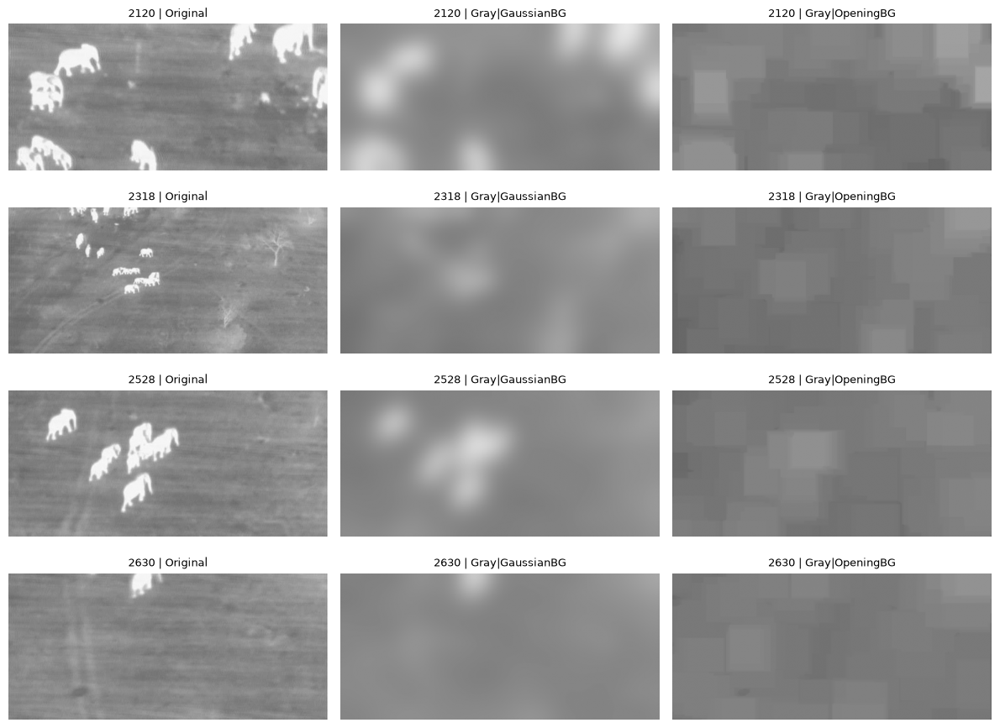

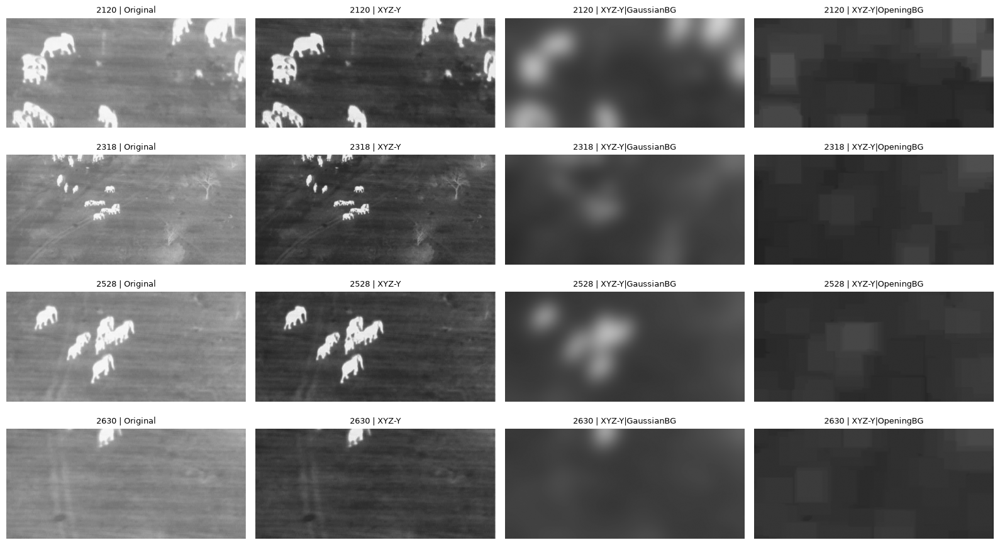

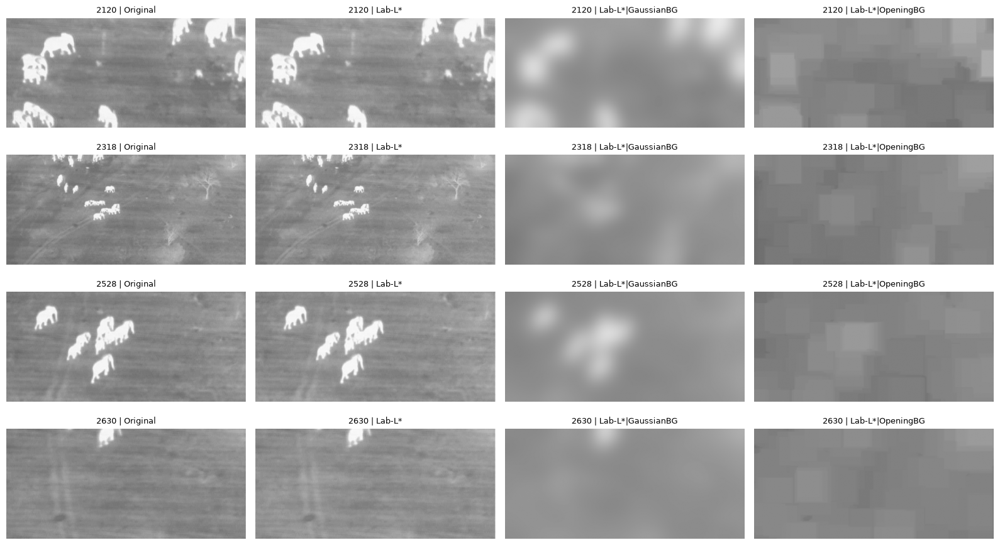

In [61]:
# Cell 61 — Inspect estimated backgrounds
# Output: Original, representation and both estimated backgrounds for every frame.
for rep,base in BASE_REPS.items():
    names=[base]
    for est in ['GaussianBG','OpeningBG']:
        name=f'{rep}|{est}'; BANK[name]=BACKGROUND[(rep,est)]; names.append(name)
    comparisons(names,f'background_estimates_{rep}')


In [62]:
# Cell 62 — Subtraction, PLIP difference and ratio formulas
# Output: Separate LaTeX formulas.
display(Math('d=u-\\widehat B,\\quad s_{sub}=\\frac{d+1}{2}\\quad\\mathrm{(zero\\ residual\\ maps\\ to\\ }0.5\\mathrm{)}'))
display(Math('g=1-u,\\quad b=1-\\widehat B,\\quad b\\ominus_{PLIP}g=\\frac{M(b-g)}{M-g}=\\frac{M(u-\\widehat B)}{M-1+u},\\quad s_{PLIP}=\\frac12\\left(1+\\frac{d_{PLIP}}{1+|d_{PLIP}|}\\right)'))
display(Math('q=\\log\\frac{u+\\epsilon}{\\widehat B+\\epsilon},\\quad s_{ratio}=\\frac{1+\\tanh(q/\\tau)}2'))


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

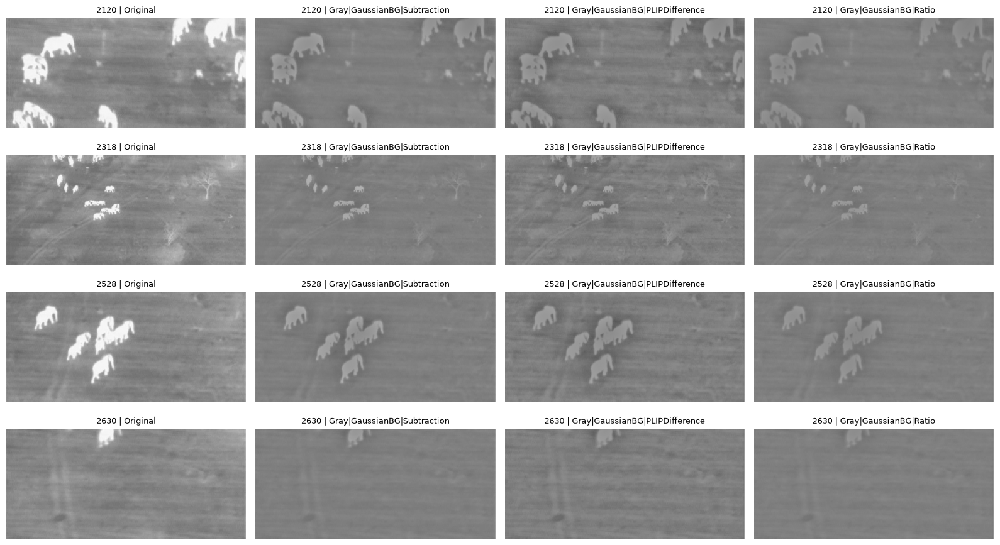

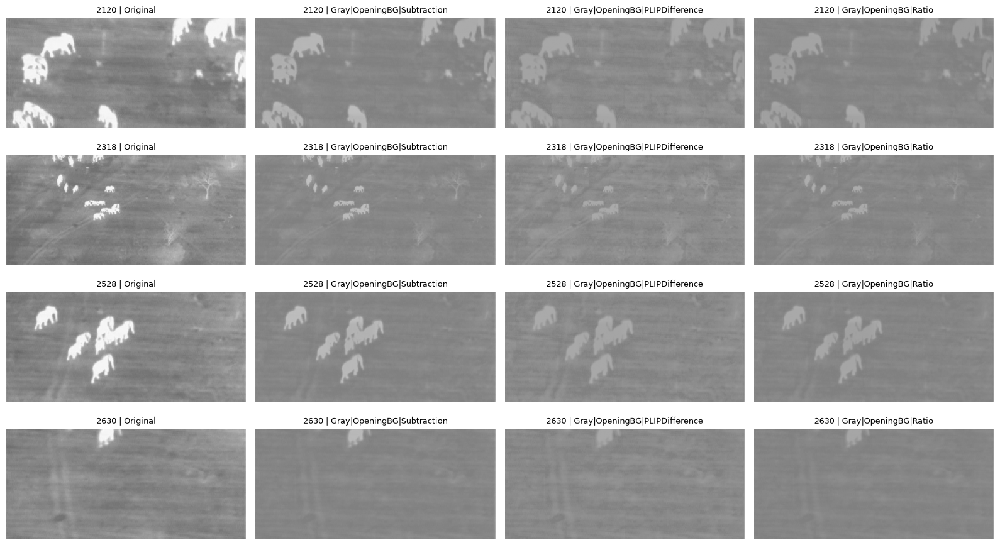

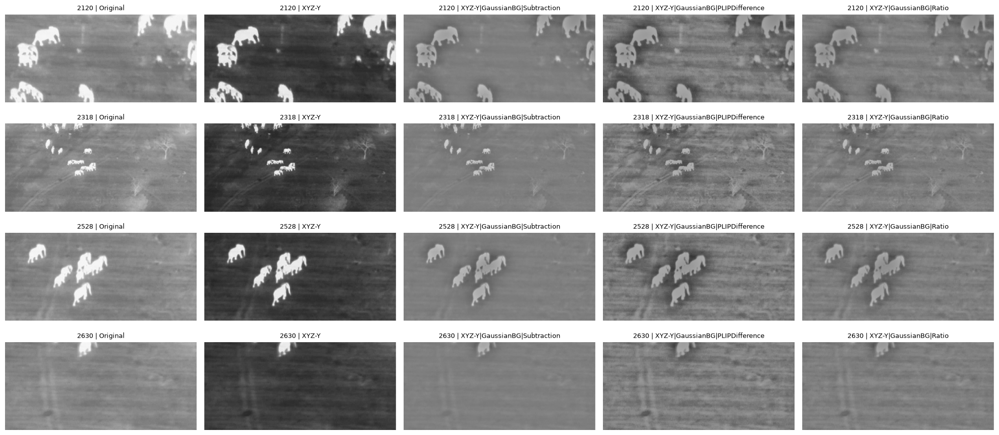

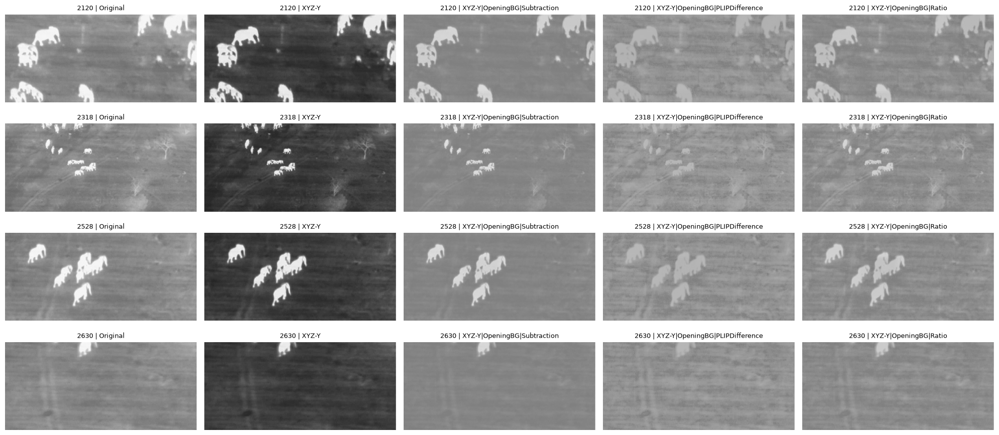

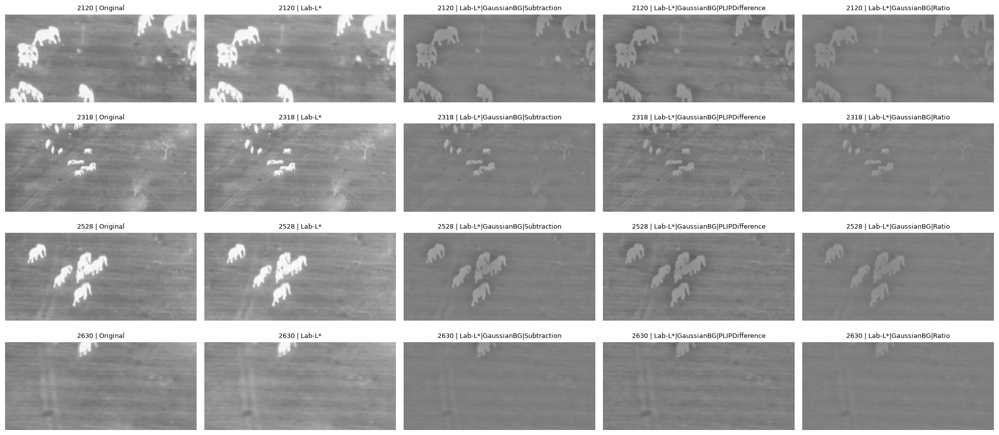

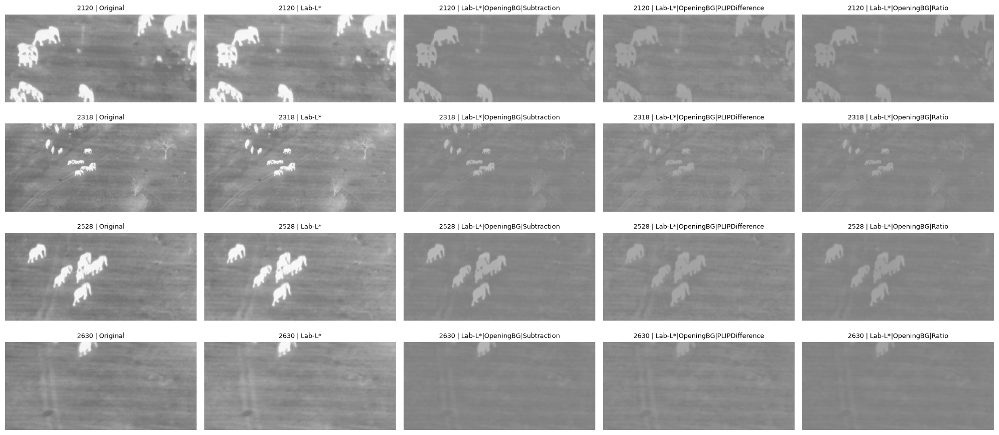

,method,frame,raw_min,raw_max,raw_mean,raw_std,encoded_std
0,Gray|GaussianBG|Subtraction,2120,-0.222847,0.423501,-2.390611e-17,0.076235,0.038117
1,Gray|GaussianBG|Subtraction,2318,-0.168657,0.437740,-1.524173e-17,0.054900,0.027450
2,Gray|GaussianBG|Subtraction,2528,-0.236467,0.376357,-1.441956e-17,0.065182,0.032591
3,Gray|GaussianBG|Subtraction,2630,-0.167964,0.297092,-7.462754e-18,0.031249,0.015625
4,Gray|GaussianBG|PLIPDifference,2120,-0.514517,0.435333,-1.582621e-02,0.102716,0.043500
...,...,...,...,...,...,...,...
67,Lab-L*|OpeningBG|PLIPDifference,2630,0.000000,0.440726,8.375377e-02,0.048651,0.018877
68,Lab-L*|OpeningBG|Ratio,2120,0.000000,0.682901,1.336619e-01,0.125390,0.030727
69,Lab-L*|OpeningBG|Ratio,2318,0.000000,0.748751,1.212125e-01,0.090184,0.022018
70,Lab-L*|OpeningBG|Ratio,2528,0.000000,0.663365,1.190932e-01,0.113537,0.027705


In [63]:
# Cell 63 — Apply all background suppression pipelines
# Output: 18 pipelines with original images beside processed outputs.
# Keep both dark and bright changes. Do not make a threshold mask.
# Use one fixed scale. Do not stretch each photo to make it look better.
# Dark pixels can give big PLIP values. Use d/(1+abs(d)) to fit them into a fixed range.
# Use log-ratio for Ratio. No change becomes 0.5. This is not PLIP division.
# No per-photo stretching. The same formula is used for every photo.
for rep,base in BASE_REPS.items():
    for est in ['GaussianBG','OpeningBG']:
        names=[]
        for op in ['Subtraction','PLIPDifference','Ratio']:
            name=f'{rep}|{est}|{op}'; BANK[name]={}; RAW_RESIDUALS[name]={}
            for k,a in BANK[base].items():
                b=BACKGROUND[(rep,est)][k]
                raw=(a-b if op=='Subtraction' else M*(a-b)/(M-1+a) if op=='PLIPDifference'
                     else np.log((a+CFG['ratio_epsilon'])/(b+CFG['ratio_epsilon'])))
                s=(raw+1)/2 if op=='Subtraction' else (raw/(1+np.abs(raw))+1)/2 if op=='PLIPDifference' else (1+np.tanh(raw/CFG['ratio_log_scale']))/2
                assert np.isfinite(s).all() and s.min()>=-EPS and s.max()<=1+EPS
                BANK[name][k]=np.clip(s,0,1); RAW_RESIDUALS[name][k]=raw
            names.append(name)
        SUPPRESSION[(rep,est)]=names
        comparisons([base]+names,f'suppression_{rep}_{est}_images')
GROUPS['Suppression']=[n for names in SUPPRESSION.values() for n in names]
raw_rows=[]
for name,frames in RAW_RESIDUALS.items():
    for k,raw in frames.items():
        raw_rows.append(dict(method=name,frame=k,raw_min=raw.min(),raw_max=raw.max(),
                             raw_mean=raw.mean(),raw_std=raw.std(),encoded_std=BANK[name][k].std()))
table(pd.DataFrame(raw_rows),'residual_range_audit')


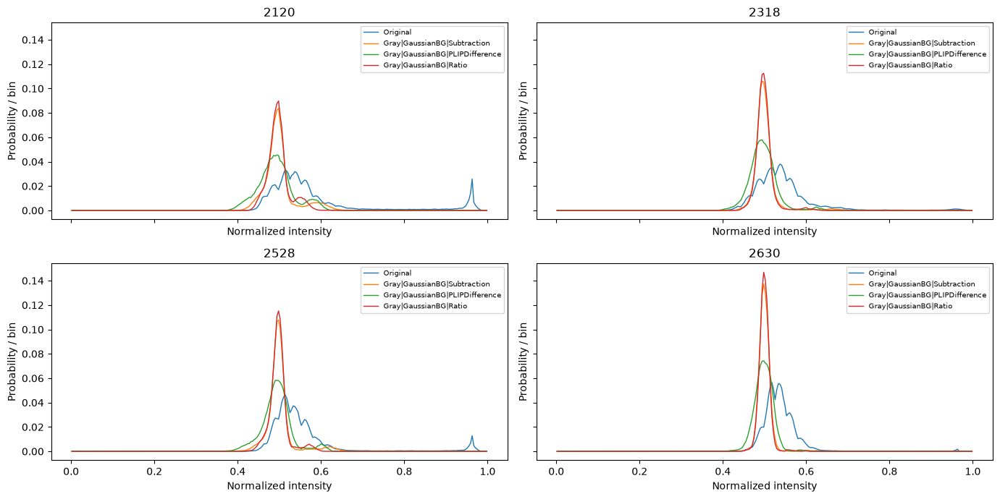

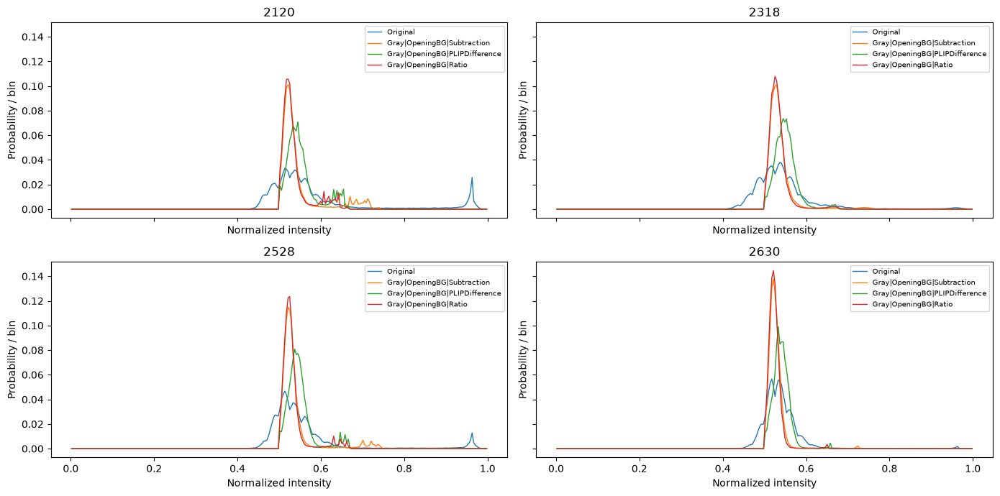

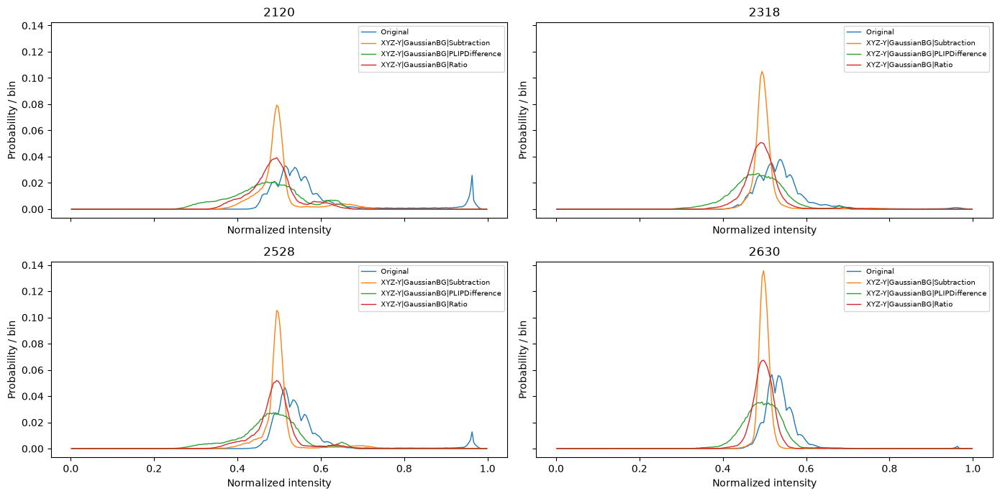

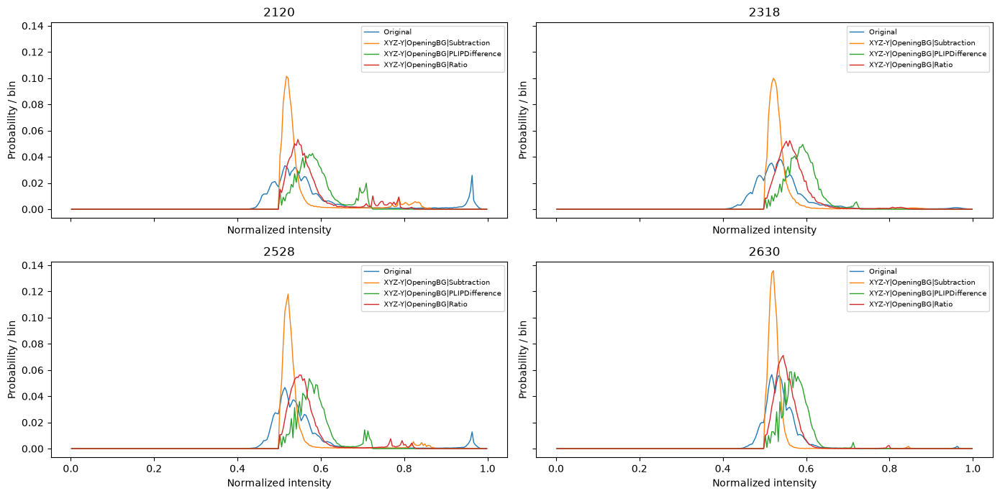

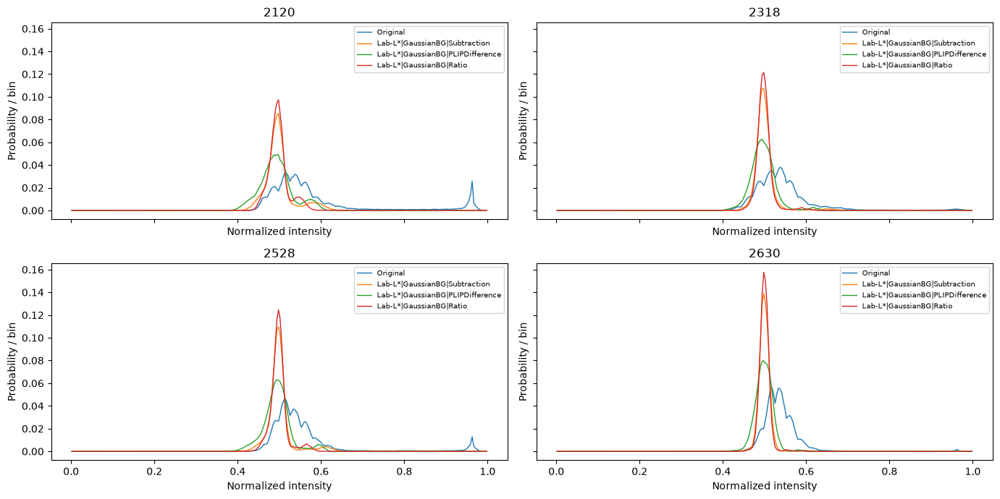

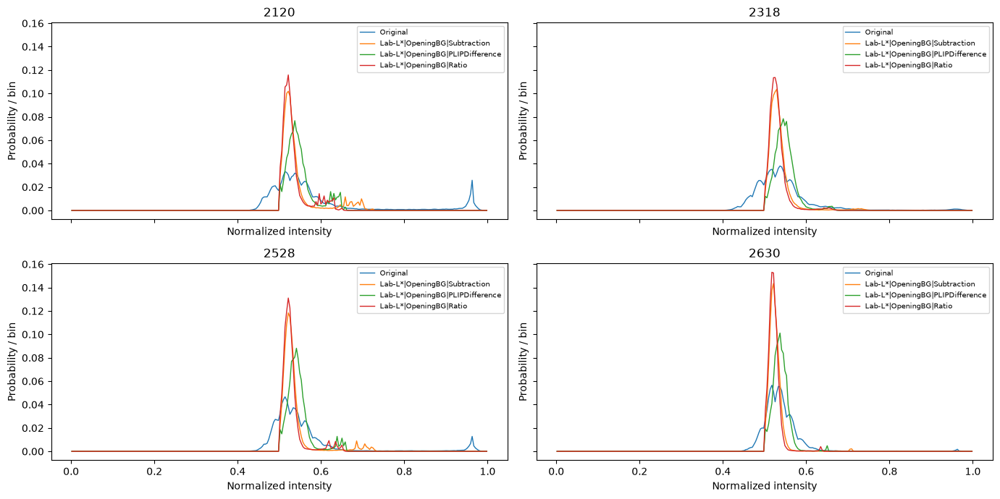

Suppression histogram x-axis is normalized residual encoding; neutral residual is 0.5.
Original brightness and residual encoding have different meanings despite their common [0,1] range.


In [64]:
# Cell 64 — Suppression histogram overlays
# Output: Original and suppression histograms, grouped by representation/estimator.
for (rep,est),names in SUPPRESSION.items(): overlays(names,f'suppression_{rep}_{est}_histograms')
print('Suppression histogram x-axis is normalized residual encoding; neutral residual is 0.5.')
print('Original brightness and residual encoding have different meanings despite their common [0,1] range.')


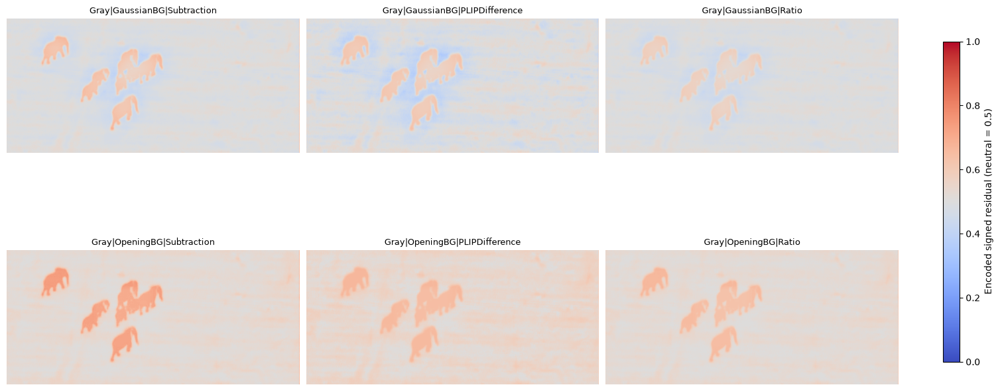

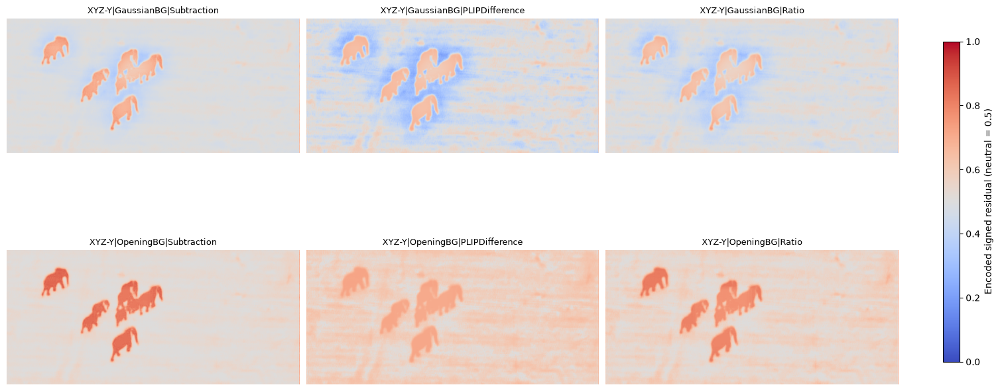

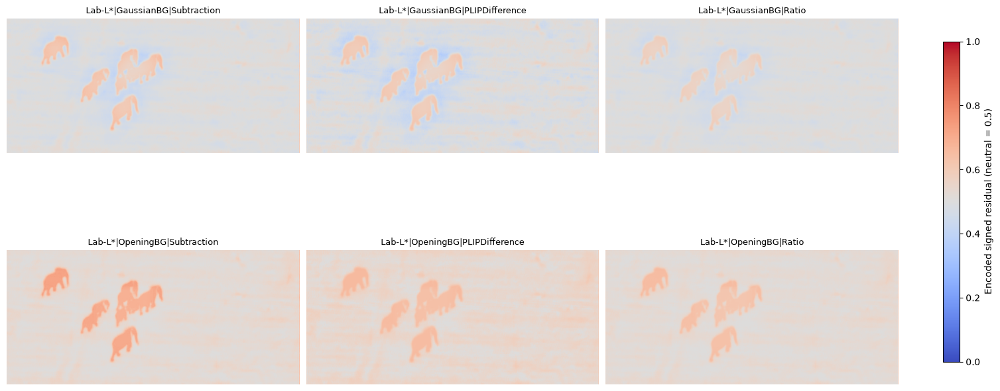

In [65]:
# Cell 65 — Suppression residual heatmaps
# Output: Spatial residual maps with identical fixed scales; not detection masks.
for rep in BASE_REPS:
    fig,axes=plt.subplots(2,3,figsize=(15,7),layout="constrained")
    for r,est in enumerate(['GaussianBG','OpeningBG']):
        for c,name in enumerate(SUPPRESSION[(rep,est)]):
            ax=axes[r,c]; im=ax.imshow(BANK[name]['2528'],cmap='coolwarm',vmin=0,vmax=1)
            ax.set_title(name,fontsize=9); ax.axis('off')
    fig.colorbar(im,ax=axes.ravel().tolist(),label='Encoded signed residual (neutral = 0.5)',shrink=0.7)
    # Leave room for the color bar. No squished labels, please.
    fig.savefig(OUT/f'residual_heatmaps_{rep}.png',dpi=150,bbox_inches='tight'); plt.show(); plt.close()


,method,roi_status,between,within_animal,within_background,margin,histogram_change,mean_edge_strength,endpoint_fraction,background_edge_strength
0,Gray|GaussianBG|Subtraction,confirmed,0.651492,0.251650,0.184075,0.433630,0.382019,0.006844,0.0,0.005449
1,Gray|GaussianBG|PLIPDifference,confirmed,0.599913,0.242776,0.190984,0.383033,0.295238,0.010359,0.0,0.009413
2,Gray|GaussianBG|Ratio,confirmed,0.594416,0.238005,0.182772,0.384027,0.397902,0.005836,0.0,0.005096
3,Gray|OpeningBG|Subtraction,confirmed,0.491002,0.259806,0.226051,0.248073,0.293089,0.006853,0.0,0.005461
4,Gray|OpeningBG|PLIPDifference,confirmed,0.490120,0.286518,0.253315,0.220204,0.220742,0.008086,0.0,0.007619
5,Gray|OpeningBG|Ratio,confirmed,0.481535,0.286694,0.234100,0.221138,0.307370,0.005804,0.0,0.005097
6,XYZ-Y|GaussianBG|Subtraction,confirmed,0.783780,0.286536,0.197110,0.541956,0.399956,0.008134,0.0,0.005521
7,XYZ-Y|GaussianBG|PLIPDifference,confirmed,0.677932,0.259445,0.216739,0.439840,0.280053,0.020067,0.0,0.018627
8,XYZ-Y|GaussianBG|Ratio,confirmed,0.669327,0.256677,0.199274,0.441352,0.297057,0.012559,0.0,0.010930
9,XYZ-Y|OpeningBG|Subtraction,confirmed,0.510493,0.242090,0.235079,0.271908,0.290699,0.008125,0.0,0.005524


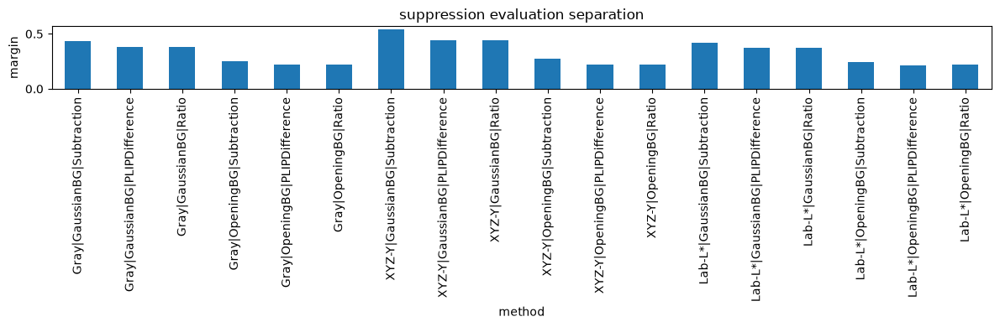

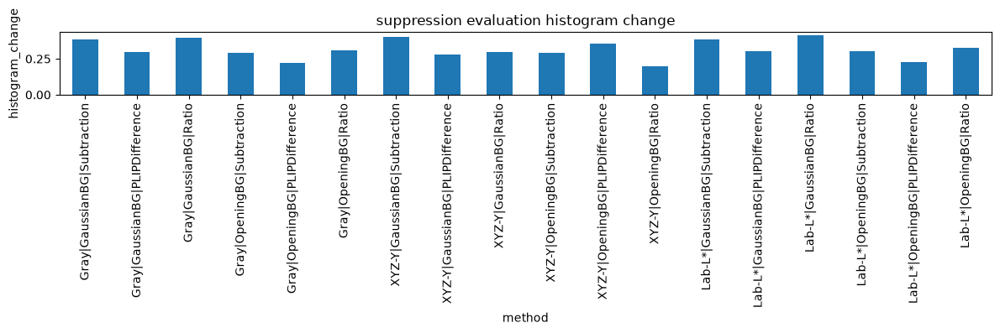

,method,animal_abs_residual,background_abs_residual,animal_background_residual_ratio,background_residual_std
0,Gray|GaussianBG|Subtraction,0.059274,0.010454,5.669768,0.012636
1,Gray|GaussianBG|PLIPDifference,0.064304,0.018027,3.567153,0.015375
2,Gray|GaussianBG|Ratio,0.039639,0.009704,4.084822,0.009998
3,Gray|OpeningBG|Subtraction,0.100998,0.026392,3.826821,0.017671
4,Gray|OpeningBG|PLIPDifference,0.090055,0.043038,2.092429,0.019950
5,Gray|OpeningBG|Ratio,0.072273,0.025749,2.806848,0.014935
6,XYZ-Y|GaussianBG|Subtraction,0.094430,0.010908,8.656870,0.016478
7,XYZ-Y|GaussianBG|PLIPDifference,0.125831,0.036867,3.413144,0.028535
8,XYZ-Y|GaussianBG|Ratio,0.088376,0.021268,4.155359,0.020999
9,XYZ-Y|OpeningBG|Subtraction,0.146403,0.025204,5.808778,0.021312


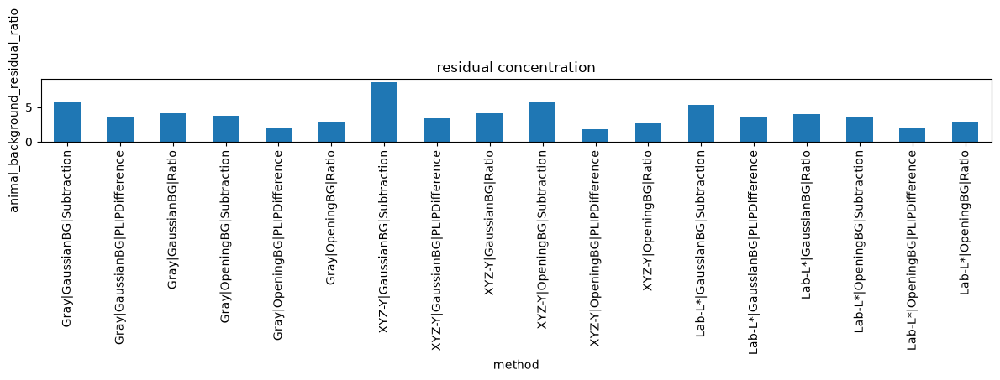

Small residual alone is not success: a constant output also has small residual. Inspect animal preservation and patch classification.
Compare scale-free concentration plus rank-controlled classification; raw residual magnitudes differ across operators.


In [66]:
# Cell 66 — Background residual and separation evaluation
# Output: Confirmed-ROI residual concentration and class consistency, with scale caveats.
SUP_METRICS=evaluate(GROUPS['Suppression'],'suppression_evaluation')
residual_rows=[]
if ROI_CONFIRMED:
    for name in GROUPS['Suppression']:
        vals={label:[] for label in ['animal','background']}
        for k in IDS:
            if SPLITS[k]=='test': continue
            for label in vals:
                vals[label].extend([np.abs(crop(BANK[name][k]-0.5,b)).ravel() for b in ROIS[k][label]])
        av=np.concatenate(vals['animal']); bv=np.concatenate(vals['background'])
        residual_rows.append(dict(method=name,animal_abs_residual=av.mean(),background_abs_residual=bv.mean(),
                                  animal_background_residual_ratio=av.mean()/(bv.mean()+EPS),
                                  background_residual_std=bv.std()))
else: status('Background residual labels unconfirmed: animal/background residual comparison skipped.')
residual_metrics=pd.DataFrame(residual_rows,columns=['method','animal_abs_residual','background_abs_residual','animal_background_residual_ratio','background_residual_std'])
table(residual_metrics,'background_residual_evaluation')
chart(residual_metrics,'method','animal_background_residual_ratio','residual_concentration')
print('Small residual alone is not success: a constant output also has small residual. Inspect animal preservation and patch classification.')
print('Compare scale-free concentration plus rank-controlled classification; raw residual magnitudes differ across operators.')


In [67]:
# Cell 67 — Background suppression decision
# Output: Explicit preliminary interpretation and editable predeclared pipeline.
decision(SUP_METRICS,CFG['selected_pipeline'],'Single-image background suppression')
print('Large animals can leak into Gaussian estimates; opening may erase bright non-animal structures.')
print('These are spatial background-suppression experiments, not temporal foreground subtraction.')


Single-image background suppression: predeclared setting = Gray|GaussianBG|Subtraction. No automatic winner claimed.


,method,margin
6,XYZ-Y|GaussianBG|Subtraction,0.541956
8,XYZ-Y|GaussianBG|Ratio,0.441352
7,XYZ-Y|GaussianBG|PLIPDifference,0.439840
0,Gray|GaussianBG|Subtraction,0.433630
12,Lab-L*|GaussianBG|Subtraction,0.416670
2,Gray|GaussianBG|Ratio,0.384027
1,Gray|GaussianBG|PLIPDifference,0.383033
14,Lab-L*|GaussianBG|Ratio,0.370878
13,Lab-L*|GaussianBG|PLIPDifference,0.370117
9,XYZ-Y|OpeningBG|Subtraction,0.271908


Margin ranking uses train/validation dataset boxes; it is exploratory.
Large animals can leak into Gaussian estimates; opening may erase bright non-animal structures.
These are spatial background-suppression experiments, not temporal foreground subtraction.


In [68]:
# Cell 68 — Local histogram and feature formulas
# Output: Separate LaTeX formulas.
display(Math('p_{W,j}=\\frac1{|W|}\\sum_{x\\in W}\\mathbf1[I(x)\\in\\mathrm{bin}_j],\\quad W\\in\\{8\\times8,16\\times16,32\\times32\\}'))
display(Math('\\mu_W=\\frac1{|W|}\\sum_{x\\in W}I(x),\\quad v_W=\\frac1{|W|}\\sum_{x\\in W}(I(x)-\\mu_W)^2,\\quad H_W=-\\sum_jp_{W,j}\\log_2p_{W,j}'))


<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [69]:
# Cell 69 — Fixed-grid and sliding-window extraction
# Output: Reusable extraction; exact pixel scales and full-window boundary policy.
def windows(a,size,stride=None):
    # Keep full windows only. Skip leftover pixels at the right and bottom.
    stride=size if stride is None else stride
    assert size>0 and stride>0
    for y in range(0,a.shape[0]-size+1,stride):
        for x in range(0,a.shape[1]-size+1,stride):
            yield (x,y,x+size,y+size),a[y:y+size,x:x+size]
def local_features(a,size,stride=None):
    return pd.DataFrame([dict(x=b[0],y=b[1],**statistics(p)) for b,p in windows(a,size,stride)])
SELECTED=CFG['selected_pipeline']
assert SELECTED in BANK
print('Fixed grid: stride = size. Sliding windows: pass stride < size. Selected:',SELECTED)


Fixed grid: stride = size. Sliding windows: pass stride < size. Selected: Gray|GaussianBG|Subtraction


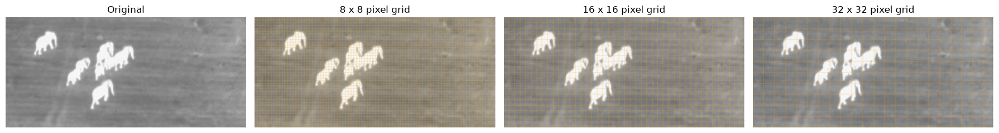

In [70]:
# Cell 70 — Window grids
# Output: Original plus 8/16/32-pixel grids on an actual uploaded frame.
fig,axes=plt.subplots(1,4,figsize=(18,4))
a=images['2528']
for ax,size in zip(axes,[None]+CFG['window_sizes']):
    ax.imshow(a,cmap='gray',vmin=0,vmax=1)
    if size:
        for x in range(0,a.shape[1]+1,size): ax.axvline(x-0.5,color='orange',lw=0.3,alpha=0.65)
        for y in range(0,a.shape[0]+1,size): ax.axhline(y-0.5,color='orange',lw=0.3,alpha=0.65)
    ax.set_title('Original' if size is None else f'{size} x {size} pixel grid'); ax.axis('off')
savefig('local_window_grids')


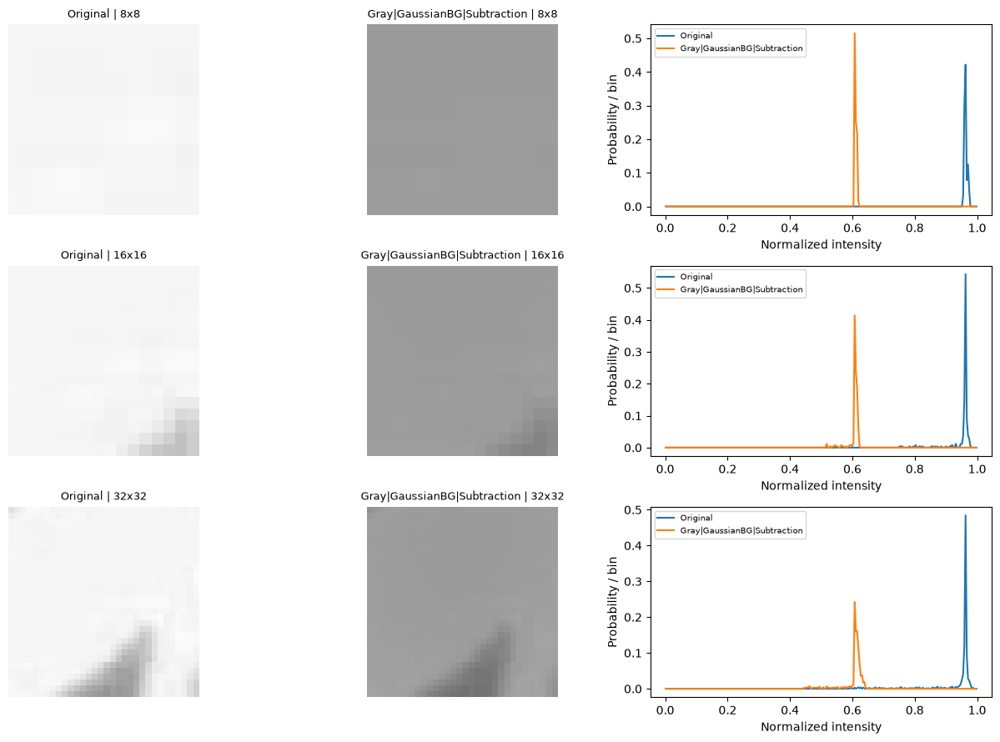

In [71]:
# Cell 71 — Local histogram examples
# Output: Matched original/processed window crops and their histogram overlays.
fig,axes=plt.subplots(3,3,figsize=(13,9))
k='2528'; cx,cy=280,222  # Move this example point if you like. It is not a checked label.
for r,size in enumerate(CFG['window_sizes']):
    b=(cx-size//2,cy-size//2,cx+size//2,cy+size//2)
    for c,name in enumerate(['Original',SELECTED]):
        axes[r,c].imshow(crop(BANK[name][k],b),cmap='gray',vmin=0,vmax=1)
        axes[r,c].set_title(f'{name} | {size}x{size}',fontsize=9); axes[r,c].axis('off')
        axes[r,2].plot(CENTERS,hist(crop(BANK[name][k],b)),label=name)
    axes[r,2].set(xlabel='Normalized intensity',ylabel='Probability / bin'); axes[r,2].legend(fontsize=7)
savefig('local_histogram_examples')


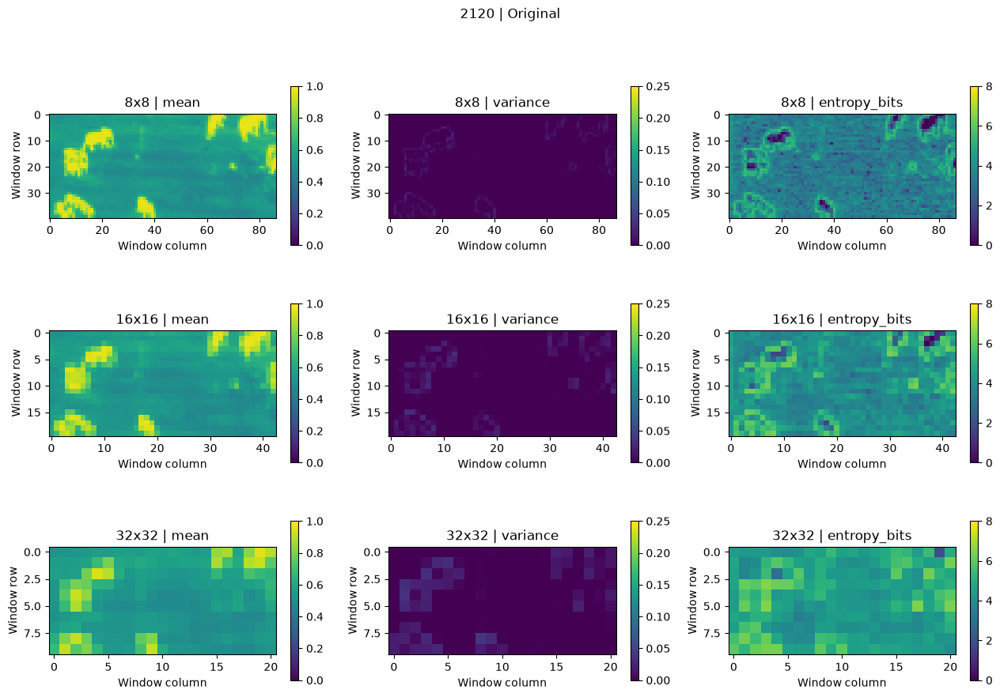

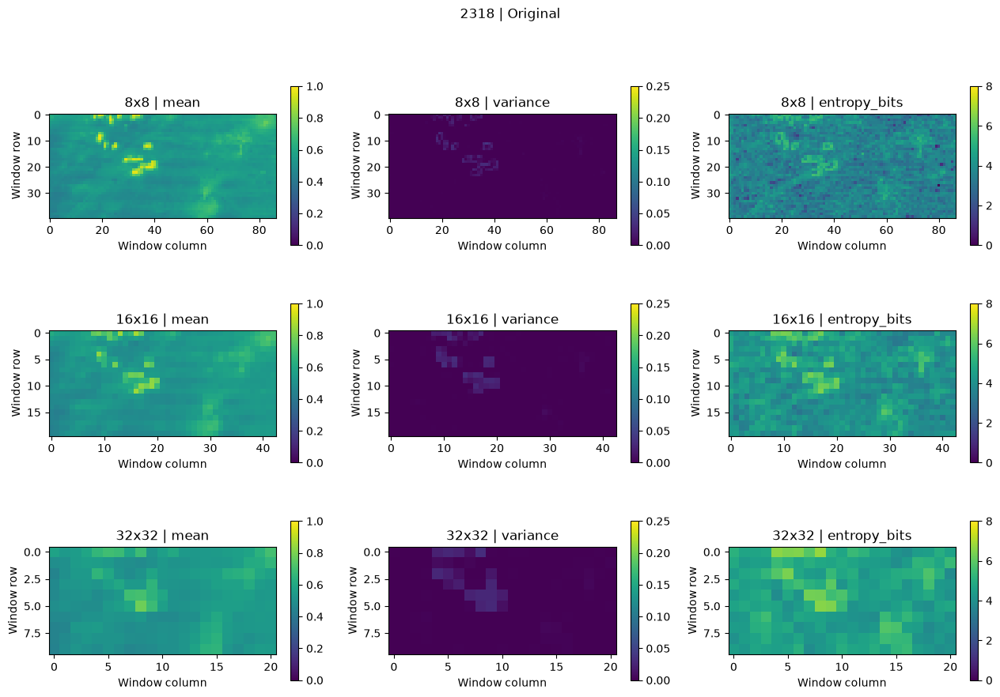

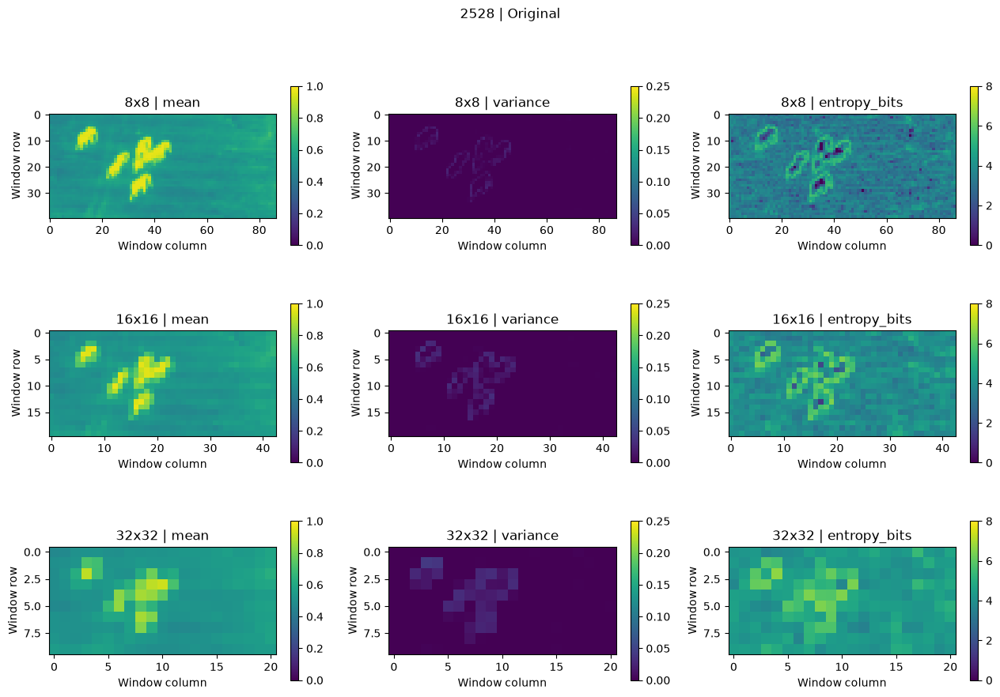

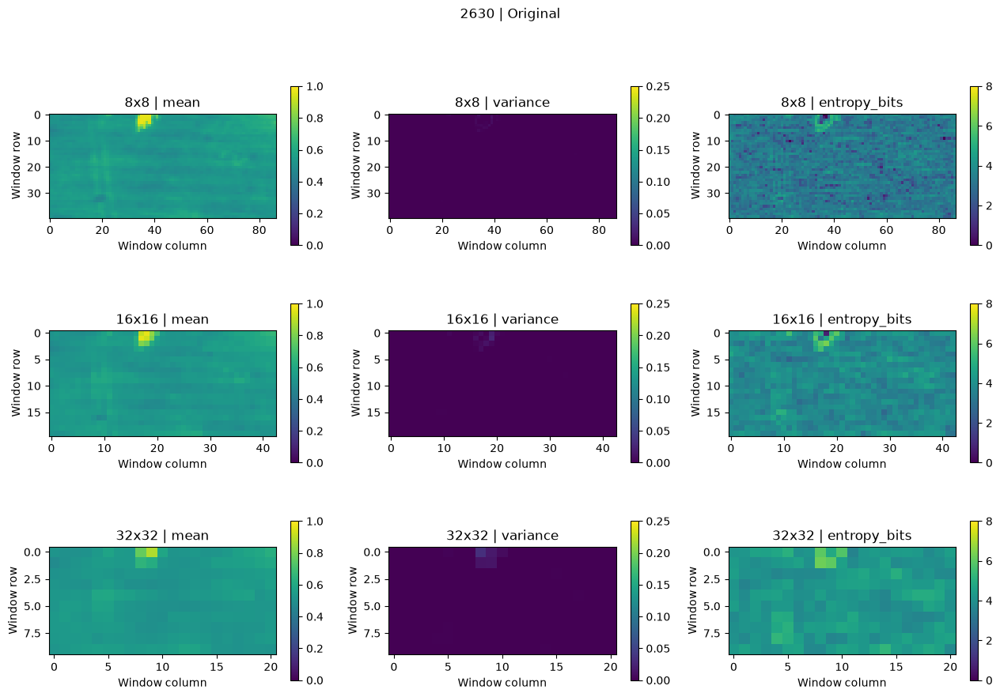

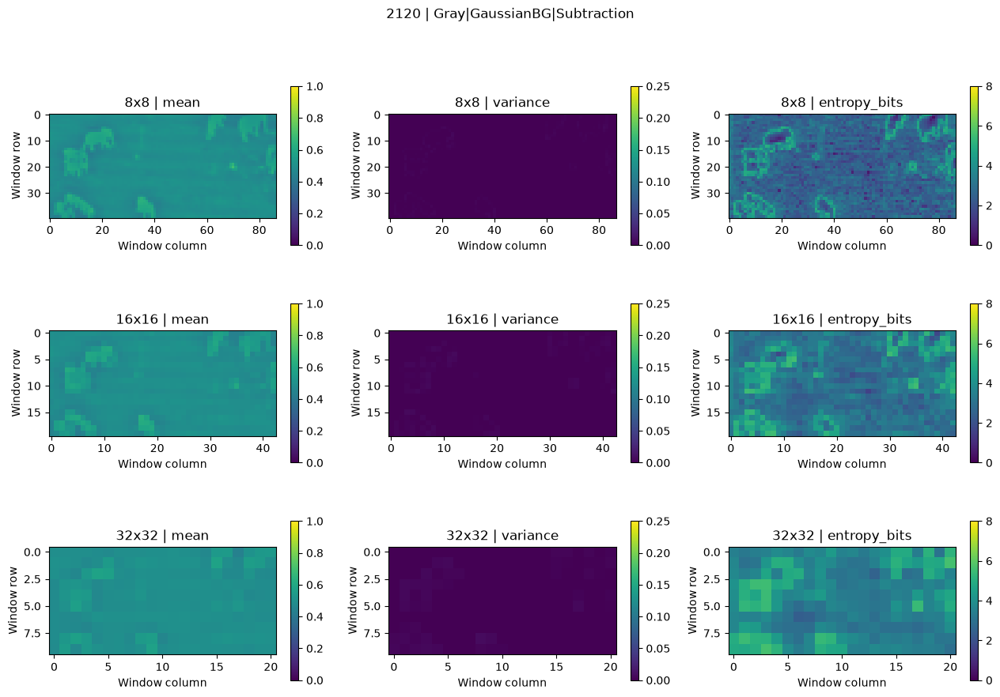

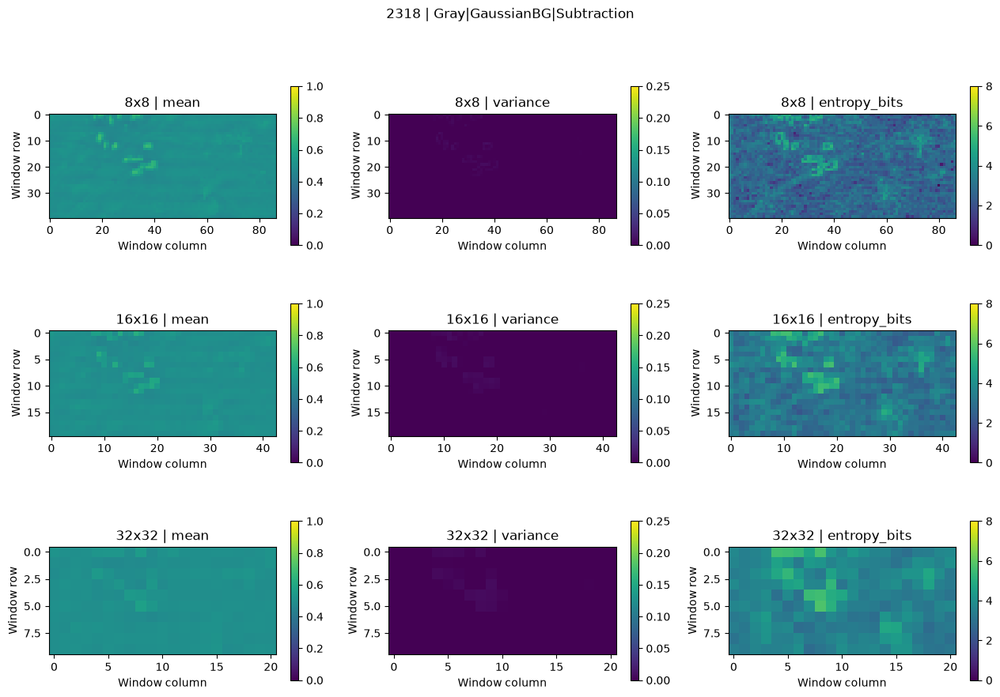

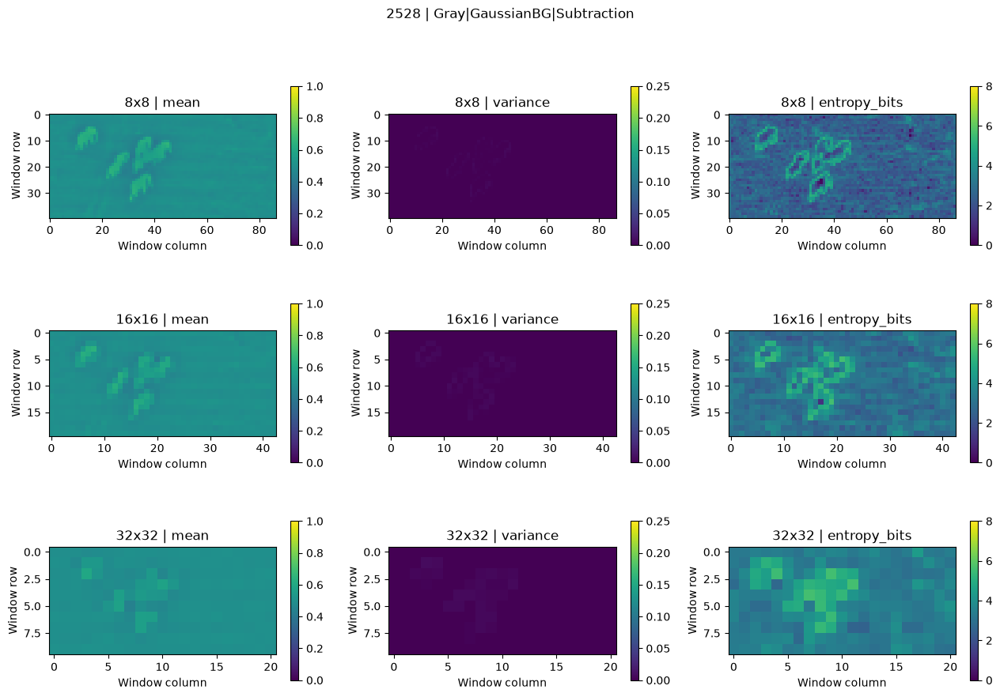

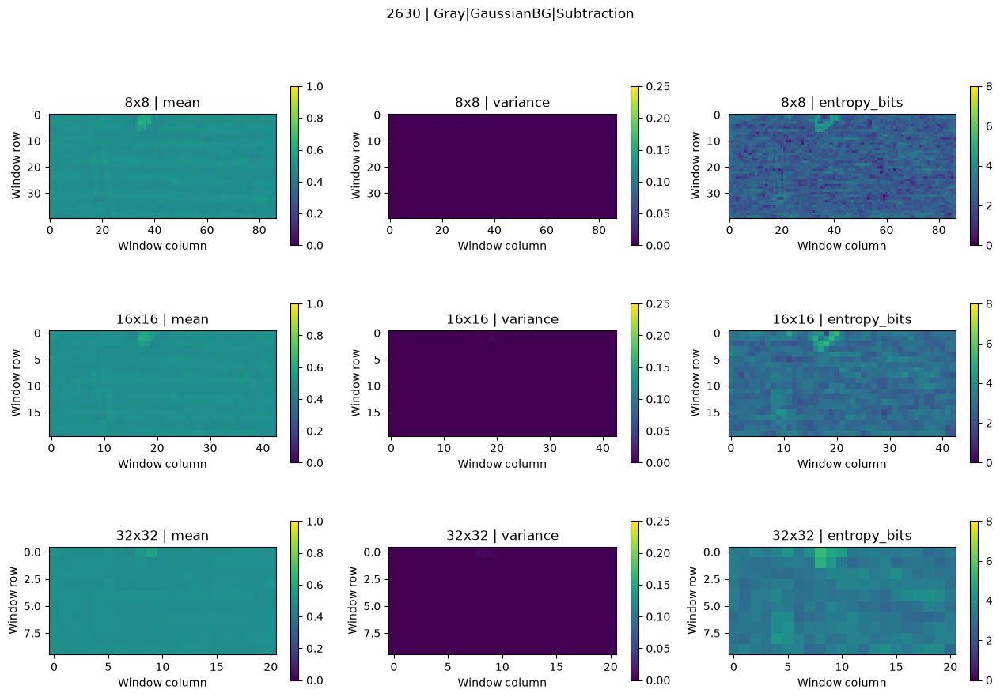

In [72]:
# Cell 72 — Mean, variance and entropy heatmaps
# Output: Feature heatmaps for all four images, both pipelines and all three window sizes.
LOCAL={}
for name in ['Original',SELECTED]:
    for k,a in BANK[name].items():
        fig,axes=plt.subplots(3,3,figsize=(13,9))
        for r,size in enumerate(CFG['window_sizes']):
            df=local_features(a,size); LOCAL[(name,k,size)]=df
            for c,feature in enumerate(['mean','variance','entropy_bits']):
                grid=df.pivot(index='y',columns='x',values=feature).to_numpy()
                limits={'mean':(0,1),'variance':(0,0.25),'entropy_bits':(0,8)}[feature]
                im=axes[r,c].imshow(grid,cmap='viridis',vmin=limits[0],vmax=limits[1],interpolation='nearest')
                axes[r,c].set_title(f'{size}x{size} | {feature}'); axes[r,c].set_xlabel('Window column'); axes[r,c].set_ylabel('Window row')
                fig.colorbar(im,ax=axes[r,c],shrink=0.7)
        fig.suptitle(f'{k} | {name}',y=1.01); savefig(f'local_features_{name}_{k}')


,frame,split,label,cx,cy,roi,track_id
0,2120,train,1,673,143,0,4
1,2120,train,1,625,47,1,5
2,2120,train,1,79,165,2,6
3,2120,train,1,78,129,3,8
4,2120,train,1,151,79,4,9
...,...,...,...,...,...,...,...
126,2630,test,0,240,272,19,-1
127,2630,test,0,528,272,20,-1
128,2630,test,0,112,304,21,-1
129,2630,test,0,400,304,22,-1


,frame,split,label,patch_count
0,2120,train,0,24
1,2120,train,1,10
2,2318,train,0,24
3,2318,train,1,15
4,2528,validation,0,24
5,2528,validation,1,9
6,2630,test,0,24
7,2630,test,1,1


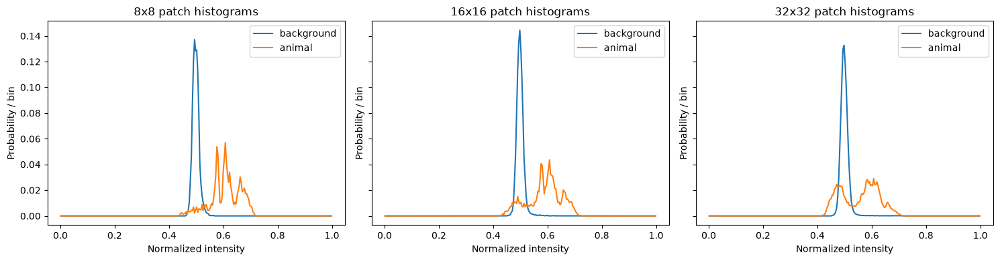

In [73]:
# Cell 73 — Use the same patch centers for every method
# Output: Dataset-based patch labels and local animal/background histograms.
# Animal samples sit at box centers. Small boxes are kept for all window sizes.
# A large window may include grass. This is animal-containing patch classification.
SAMPLES=[]
for k in IDS:
    used=set()
    for label in ['animal','background']:
        for j,b in enumerate(ROIS[k][label]):
            cx=(b[0]+b[2])//2;cy=(b[1]+b[3])//2
            if (cx,cy) not in used:
                SAMPLES.append(dict(frame=k,split=SPLITS[k],label=int(label=='animal'),cx=cx,cy=cy,roi=j,
                                    track_id=GT_IDS[k][j] if label=='animal' else -1))
                used.add((cx,cy))
sample_df=pd.DataFrame(SAMPLES);table(sample_df,'confirmed_patch_samples')
display(sample_df.groupby(['frame','split','label']).size().rename('patch_count').reset_index())
def sample_hist(name,s,size,rank=False):
    a=RANK_BANK[name][s['frame']] if rank else BANK[name][s['frame']]
    return hist(a if size=='Global' else center_patch(a,s['cx'],s['cy'],size))
RANK_BANK={name:{k:rank_image(a) for k,a in frames.items()} for name,frames in BANK.items()}
fig,axes=plt.subplots(1,3,figsize=(15,4),sharey=True)
for ax,size in zip(axes,CFG['window_sizes']):
    for label in [0,1]:
        hs=[sample_hist(SELECTED,s,size) for s in SAMPLES if s['label']==label and s['split']!='test']
        ax.plot(CENTERS,np.mean(hs,axis=0),label='animal' if label else 'background')
    ax.set_title(f'{size}x{size} patch histograms');ax.set_xlabel('Normalized intensity');ax.set_ylabel('Probability / bin');ax.legend()
savefig('local_class_histograms')


,method,size,distance,split,rank_control,n,accuracy,balanced_accuracy,precision,recall,f1,auc
0,Original,Global,chi2,validation,False,33,0.727273,0.500000,0.000000,0.0,0.000000,0.5
1,Original,8,chi2,validation,False,33,1.000000,1.000000,1.000000,1.0,1.000000,1.0
2,Original,16,chi2,validation,False,33,1.000000,1.000000,1.000000,1.0,1.000000,1.0
3,Original,32,chi2,validation,False,33,0.969697,0.979167,0.900000,1.0,0.947368,1.0
4,Gray|GaussianBG|Subtraction,Global,chi2,validation,False,33,0.272727,0.500000,0.272727,1.0,0.428571,0.5
5,Gray|GaussianBG|Subtraction,8,chi2,validation,False,33,1.000000,1.000000,1.000000,1.0,1.000000,1.0
6,Gray|GaussianBG|Subtraction,16,chi2,validation,False,33,1.000000,1.000000,1.000000,1.0,1.000000,1.0
7,Gray|GaussianBG|Subtraction,32,chi2,validation,False,33,1.000000,1.000000,1.000000,1.0,1.000000,1.0


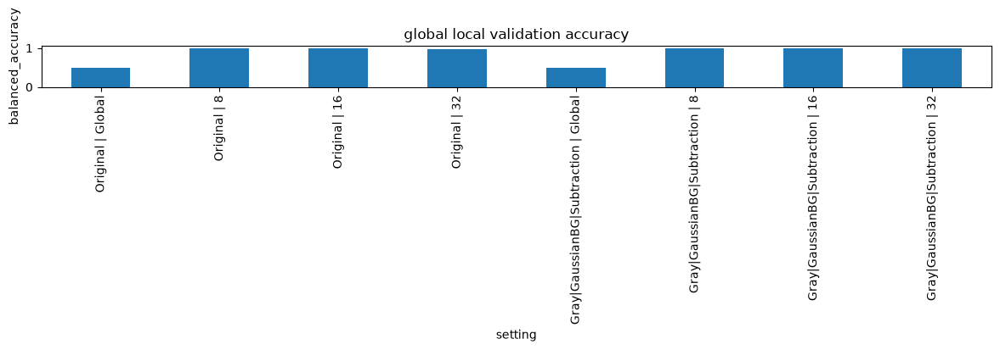

In [74]:
# Cell 74 — Global/local comparison protocol
# Output: Matched-sample validation metrics; no incompatible raw vector-distance comparisons.
# Put the matching helpers here. Show their formulas in a later cell.
# Learn from train images. Check choices on validation. Save test for the end.
# Global gives every patch in one photo the same histogram.
# So Global cannot tell where the animal is inside that photo. That is the control.
def templates(name,size,rank=False):
    result={}
    for label in [0,1]:
        hs=[sample_hist(name,s,size,rank) for s in SAMPLES if s['split']=='train' and s['label']==label]
        if not hs: return None
        result[label]=np.mean(hs,axis=0)
    return result
def classify(name,size,kind,split='validation',rank=False):
    refs=templates(name,size,rank); ss=[s for s in SAMPLES if s['split']==split]
    if refs is None or not ss: return None
    X=np.array([sample_hist(name,s,size,rank) for s in ss]); y=np.array([s['label'] for s in ss])
    d0=distance(X,refs[0],kind); d1=distance(X,refs[1],kind)
    pred=(d1<d0).astype(int); score=d0-d1  # Pick the closer template. A tie goes to background.
    if len(np.unique(y))<2: return None
    return dict(method=name,size=str(size),distance=kind,split=split,rank_control=rank,n=len(y),
                accuracy=accuracy_score(y,pred),balanced_accuracy=balanced_accuracy_score(y,pred),precision=precision_score(y,pred,zero_division=0),
                recall=recall_score(y,pred,zero_division=0),f1=f1_score(y,pred,zero_division=0),auc=roc_auc_score(y,score))
local_results=[]
for name in ['Original',SELECTED]:
    for size in ['Global']+CFG['window_sizes']:
        row=classify(name,size,'chi2')
        if row: local_results.append(row)
local_comparison=pd.DataFrame(local_results)
table(local_comparison,'global_local_validation')
if not local_comparison.empty:
    plot=local_comparison.copy(); plot['setting']=plot['method']+' | '+plot['size']
    chart(plot,'setting','balanced_accuracy','global_local_validation_accuracy')
else: status('Global/local validation unavailable: confirm both classes and train/validation ROI samples.')


In [75]:
# Cell 75 — Window-size decision
# Output: Exploratory validation ranking or pending status; no test-driven selection.
print('Predeclared window size:',CFG['selected_window'],'pixels. No optimum is asserted.')
if not local_comparison.empty: display(local_comparison.sort_values('balanced_accuracy',ascending=False))
print('8 pixels: sensitive to small structures; 32 pixels: more background mixing. Validate at shared centers.')
print('Frame 2630 is reserved for final reporting. Do not select a window or pipeline from its scores.')


Predeclared window size: 16 pixels. No optimum is asserted.


,method,size,distance,split,rank_control,n,accuracy,balanced_accuracy,precision,recall,f1,auc
1,Original,8,chi2,validation,False,33,1.000000,1.000000,1.000000,1.0,1.000000,1.0
2,Original,16,chi2,validation,False,33,1.000000,1.000000,1.000000,1.0,1.000000,1.0
5,Gray|GaussianBG|Subtraction,8,chi2,validation,False,33,1.000000,1.000000,1.000000,1.0,1.000000,1.0
6,Gray|GaussianBG|Subtraction,16,chi2,validation,False,33,1.000000,1.000000,1.000000,1.0,1.000000,1.0
7,Gray|GaussianBG|Subtraction,32,chi2,validation,False,33,1.000000,1.000000,1.000000,1.0,1.000000,1.0
3,Original,32,chi2,validation,False,33,0.969697,0.979167,0.900000,1.0,0.947368,1.0
0,Original,Global,chi2,validation,False,33,0.727273,0.500000,0.000000,0.0,0.000000,0.5
4,Gray|GaussianBG|Subtraction,Global,chi2,validation,False,33,0.272727,0.500000,0.272727,1.0,0.428571,0.5


8 pixels: sensitive to small structures; 32 pixels: more background mixing. Validate at shared centers.
Frame 2630 is reserved for final reporting. Do not select a window or pipeline from its scores.


In [76]:
# Cell 76 — Histogram matching formulas
# Output: Separate LaTeX formulas.
display(Math('D_{L1}(p,q)=\\sum_j|p_j-q_j|,\\quad D_{L2}(p,q)=\\sqrt{\\sum_j(p_j-q_j)^2}'))
display(Math('D_{\\chi^2}(p,q)=\\frac12\\sum_j\\frac{(p_j-q_j)^2}{p_j+q_j+\\epsilon},\\quad s=D(p,t_B)-D(p,t_A),\\quad \\widehat y=\\arg\\min_{c\\in\\{B,A\\}}D(p,t_c)'))


<IPython.core.display.Math object>

<IPython.core.display.Math object>

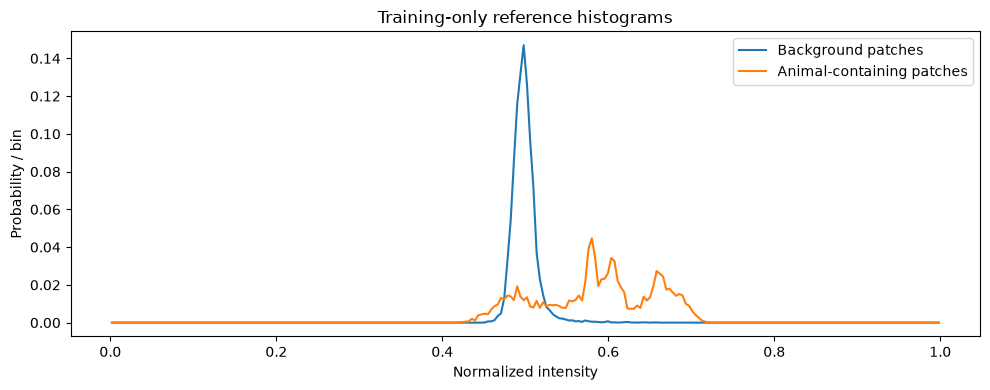

In [77]:
# Cell 77 — Training-only templates
# Output: Animal/background training templates only; no validation/test label fitting.
REFS=templates(SELECTED,CFG['selected_window'])
if REFS is not None:
    fig,ax=plt.subplots(figsize=(10,4))
    for label,p in REFS.items(): ax.plot(CENTERS,p,label='Animal-containing patches' if label else 'Background patches')
    ax.set(xlabel='Normalized intensity',ylabel='Probability / bin',title='Training-only reference histograms'); ax.legend(); savefig('training_templates')
else: status('Reference templates not built: dataset-labeled training patches are required.')


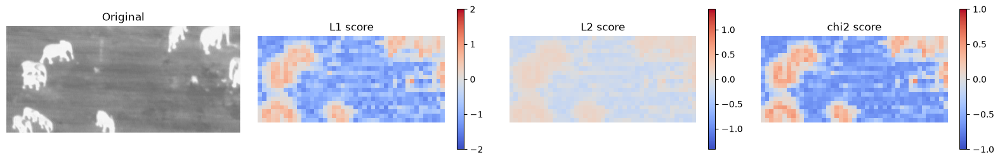

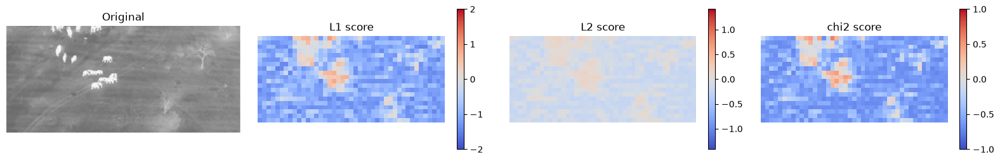

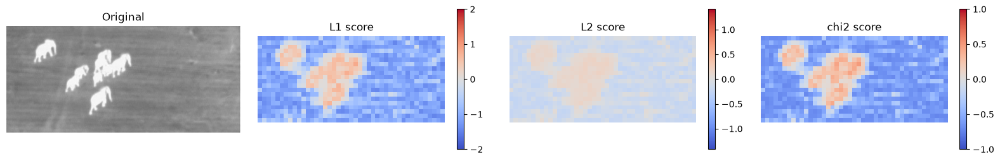

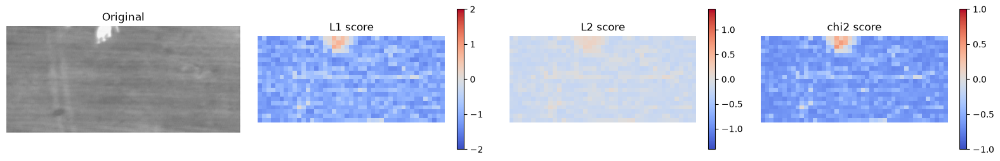

In [78]:
# Cell 78 — Distance score heatmaps
# Output: L1/L2/chi-square template score maps; positive means closer to animal template.
SCORE_MAPS={}
if REFS is not None:
    size=CFG['selected_window']
    for k,a in BANK[SELECTED].items():
        fig,axes=plt.subplots(1,4,figsize=(16,4))
        axes[0].imshow(images[k],cmap='gray',vmin=0,vmax=1); axes[0].set_title('Original'); axes[0].axis('off')
        for ax,kind in zip(axes[1:],['L1','L2','chi2']):
            rows=[(b,distance(hist(p),REFS[0],kind)-distance(hist(p),REFS[1],kind)) for b,p in windows(a,size)]
            ny=a.shape[0]//size; nx=a.shape[1]//size
            grid=np.array([s for b,s in rows]).reshape(ny,nx); SCORE_MAPS[(k,kind)]=grid
            limit={'L1':2,'L2':np.sqrt(2),'chi2':1}[kind]
            im=ax.imshow(grid,cmap='coolwarm',vmin=-limit,vmax=limit); ax.set_title(kind+' score'); ax.axis('off'); fig.colorbar(im,ax=ax,shrink=0.6)
        savefig('matching_scores_'+k)
else: status('Score maps skipped: no confirmed reference templates.')


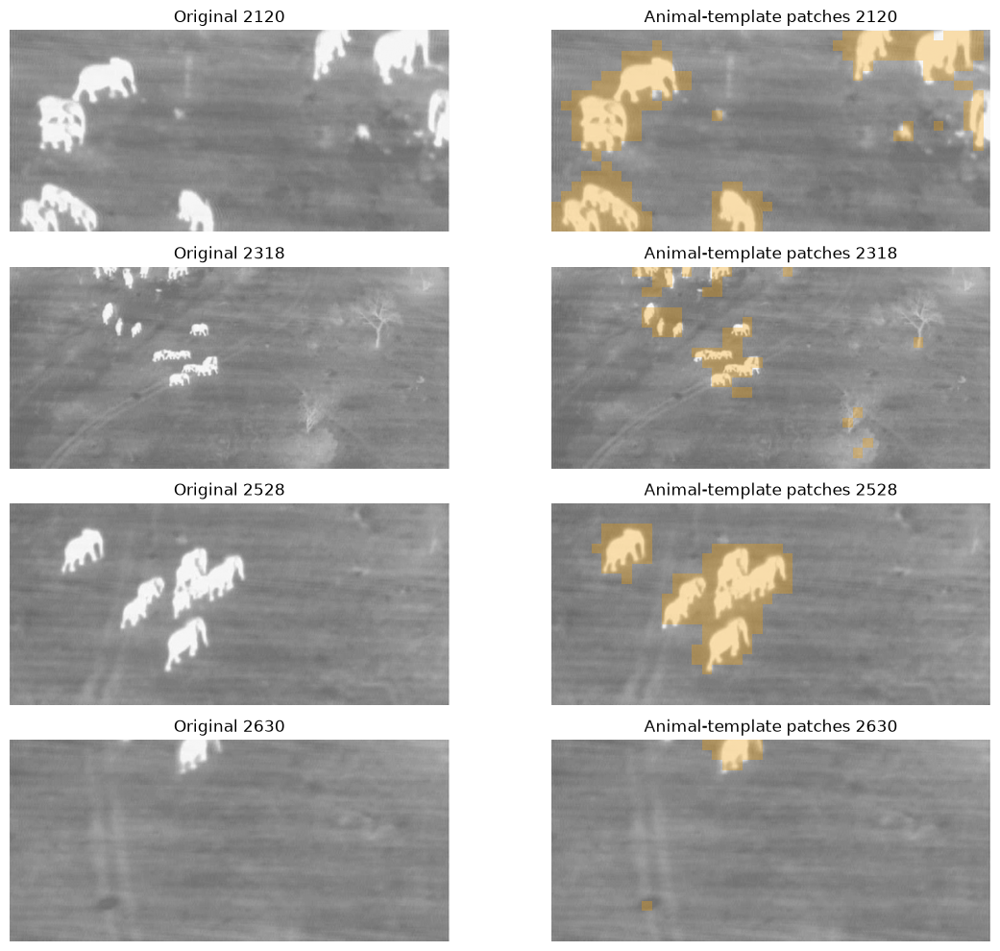

In [79]:
# Cell 79 — Nearest-template patch predictions
# Output: Original and patch predictions side by side, or explicit pending-label status.
# No brightness threshold baseline. Pick the closer of two training templates.
# These boxes are guesses for patches. They are not checked animal outlines.
if SCORE_MAPS:
    size=CFG['selected_window']; kind=CFG['selected_distance']
    fig,axes=plt.subplots(4,2,figsize=(12,10))
    for r,k in enumerate(IDS):
        for ax in axes[r]: ax.imshow(images[k],cmap='gray',vmin=0,vmax=1); ax.axis('off')
        axes[r,0].set_title('Original '+k); axes[r,1].set_title('Animal-template patches '+k)
        for y,x in np.argwhere(SCORE_MAPS[(k,kind)]>0):
            axes[r,1].add_patch(Rectangle((x*size,y*size),size,size,facecolor='orange',alpha=0.3,edgecolor='none'))
    savefig('nearest_template_predictions')
else: status('Predictions withheld until reference labels are dataset-labeled.')


,method,size,distance,split,rank_control,n,accuracy,balanced_accuracy,precision,recall,f1,auc
0,Original,16,L1,validation,False,33,1.000000,1.000000,1.00,1.000000,1.000000,1.0
1,Original,16,L1,validation,True,33,0.909091,0.937500,0.75,1.000000,0.857143,1.0
2,Original,16,L2,validation,False,33,1.000000,1.000000,1.00,1.000000,1.000000,1.0
3,Original,16,L2,validation,True,33,1.000000,1.000000,1.00,1.000000,1.000000,1.0
4,Original,16,chi2,validation,False,33,1.000000,1.000000,1.00,1.000000,1.000000,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...
193,Lab-L*|OpeningBG|Ratio,16,L1,validation,True,33,0.969697,0.979167,0.90,1.000000,0.947368,1.0
194,Lab-L*|OpeningBG|Ratio,16,L2,validation,False,33,1.000000,1.000000,1.00,1.000000,1.000000,1.0
195,Lab-L*|OpeningBG|Ratio,16,L2,validation,True,33,0.939394,0.888889,1.00,0.777778,0.875000,1.0
196,Lab-L*|OpeningBG|Ratio,16,chi2,validation,False,33,1.000000,1.000000,1.00,1.000000,1.000000,1.0


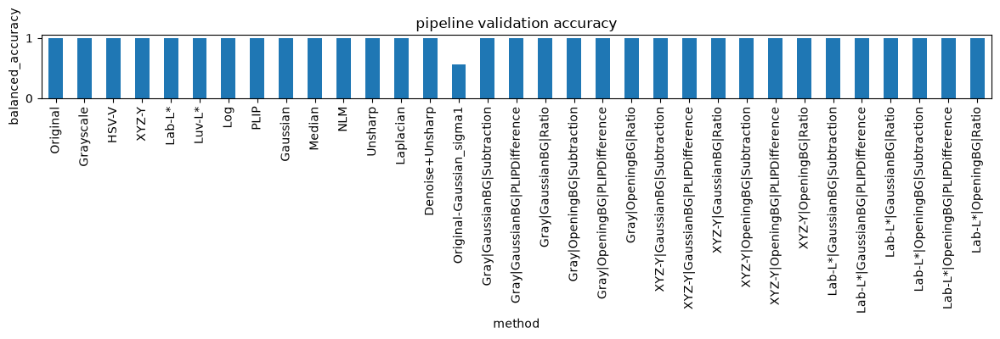

In [80]:
# Cell 80 — Validation audit across pipelines and distances
# Output: Validation-only performance, fixed-bin versus rank control, for all candidates.
# Use the same validation patches for normal bins and brightness-rank bins.
# An increasing brightness curve should keep the original ranks.
# Background removal can change ranks. Check the scores; a pretty picture is not proof.
VALIDATION=[]
CANDIDATES=list(dict.fromkeys(['Original']+REPRESENTATIONS+DENOISE+SHARP+['Original-Gaussian_sigma1']+GROUPS['Suppression']))
for name in CANDIDATES:
    for kind in ['L1','L2','chi2']:
        for rank in [False,True]:
            row=classify(name,CFG['selected_window'],kind,rank=rank)
            if row: VALIDATION.append(row)
validation_df=pd.DataFrame(VALIDATION)
table(validation_df,'all_pipeline_validation')
if not validation_df.empty:
    subset=validation_df[(validation_df.distance=='chi2')&(~validation_df.rank_control)]
    chart(subset,'method','balanced_accuracy','pipeline_validation_accuracy')
else: status('Validation metrics skipped; no fabricated accuracy, precision, recall, F1 or AUC.')


,method,size,distance,split,rank_control,n,accuracy,balanced_accuracy,precision,recall,f1,auc
0,Original,16,chi2,test,False,25,1.00,1.000000,1.00,1.0,1.000000,1.0
1,Original,16,chi2,test,True,25,0.88,0.937500,0.25,1.0,0.400000,1.0
2,Gray|GaussianBG|Subtraction,16,chi2,test,False,25,1.00,1.000000,1.00,1.0,1.000000,1.0
3,Gray|GaussianBG|Subtraction,16,chi2,test,True,25,0.96,0.979167,0.50,1.0,0.666667,1.0


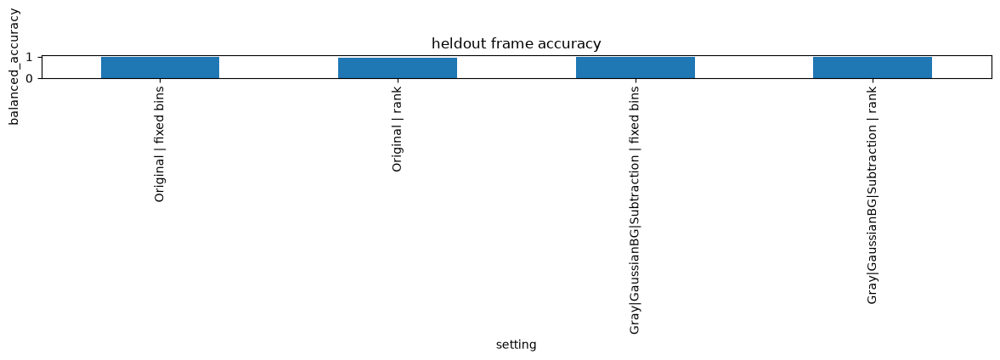

Unit: confirmed animal-containing/background patches, not animal instances or pixels.
Only one held-out frame from the same sequence; no independent-dataset generalization claim.


In [81]:
# Cell 81 — Held-out-frame baseline versus predeclared pipeline
# Output: Balanced accuracy, precision, recall, F1 and AUC only when actual confirmed labels exist.
# Test only Original and our chosen pipeline. Do not pick a winner from test scores.
FINAL=[]
for name in ['Original',SELECTED]:
    for rank in [False,True]:
        row=classify(name,CFG['selected_window'],CFG['selected_distance'],split='test',rank=rank)
        if row: FINAL.append(row)
final_df=pd.DataFrame(FINAL); table(final_df,'heldout_frame_evaluation')
if not final_df.empty:
    df=final_df.copy(); df['setting']=df['method']+np.where(df['rank_control'],' | rank',' | fixed bins')
    chart(df,'setting','balanced_accuracy','heldout_frame_accuracy')
print('Unit: confirmed animal-containing/background patches, not animal instances or pixels.')
print('Only one held-out frame from the same sequence; no independent-dataset generalization claim.')


In [82]:
# Cell 82 — Final pipeline and interpretation
# Output: Accurate settings and limitations, without claiming untested chained processing.
summary=pd.DataFrame([
 {'stage':'Luminance','setting':'Gray / HSV-V / XYZ-Y / Lab-L* / Luv-L* / Log','status':'sRGB convention; equivalence controls included'},
 {'stage':'Denoising','setting':CFG['selected_denoising'],'status':'predeclared, not proven optimal'},
 {'stage':'Sharpening','setting':'Original / Unsharp / Laplacian / Denoise+Unsharp','status':'independent comparison'},
 {'stage':'PLIP','setting':f'M={M}; power={CFG["plip_power"]}','status':'explicit tied-parameter special case'},
 {'stage':'Background','setting':SELECTED,'status':'single-image estimate; not temporal change'},
 {'stage':'Local histogram','setting':str(CFG['selected_window'])+' pixels, 256 bins','status':'shared evaluation centers'},
 {'stage':'Labels','setting':str(ROI_CONFIRMED),'status':'dataset box labels' if ROI_CONFIRMED else 'labels missing'}])
table(summary,'pipeline_summary')
print('The 100-image section below picks a winner using validation scores only.')
print('Denoising/sharpening are separate ablations; the selected final pipeline is exactly the one named above.')


,stage,setting,status
0,Luminance,Gray / HSV-V / XYZ-Y / Lab-L* / Luv-L* / Log,sRGB convention; equivalence controls included
1,Denoising,NLM,"predeclared, not proven optimal"
2,Sharpening,Original / Unsharp / Laplacian / Denoise+Unsharp,independent comparison
3,PLIP,M=1.01; power=0.7,explicit tied-parameter special case
4,Background,Gray|GaussianBG|Subtraction,single-image estimate; not temporal change
5,Local histogram,"16 pixels, 256 bins",shared evaluation centers
6,Labels,True,dataset box labels


The 100-image section below picks a winner using validation scores only.
Denoising/sharpening are separate ablations; the selected final pipeline is exactly the one named above.


In [83]:
# Cell 83 — Aggregate actual experiment outputs
# Output: Combined CSV, reproducible configuration, and honest run-status records.
all_metrics=pd.concat([df.assign(experiment=name) for name,df in METRICS.items()],ignore_index=True)
table(all_metrics,'all_experiment_metrics')
(OUT/'run_manifest.json').write_text(json.dumps(dict(config=CFG,roi_confirmed=ROI_CONFIRMED,splits=SPLITS,
    python=platform.python_version(),numpy=np.__version__,pandas=pd.__version__,selected_pipeline=SELECTED,
    limitations=['Uncalibrated grayscale JPGs','Dataset boxes are not pixel masks',
                 'One aerial sequence only','Single-image background is an estimate','No clean-image ground truth']),indent=2))
(OUT/'run_status.txt').write_text('\n'.join(AUDIT))


,method,roi_status,between,within_animal,within_background,margin,histogram_change,mean_edge_strength,endpoint_fraction,background_edge_strength,experiment
0,Original,confirmed,0.661588,0.200011,0.437106,0.343030,0.000000,0.013785,0.000028,0.010951,baseline_evaluation
1,Original,confirmed,0.661588,0.200011,0.437106,0.343030,0.000000,0.013785,0.000028,0.010951,representation_Grayscale_evaluation
2,Grayscale,confirmed,0.661588,0.200011,0.437106,0.343030,0.000000,0.013785,0.000028,0.010951,representation_Grayscale_evaluation
3,Original,confirmed,0.661588,0.200011,0.437106,0.343030,0.000000,0.013785,0.000028,0.010951,representation_HSV-V_evaluation
4,HSV-V,confirmed,0.661588,0.200011,0.437106,0.343030,0.000000,0.013785,0.000028,0.010951,representation_HSV-V_evaluation
5,Original,confirmed,0.661588,0.200011,0.437106,0.343030,0.000000,0.013785,0.000028,0.010951,representation_XYZ-Y_evaluation
6,XYZ-Y,confirmed,0.661542,0.200001,0.436853,0.343115,0.942701,0.016351,0.000028,0.011088,representation_XYZ-Y_evaluation
7,Original,confirmed,0.661588,0.200011,0.437106,0.343030,0.000000,0.013785,0.000028,0.010951,representation_Lab-L_evaluation
8,Lab-L*,confirmed,0.661283,0.196692,0.436989,0.344442,0.187777,0.013381,0.000028,0.010829,representation_Lab-L_evaluation
9,Original,confirmed,0.661588,0.200011,0.437106,0.343030,0.000000,0.013785,0.000028,0.010951,representation_Luv-L_evaluation


0

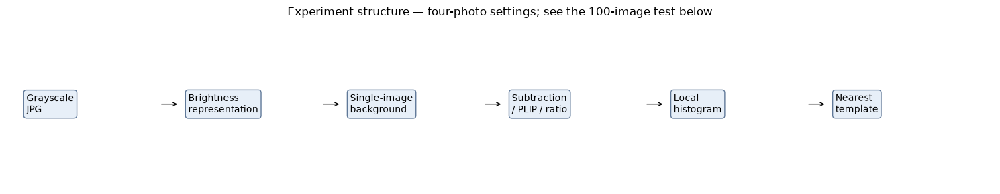

Numerical integrity checks passed. Figures and tables saved in: /Users/yingying/.codex/.chatgpt-projects/g-p-6a9853e50250819194465d3e0ed1452b/output/Wildlife_Midterm_GT/results
Label-dependent conclusions: preliminary confirmed-patch evaluation only


In [84]:
# Cell 84 — Final visualization and completion checks
# Output: Pipeline diagram, actual-output integrity checks and completion status.
fig,ax=plt.subplots(figsize=(15,3)); ax.axis('off')
steps=['Grayscale JPG','Brightness representation','Single-image background','Subtraction / PLIP / ratio','Local histogram','Nearest template']
for i,label in enumerate(steps):
    x=0.02+i*0.164
    ax.text(x,0.5,label.replace(' ','\n',1),ha='left',va='center',fontsize=10,bbox=dict(boxstyle='round',facecolor='#e7eff8',edgecolor='#5f7898'),transform=ax.transAxes)
    if i<5: ax.annotate('',xy=(x+0.155,0.5),xytext=(x+0.135,0.5),xycoords='axes fraction',arrowprops=dict(arrowstyle='->'))
ax.set_title('Experiment structure — four-photo settings; see the 100-image test below')
savefig('experiment_pipeline')
for name,frames in BANK.items():
    for k,a in frames.items():
        assert a.shape==images[k].shape and np.isfinite(a).all(),(name,k)
        assert a.min()>=-EPS and a.max()<=1+EPS,(name,k)
        assert np.isclose(hist(a).sum(),1), (name,k)
assert np.allclose(distance(hist(images['2120']),hist(images['2120'])),0)
print('Numerical integrity checks passed. Figures and tables saved in:',OUT.resolve())
print('Label-dependent conclusions:', 'preliminary confirmed-patch evaluation only' if ROI_CONFIRMED else 'PENDING manual ROI confirmation; no classification scores reported.')


In [85]:
# Cell 85 — 100-photo test: fixed sample and rules
# Output: Exact frame list, class counts, and animal-ID overlap audit.
# Pick 100 evenly spaced frames with at least one valid dataset animal box.
# This tests animal/background PATCHES in animal-present photos, not empty-scene detection.
# Do not pick nice-looking photos. The saved list fixes the sample.
BENCH=pd.read_csv('benchmark_frames.csv'); BENCH_DIR=Path('benchmark_images')
assert len(BENCH)==100 and BENCH.frame.nunique()==100
assert BENCH.groupby('split').size().to_dict()=={'test':20,'train':60,'validation':20}
assert BENCH[BENCH.split=='train'].frame.max()<BENCH[BENCH.split=='validation'].frame.min()
assert BENCH[BENCH.split=='validation'].frame.max()<BENCH[BENCH.split=='test'].frame.min()
A100={};B100_ROWS=[]
for row in BENCH.itertuples():
    p=BENCH_DIR/row.filename
    assert hashlib.sha256(p.read_bytes()).hexdigest()==row.sha256
    a=np.asarray(Image.open(p).convert('L'),dtype=np.float64)/255;A100[row.frame]=a
    pairs=gt_boxes(row.frame,a.shape);assert pairs
    bg=background_boxes(a.shape,[b for tid,b in pairs],limit=24,buffer=8)
    assert bg
    centers=set()
    for label,pairs_now in [(1,pairs),(0,[(-1,b) for b in bg])]:
        for tid,b in pairs_now:
            cx=(b[0]+b[2])//2;cy=(b[1]+b[3])//2
            if (cx,cy) in centers:continue
            centers.add((cx,cy))
            B100_ROWS.append(dict(frame=row.frame,split=row.split,label=label,cx=cx,cy=cy,track_id=tid,
                                  box_width=b[2]-b[0],box_height=b[3]-b[1]))
B100=pd.DataFrame(B100_ROWS)
table(BENCH,'benchmark_100_frames');table(B100,'benchmark_patch_labels')
table(B100.groupby(['split','label']).size().rename('patch_count').reset_index(),'benchmark_class_counts')
track_sets={split:set(B100[(B100.split==split)&(B100.label==1)].track_id) for split in ['train','validation','test']}
overlap=[dict(pair=a+' / '+b,shared_track_ids=sorted(track_sets[a]&track_sets[b])) for a,b in [('train','validation'),('train','test'),('validation','test')]]
table(pd.DataFrame(overlap),'benchmark_track_overlap')
print('Time split: first 60 train, next 20 validation, last 20 test. All are from ONE video.')
print('Some animals may appear in more than one split. This is not a new-animal or new-video test.')
print('Positive = a patch at an animal box center. Negative = a patch outside all boxes plus a gap.')
print('Box labels are not pixel masks. We assume the supplied animal boxes are complete.')


,frame,filename,split,n_boxes,sha256
0,0,0000000367_0000000000_0000000000.jpg,train,11,d67cd25d54051c1c17367b47a1ae137f9be9cc6a227a09...
1,51,0000000367_0000000000_0000000051.jpg,train,11,d3b5a19a3deac546967136aefe429cde36d17bc7547212...
2,103,0000000367_0000000000_0000000103.jpg,train,11,140a2a7b2c27ec937088b281d6ac59d2c4db174fc8ea3c...
3,154,0000000367_0000000000_0000000154.jpg,train,9,3e4e660aff74f708b6a31446f6d4925d07f2bc023a20ee...
4,206,0000000367_0000000000_0000000206.jpg,train,9,16cddf2fac88f8234b683dbf0171711981f92fc11ddc88...
...,...,...,...,...,...
95,5223,0000000367_0000000000_0000005223.jpg,test,10,1911a3ba3b249284ef576460bddf3abbbd878437d1de70...
96,5275,0000000367_0000000000_0000005275.jpg,test,10,4b69f474a70c7567a7852f27afa95c4158449e601b8a0a...
97,5326,0000000367_0000000000_0000005326.jpg,test,12,f0e31f873f414a12707a1da1069e79d7a707fc98dca001...
98,5378,0000000367_0000000000_0000005378.jpg,test,3,21e84749dd3db7c43aa784b12e7d9928c45b503d7c9207...


,frame,split,label,cx,cy,track_id,box_width,box_height
0,0,train,1,440,225,1,31,32
1,0,train,1,484,241,2,32,35
2,0,train,1,485,273,3,33,49
3,0,train,1,461,299,4,50,43
4,0,train,1,440,254,5,48,46
...,...,...,...,...,...,...,...,...
3202,5429,test,0,112,272,-1,32,32
3203,5429,test,0,400,272,-1,32,32
3204,5429,test,0,80,304,-1,32,32
3205,5429,test,0,368,304,-1,32,32


,split,label,patch_count
0,test,0,480
1,test,1,114
2,train,0,1440
3,train,1,535
4,validation,0,480
5,validation,1,158


,pair,shared_track_ids
0,train / validation,"[37, 38, 39, 40, 41, 42, 43, 44, 45, 46]"
1,train / test,[]
2,validation / test,[]


Time split: first 60 train, next 20 validation, last 20 test. All are from ONE video.
Some animals may appear in more than one split. This is not a new-animal or new-video test.
Positive = a patch at an animal box center. Negative = a patch outside all boxes plus a gap.
Box labels are not pixel masks. We assume the supplied animal boxes are complete.


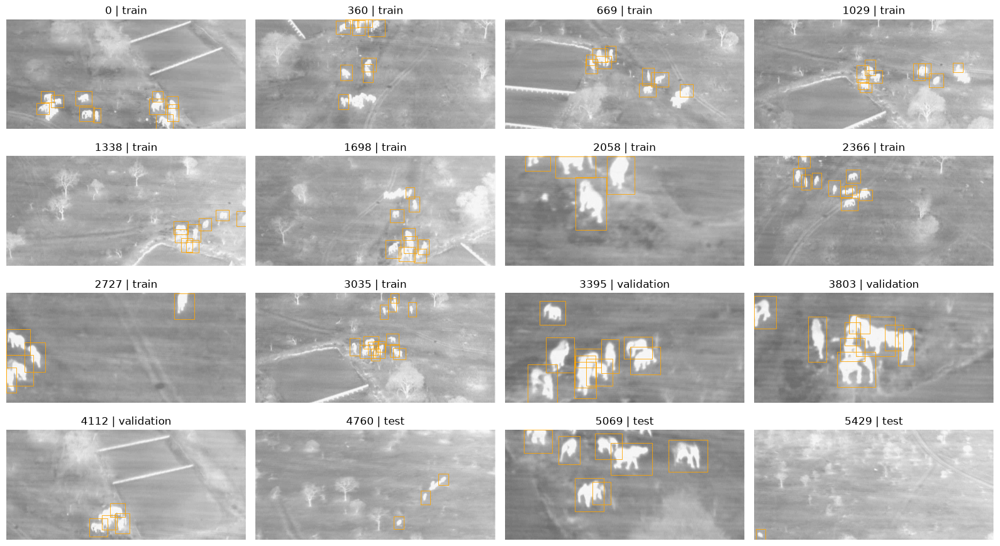

In [86]:
# Cell 86 — 100-photo test: a quick look at the sample
# Output: Sixteen examples from the fixed 100-photo sample.
fig,axes=plt.subplots(4,4,figsize=(16,9))
for ax,i in zip(axes.flat,np.linspace(0,99,16).round().astype(int)):
    row=BENCH.iloc[i];ax.imshow(A100[row.frame],cmap='gray',vmin=0,vmax=1)
    for tid,(x0,y0,x1,y1) in gt_boxes(row.frame,A100[row.frame].shape):
        ax.add_patch(Rectangle((x0,y0),x1-x0,y1-y0,fill=False,color='orange',lw=0.6))
    ax.set_title(f'{row.frame} | {row.split}');ax.axis('off')
savefig('benchmark_sample_overview')


In [87]:
# Cell 87 — Scores: what D and accuracy mean
# Output: Separate formulas for class distances and classification scores.
display(Math(r'D_{AB}=\operatorname{mean}_{a\in A,b\in B}D_{\chi^2}(p_a,p_b),\quad D_W=(D_{AA}+D_{BB})/2,\quad M=D_{AB}-D_W'))
display(Math(r'\mathrm{Accuracy}=\frac{TP+TN}{TP+TN+FP+FN},\quad\mathrm{BalancedAccuracy}=\frac12\left(\frac{TP}{TP+FN}+\frac{TN}{TN+FP}\right)'))
display(Math(r'\mathrm{Precision}=\frac{TP}{TP+FP},\quad\mathrm{Recall}=\frac{TP}{TP+FN},\quad F_1=\frac{2TP}{2TP+FP+FN}'))


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [88]:
# Cell 88 — 100-photo test: shared processing and scoring helpers
# Output: One processing function per pipeline and one scoring rule for all of them.
# Same settings as the four-photo plots. No hidden extra tuning.
TEST_METHODS=list(dict.fromkeys(['Original','HSV-V','XYZ-Y','Lab-L*','Luv-L*','Log','PLIP',
    'Gaussian','Median','NLM','Unsharp','Laplacian','Denoise+Unsharp','Original-Gaussian_sigma1']+GROUPS['Suppression']))
def process100(name,a):
    if name=='Original' or name=='HSV-V':return a.copy()
    if name=='XYZ-Y':return color.rgb2xyz(color.gray2rgb(a))[...,1]
    if name=='Lab-L*':return color.rgb2lab(color.gray2rgb(a))[...,0]/100
    if name=='Luv-L*':return color.rgb2luv(color.gray2rgb(a))[...,0]/100
    if name=='Log':return np.log1p(CFG['log_alpha']*a)/np.log1p(CFG['log_alpha'])
    if name=='PLIP':return plip_transform(a)
    if name=='Gaussian':return ndi.gaussian_filter(a,CFG['gaussian_sigma'],mode='reflect')
    if name=='Median':return ndi.median_filter(a,size=CFG['median_size'],mode='reflect')
    if name=='NLM':
        sigma=max(float(restoration.estimate_sigma(a,channel_axis=None)),1/255)
        return restoration.denoise_nl_means(a,h=CFG['nlm_h_factor']*sigma,sigma=sigma,patch_size=CFG['nlm_patch'],
                   patch_distance=CFG['nlm_distance'],fast_mode=True,channel_axis=None)
    if name=='Unsharp':return unsharp(a)
    if name=='Laplacian':return np.clip(a-CFG['laplacian_amount']*ndi.laplace(a,mode='reflect'),0,1)
    if name=='Denoise+Unsharp':return unsharp(process100(CFG['selected_denoising'],a))
    if name=='Original-Gaussian_sigma1':return (a-ndi.gaussian_filter(a,1,mode='reflect')+1)/2
    rep,est,op=name.split('|');u=process100(BASE_REPS[rep],a)
    b=ndi.gaussian_filter(u,CFG['background_sigma'],mode='reflect') if est=='GaussianBG' else ndi.grey_opening(u,size=(CFG['opening_size'],CFG['opening_size']),mode='reflect')
    if op=='Subtraction':return (u-b+1)/2
    if op=='PLIPDifference':
        d=M*(u-b)/(M-1+u);return (1+d/(1+np.abs(d)))/2
    q=np.log((u+CFG['ratio_epsilon'])/(b+CFG['ratio_epsilon']))
    return (1+np.tanh(q/CFG['ratio_log_scale']))/2

def pair_distances(X,labels,seed=2026,count=2048):
    # Use the SAME random pair list for every method. The seed stays fixed.
    # Sample pairs to save memory. These are distance estimates, not significance tests.
    rng=np.random.default_rng(seed);groups={v:np.flatnonzero(labels==v) for v in [0,1]}
    def mean_pair(c,d):
        p=groups[c];q=groups[d]
        if len(p)<(2 if c==d else 1) or len(q)==0:return np.nan
        i=rng.choice(p,count);j=rng.choice(q,count)
        if c==d:
            bad=i==j
            while bad.any():j[bad]=rng.choice(q,bad.sum());bad=i==j
        return float(distance(X[i],X[j],'chi2').mean())
    ab=mean_pair(1,0);aa=mean_pair(1,1);bb=mean_pair(0,0)
    return dict(D_AB=ab,D_AA=aa,D_BB=bb,D_within=(aa+bb)/2,D_margin=ab-(aa+bb)/2)

def score100(y,pred,score,frames):
    by_frame=[]
    for frame in np.unique(frames):
        m=frames==frame
        if np.unique(y[m]).size==2:by_frame.append(balanced_accuracy_score(y[m],pred[m]))
    return dict(n=len(y),n_animal=int(y.sum()),n_background=int((y==0).sum()),
        accuracy=accuracy_score(y,pred),balanced_accuracy=balanced_accuracy_score(y,pred),
        frame_balanced_accuracy=float(np.mean(by_frame)),precision=precision_score(y,pred,zero_division=0),
        recall=recall_score(y,pred,zero_division=0),f1=f1_score(y,pred,zero_division=0),auc=roc_auc_score(y,score))
# Pick the winner by average frame balanced accuracy on VALIDATION only.
# Next tie-breaks: pooled balanced accuracy, chi-square margin, then a fixed name order.
# We still report plain accuracy, but it can look good just by guessing background often.
SIZES100=[8,16,32,'Global'];KINDS100=['L1','L2','chi2']
MASK100={s:(B100.split.to_numpy()==s) for s in ['train','validation','test']}
Y100=B100.label.to_numpy();FRAME100=B100.frame.to_numpy()
VALID100=[];TEST_CACHE100={};D100=[];RESIDUAL100=[];FEATURE100=[]
print('Methods:',len(TEST_METHODS),'| patch samples:',len(B100))


Methods: 32 | patch samples: 3207


In [89]:
# Cell 89 — Run all methods on the 100 photos
# Output: Actual distances, local features and validation scores for every candidate.
# This cell takes a few minutes. It keeps one method in memory at a time.
# Train templates use TRAIN labels only. Test predictions are saved, not used to choose a winner.
for method_index,name in enumerate(TEST_METHODS):
    Xs={(size,rank):np.empty((len(B100),256),dtype=np.float32) for size in SIZES100 for rank in [False,True]}
    for frame,rows in B100.groupby('frame',sort=False):
        a=np.clip(process100(name,A100[frame]),0,1)
        assert a.shape==A100[frame].shape and np.isfinite(a).all()
        ranked=rank_image(a)
        for rank,img in [(False,a),(True,ranked)]:
            global_h=hist(img)
            for index,row in rows.iterrows():
                Xs[('Global',rank)][index]=global_h
                for size in [8,16,32]:
                    patch=center_patch(img,int(row.cx),int(row.cy),size)
                    Xs[(size,rank)][index]=hist(patch)
                    if not rank:
                        FEATURE100.append(dict(method=name,frame=frame,split=row.split,label=row.label,size=size,
                            mean=float(patch.mean()),variance=float(patch.var()),entropy_bits=entropy(Xs[(size,rank)][index])))
                if not rank and ('|' in name or name=='Original-Gaussian_sigma1'):
                    p=center_patch(img,int(row.cx),int(row.cy),16)
                    RESIDUAL100.append(dict(method=name,frame=frame,split=row.split,label=row.label,abs_residual=float(np.abs(p-.5).mean())))
    for (size,rank),X in Xs.items():
        assert np.allclose(X.sum(axis=1),1,atol=1e-6)
        templates100={label:X[MASK100['train']&(Y100==label)].mean(axis=0) for label in [0,1]}
        for split in ['validation','test']:
            mask=MASK100[split];dd=pair_distances(X[mask],Y100[mask])
            D100.append(dict(method=name,size=str(size),rank_control=rank,split=split,**dd))
            for kind in KINDS100:
                d0=distance(X[mask],templates100[0],kind);d1=distance(X[mask],templates100[1],kind)
                score=d0-d1;pred=(d1<d0).astype(int)
                key=(name,str(size),kind,rank)
                if split=='validation':
                    VALID100.append(dict(method=name,size=str(size),distance=kind,rank_control=rank,
                                         **dd,**score100(Y100[mask],pred,score,FRAME100[mask])))
                else:TEST_CACHE100[key]=(pred,score)
    print(f'{method_index+1}/{len(TEST_METHODS)} done: {name}',flush=True)
    del Xs
valid100=pd.DataFrame(VALID100);distance100=pd.DataFrame(D100)
table(valid100,'benchmark_validation_all_settings')
table(distance100,'benchmark_distances_all_settings')
feature100=pd.DataFrame(FEATURE100)
feature_summary100=feature100.groupby(['method','split','size','label'],sort=False)[['mean','variance','entropy_bits']].mean().reset_index()
table(feature_summary100,'benchmark_local_feature_summary')
# Keep the raw patch statistics too. They help check what changed.
feature100.to_csv(OUT/'benchmark_local_features_per_patch.csv',index=False)
print('All settings ran. The next cell locks the winner using validation scores.')


1/32 done: Original


2/32 done: HSV-V


3/32 done: XYZ-Y


4/32 done: Lab-L*


5/32 done: Luv-L*


6/32 done: Log


... (26 outputs left out)

,method,size,distance,rank_control,D_AB,D_AA,D_BB,D_within,D_margin,n,n_animal,n_background,accuracy,balanced_accuracy,frame_balanced_accuracy,precision,recall,f1,auc
0,Original,8,L1,False,0.988885,0.497928,0.809693,0.653810,0.335075,638,158,480,0.979624,0.960984,0.947649,0.993197,0.924051,0.957377,0.972046
1,Original,8,L2,False,0.988885,0.497928,0.809693,0.653810,0.335075,638,158,480,0.970219,0.941996,0.922163,0.992908,0.886076,0.936455,0.949578
2,Original,8,chi2,False,0.988885,0.497928,0.809693,0.653810,0.335075,638,158,480,0.979624,0.960984,0.947649,0.993197,0.924051,0.957377,0.976543
3,Original,8,L1,True,0.994511,0.729006,0.946019,0.837512,0.156999,638,158,480,0.973354,0.967431,0.960357,0.937888,0.955696,0.946708,0.984243
4,Original,8,L2,True,0.994511,0.729006,0.946019,0.837512,0.156999,638,158,480,0.882445,0.764781,0.769137,0.988235,0.531646,0.691358,0.953085
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
763,Lab-L*|OpeningBG|Ratio,Global,L2,False,0.032510,0.032303,0.032931,0.032617,-0.000107,638,158,480,0.659875,0.517089,0.500000,0.278195,0.234177,0.254296,0.542405
764,Lab-L*|OpeningBG|Ratio,Global,chi2,False,0.032510,0.032303,0.032931,0.032617,-0.000107,638,158,480,0.686520,0.519937,0.500000,0.294118,0.189873,0.230769,0.534177
765,Lab-L*|OpeningBG|Ratio,Global,L1,True,0.025066,0.024767,0.025861,0.025314,-0.000248,638,158,480,0.503135,0.506329,0.500000,0.252336,0.512658,0.338205,0.526899
766,Lab-L*|OpeningBG|Ratio,Global,L2,True,0.025066,0.024767,0.025861,0.025314,-0.000248,638,158,480,0.503135,0.506329,0.500000,0.252336,0.512658,0.338205,0.530380


,method,size,rank_control,split,D_AB,D_AA,D_BB,D_within,D_margin
0,Original,8,False,validation,0.988885,0.497928,0.809693,0.653810,0.335075
1,Original,8,False,test,0.967740,0.388756,0.832264,0.610510,0.357229
2,Original,8,True,validation,0.994511,0.729006,0.946019,0.837512,0.156999
3,Original,8,True,test,0.981170,0.376361,0.938230,0.657295,0.323875
4,Original,16,False,validation,0.976374,0.368880,0.725935,0.547408,0.428966
...,...,...,...,...,...,...,...,...,...
507,Lab-L*|OpeningBG|Ratio,32,True,test,0.822079,0.549034,0.823378,0.686206,0.135872
508,Lab-L*|OpeningBG|Ratio,Global,False,validation,0.032510,0.032303,0.032931,0.032617,-0.000107
509,Lab-L*|OpeningBG|Ratio,Global,False,test,0.032506,0.023351,0.039009,0.031180,0.001326
510,Lab-L*|OpeningBG|Ratio,Global,True,validation,0.025066,0.024767,0.025861,0.025314,-0.000248


,method,split,size,label,mean,variance,entropy_bits
0,Original,train,8,1,0.930822,0.002625,3.678621
1,Original,train,16,1,0.895171,0.007880,4.829284
2,Original,train,32,1,0.815367,0.013654,5.786529
3,Original,train,8,0,0.628993,0.000430,3.633980
4,Original,train,16,0,0.629076,0.000821,4.222708
...,...,...,...,...,...,...,...
571,Lab-L*|OpeningBG|Ratio,test,16,1,0.581067,0.000516,3.413531
572,Lab-L*|OpeningBG|Ratio,test,32,1,0.557530,0.000809,4.117973
573,Lab-L*|OpeningBG|Ratio,test,8,0,0.522825,0.000044,2.285905
574,Lab-L*|OpeningBG|Ratio,test,16,0,0.522757,0.000078,2.718021


All settings ran. The next cell locks the winner using validation scores.


,method,size,distance,rank_control,D_AB,D_AA,D_BB,D_within,D_margin,n,n_animal,n_background,accuracy,balanced_accuracy,frame_balanced_accuracy,precision,recall,f1,auc,method_order
486,XYZ-Y|GaussianBG|Subtraction,16,L1,False,0.926445,0.699582,0.418017,0.558800,0.367645,638,158,480,0.990596,0.989504,0.989762,0.975000,0.987342,0.981132,0.996479,20
246,Unsharp,16,L1,False,0.969472,0.372180,0.672466,0.522323,0.447149,638,158,480,0.992163,0.988423,0.980833,0.987261,0.981013,0.984127,0.986485,10
294,Denoise+Unsharp,16,L1,False,0.971559,0.410132,0.706555,0.558343,0.413215,638,158,480,0.990596,0.987381,0.979792,0.981013,0.981013,0.981013,0.986155,12
126,Log,16,L1,False,0.974655,0.296664,0.718791,0.507727,0.466928,638,158,480,0.987461,0.985298,0.977708,0.968750,0.981013,0.974843,0.985957,5
270,Laplacian,16,L1,False,0.973615,0.363961,0.699166,0.531564,0.442051,638,158,480,0.987461,0.985298,0.977708,0.968750,0.981013,0.974843,0.986234,11
78,Lab-L*,16,L1,False,0.976139,0.346302,0.725399,0.535851,0.440289,638,158,480,0.987461,0.985298,0.977708,0.968750,0.981013,0.974843,0.986247,3
102,Luv-L*,16,L1,False,0.976139,0.346302,0.725399,0.535851,0.440289,638,158,480,0.987461,0.985298,0.977708,0.968750,0.981013,0.974843,0.986247,4
150,PLIP,16,L1,False,0.975525,0.351111,0.722686,0.536898,0.438627,638,158,480,0.987461,0.985298,0.977708,0.968750,0.981013,0.974843,0.986023,6
54,XYZ-Y,16,L1,False,0.976373,0.368880,0.725816,0.547348,0.429025,638,158,480,0.987461,0.985298,0.977708,0.968750,0.981013,0.974843,0.986392,2
6,Original,16,L1,False,0.976374,0.368880,0.725935,0.547408,0.428966,638,158,480,0.987461,0.985298,0.977708,0.968750,0.981013,0.974843,0.986392,0


,method,size,distance,rank_control,D_AB,D_AA,D_BB,D_within,D_margin,n,n_animal,n_background,accuracy,balanced_accuracy,frame_balanced_accuracy,precision,recall,f1,auc,method_order
486,XYZ-Y|GaussianBG|Subtraction,16,L1,False,0.926445,0.699582,0.418017,0.5588,0.367645,638,158,480,0.990596,0.989504,0.989762,0.975,0.987342,0.981132,0.996479,20


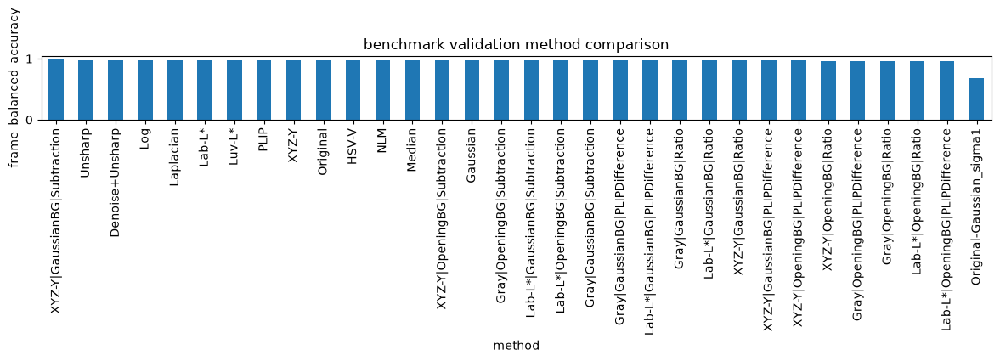

Winner is now locked. Do not change it after seeing the test table.


In [90]:
# Cell 90 — Pick the winner using validation only
# Output: One selected window/distance per method, plus a locked overall winner.
# Global is a control, not a location finder. Rank is a control, not a candidate here.
eligible100=valid100[(valid100['size']!='Global')&(~valid100.rank_control)].copy()
eligible100['method_order']=eligible100.method.map({n:i for i,n in enumerate(TEST_METHODS)})
eligible100=eligible100.sort_values(['frame_balanced_accuracy','balanced_accuracy','D_margin','method_order','size','distance'],
                                  ascending=[False,False,False,True,True,True],kind='stable')
BEST100=eligible100.iloc[0]
BEST_KEY100=(BEST100.method,BEST100['size'],BEST100.distance,False)
(OUT/'benchmark_locked_winner.json').write_text(json.dumps(dict(method=BEST100.method,size=BEST100['size'],distance=BEST100.distance,
    selection='Validation mean frame balanced accuracy; then pooled balanced accuracy; then chi-square margin',
    validation_frame_balanced_accuracy=float(BEST100.frame_balanced_accuracy)),indent=2))
per_method100=eligible100.drop_duplicates('method').copy()
table(per_method100,'benchmark_best_validation_setting_per_method')
table(pd.DataFrame([BEST100]),'benchmark_validation_winner')
chart(per_method100,'method','frame_balanced_accuracy','benchmark_validation_method_comparison')
print('Winner is now locked. Do not change it after seeing the test table.')


,method,size,distance,rank_control,selected_winner,D_AB,D_AA,D_BB,D_within,D_margin,n,n_animal,n_background,accuracy,balanced_accuracy,frame_balanced_accuracy,precision,recall,f1,auc
0,XYZ-Y|GaussianBG|Subtraction,16,L1,False,True,0.801535,0.480618,0.426776,0.453697,0.347838,594,114,480,0.966330,0.969134,0.973859,0.867188,0.973684,0.917355,0.993622
1,XYZ-Y|GaussianBG|Subtraction,16,L1,True,True,0.870605,0.490714,0.637590,0.564152,0.306453,594,114,480,0.952862,0.964145,0.961806,0.811594,0.982456,0.888889,0.986550
2,Unsharp,16,L1,False,False,0.839686,0.304411,0.695986,0.500198,0.339488,594,114,480,0.888889,0.921217,0.921181,0.637931,0.973684,0.770833,0.993019
3,Unsharp,16,L1,True,False,0.866917,0.340529,0.704090,0.522309,0.344608,594,114,480,0.941077,0.953509,0.953472,0.776224,0.973684,0.863813,0.990936
4,Denoise+Unsharp,16,L1,False,False,0.845501,0.322963,0.717520,0.520242,0.325260,594,114,480,0.888889,0.921217,0.921181,0.637931,0.973684,0.770833,0.993110
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59,Lab-L*|OpeningBG|Ratio,32,chi2,True,False,0.822079,0.549034,0.823378,0.686206,0.135872,594,114,480,0.861953,0.881140,0.893095,0.590909,0.912281,0.717241,0.943969
60,Lab-L*|OpeningBG|PLIPDifference,32,chi2,False,False,0.544389,0.344182,0.312857,0.328519,0.215870,594,114,480,0.909091,0.843421,0.811468,0.777778,0.736842,0.756757,0.957785
61,Lab-L*|OpeningBG|PLIPDifference,32,chi2,True,False,0.822269,0.548305,0.823045,0.685675,0.136594,594,114,480,0.860269,0.880099,0.892054,0.587571,0.912281,0.714777,0.943988
62,Original-Gaussian_sigma1,32,L2,False,False,0.117502,0.045742,0.031306,0.038524,0.078978,594,114,480,0.878788,0.894901,0.854911,0.625000,0.921053,0.744681,0.941246


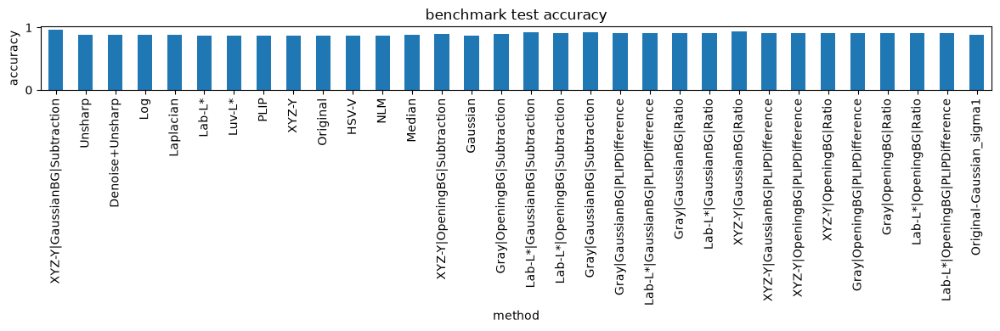

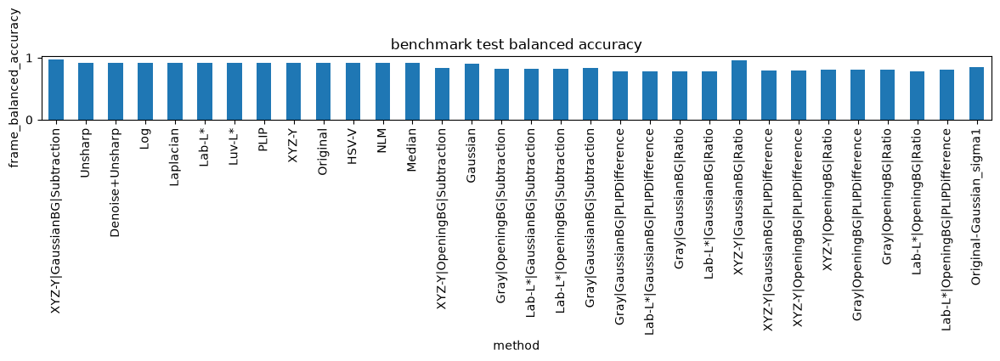

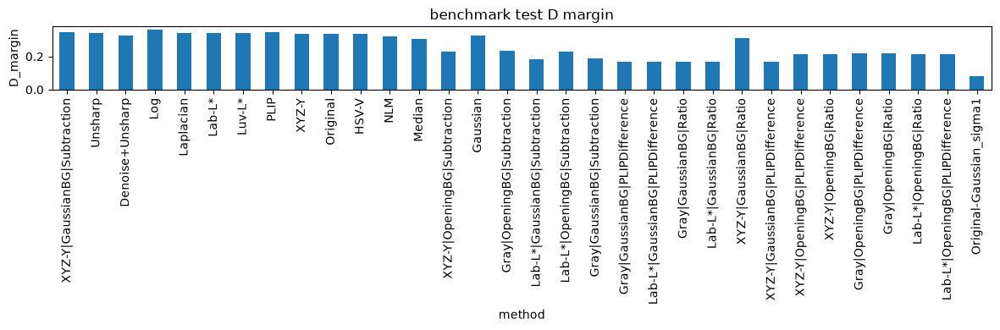

,method,size,distance,D_AB,D_AA,D_BB,D_within,D_margin,n,n_animal,n_background,accuracy,balanced_accuracy,frame_balanced_accuracy,precision,recall,f1,auc
0,Original,16,chi2,0.867784,0.314320,0.750104,0.532212,0.335572,594,114,480,0.872054,0.914145,0.912500,0.602151,0.982456,0.746667,0.994115
1,HSV-V,16,chi2,0.867784,0.314320,0.750104,0.532212,0.335572,594,114,480,0.872054,0.914145,0.912500,0.602151,0.982456,0.746667,0.994115
2,XYZ-Y,16,chi2,0.867784,0.314320,0.750104,0.532212,0.335572,594,114,480,0.872054,0.914145,0.912500,0.602151,0.982456,0.746667,0.994115
3,Lab-L*,16,chi2,0.866107,0.301907,0.749027,0.525467,0.340640,594,114,480,0.870370,0.913103,0.911458,0.598930,0.982456,0.744186,0.994134
4,Luv-L*,16,chi2,0.866107,0.301907,0.749027,0.525467,0.340640,594,114,480,0.870370,0.913103,0.911458,0.598930,0.982456,0.744186,0.994134
5,Log,16,chi2,0.856377,0.247057,0.741368,0.494213,0.362165,594,114,480,0.870370,0.913103,0.911458,0.598930,0.982456,0.744186,0.994591
6,PLIP,16,chi2,0.862415,0.284303,0.745832,0.515067,0.347347,594,114,480,0.870370,0.916447,0.912500,0.597884,0.991228,0.745875,0.994463
7,Gaussian,16,chi2,0.888914,0.332965,0.794916,0.563941,0.324973,594,114,480,0.865320,0.909978,0.908333,0.589474,0.982456,0.736842,0.992946
8,Median,16,chi2,0.891060,0.379223,0.791245,0.585234,0.305826,594,114,480,0.873737,0.918531,0.914583,0.604278,0.991228,0.750831,0.993750
9,NLM,16,chi2,0.870390,0.333060,0.761466,0.547263,0.323126,594,114,480,0.870370,0.913103,0.911458,0.598930,0.982456,0.744186,0.993787


Accuracy scores describe box-centered animal patches vs safe background patches. They are not full-image detection scores.


In [91]:
# Cell 91 — Final test accuracy and D for every pipeline
# Output: Final accuracy, balanced accuracy, precision, recall, F1, AUC and D; a shared-setting control too.
# Each method gets its best VALIDATION setting. Test scores do not choose the settings.
# Show every method as requested, but do not pick a new winner from this table.
TEST100=[];testmask=MASK100['test']
for row in per_method100.itertuples(index=False):
    for rank in [False,True]:
        key=(row.method,row.size,row.distance,rank);pred,score=TEST_CACHE100[key]
        dd=distance100[(distance100.method==row.method)&(distance100['size']==row.size)&
                       (distance100.rank_control==rank)&(distance100.split=='test')].iloc[0]
        vals={c:float(dd[c]) for c in ['D_AB','D_AA','D_BB','D_within','D_margin']}
        TEST100.append(dict(method=row.method,size=row.size,distance=row.distance,rank_control=rank,
            selected_winner=(row.method==BEST100.method),**vals,**score100(Y100[testmask],pred,score,FRAME100[testmask])))
test100=pd.DataFrame(TEST100);table(test100,'benchmark_final_test_per_method')
fixed_test100=test100[~test100.rank_control].copy()
chart(fixed_test100,'method','accuracy','benchmark_test_accuracy')
chart(fixed_test100,'method','frame_balanced_accuracy','benchmark_test_balanced_accuracy')
chart(fixed_test100,'method','D_margin','benchmark_test_D_margin')
# Also compare all methods with EXACTLY the same 16-pixel, chi-square setting.
COMMON100=[]
for name in TEST_METHODS:
    pred,score=TEST_CACHE100[(name,'16','chi2',False)]
    dd=distance100[(distance100.method==name)&(distance100['size']=='16')&(~distance100.rank_control)&(distance100.split=='test')].iloc[0]
    COMMON100.append(dict(method=name,size='16',distance='chi2',**{c:float(dd[c]) for c in ['D_AB','D_AA','D_BB','D_within','D_margin']},
                         **score100(Y100[testmask],pred,score,FRAME100[testmask])))
common100=pd.DataFrame(COMMON100);table(common100,'benchmark_test_common_16_chi2')
print('Accuracy scores describe box-centered animal patches vs safe background patches. They are not full-image detection scores.')


,method,size,distance,D_AB,D_AA,D_BB,D_within,D_margin,n,n_animal,n_background,accuracy,balanced_accuracy,frame_balanced_accuracy,precision,recall,f1,auc,accuracy_gain,balanced_accuracy_gain,margin_gain
0,Original,16,chi2,0.867784,0.314320,0.750104,0.532212,0.335572,594,114,480,0.872054,0.914145,0.912500,0.602151,0.982456,0.746667,0.994115,0.000000,0.000000,0.000000
13,Original-Gaussian_sigma1,16,chi2,0.176323,0.090588,0.052845,0.071717,0.104606,594,114,480,0.929293,0.916118,0.879365,0.772727,0.894737,0.829268,0.926901,0.057239,0.001974,-0.230966
14,Gray|GaussianBG|Subtraction,16,chi2,0.785791,0.475129,0.399764,0.437446,0.348345,594,114,480,0.969697,0.971217,0.975942,0.880952,0.973684,0.925000,0.993512,0.097643,0.057072,0.012773
15,Gray|GaussianBG|PLIPDifference,16,chi2,0.780238,0.493813,0.404983,0.449398,0.330840,594,114,480,0.964646,0.971436,0.975347,0.854962,0.982456,0.914286,0.991831,0.092593,0.057292,-0.004732
16,Gray|GaussianBG|Ratio,16,chi2,0.769793,0.478749,0.387408,0.433078,0.336715,594,114,480,0.968013,0.973520,0.977431,0.868217,0.982456,0.921811,0.991813,0.095960,0.059375,0.001143
17,Gray|OpeningBG|Subtraction,16,chi2,0.844441,0.491048,0.436976,0.464012,0.380429,594,114,480,0.956229,0.952851,0.942222,0.843750,0.947368,0.892562,0.991246,0.084175,0.038706,0.044857
18,Gray|OpeningBG|PLIPDifference,16,chi2,0.843390,0.516042,0.460909,0.488476,0.354914,594,114,480,0.949495,0.931963,0.924375,0.844262,0.903509,0.872881,0.987500,0.077441,0.017818,0.019342
19,Gray|OpeningBG|Ratio,16,chi2,0.838400,0.523221,0.442882,0.483052,0.355348,594,114,480,0.951178,0.933004,0.925417,0.851240,0.903509,0.876596,0.987427,0.079125,0.018860,0.019776


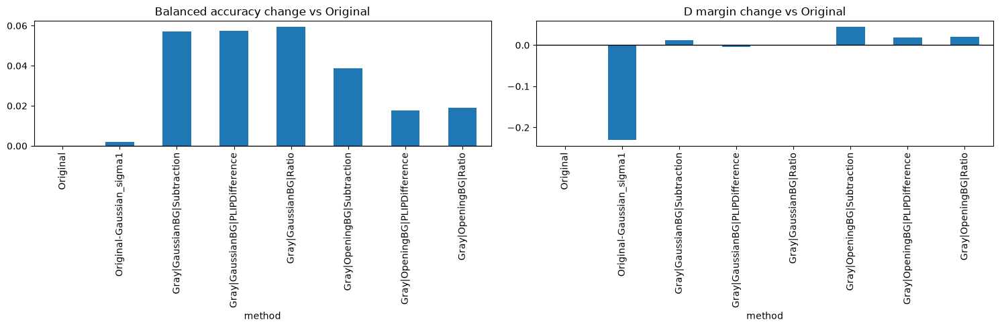

label,method,split,background_residual,animal_residual,animal_to_background_ratio
0,Gray|GaussianBG|PLIPDifference,test,0.018330,0.071312,3.890422
1,Gray|GaussianBG|PLIPDifference,train,0.019514,0.072679,3.724361
2,Gray|GaussianBG|PLIPDifference,validation,0.018966,0.074108,3.907505
3,Gray|GaussianBG|Ratio,test,0.009836,0.047744,4.854144
4,Gray|GaussianBG|Ratio,train,0.010486,0.049042,4.676893
5,Gray|GaussianBG|Ratio,validation,0.010131,0.049218,4.858299
6,Gray|GaussianBG|Subtraction,test,0.013703,0.080043,5.841158
7,Gray|GaussianBG|Subtraction,train,0.013550,0.081870,6.042152
8,Gray|GaussianBG|Subtraction,validation,0.011884,0.083840,7.054948
9,Gray|OpeningBG|PLIPDifference,test,0.041629,0.113089,2.716567


A good-looking residual is not enough. Check class D, within-class D, and held-out patch accuracy together.
Residual values use each method's fixed display formula. Do not compare their raw sizes as if they had identical units.


In [92]:
# Cell 92 — Do subtraction and PLIP really help?
# Output: Matched-setting gains and actual animal/background residuals.
focus=['Original','Original-Gaussian_sigma1','Gray|GaussianBG|Subtraction','Gray|GaussianBG|PLIPDifference',
       'Gray|OpeningBG|Subtraction','Gray|OpeningBG|PLIPDifference','Gray|GaussianBG|Ratio','Gray|OpeningBG|Ratio']
focus100=common100[common100.method.isin(focus)].copy();baseline100=common100[common100.method=='Original'].iloc[0]
focus100['accuracy_gain']=focus100.accuracy-baseline100.accuracy
focus100['balanced_accuracy_gain']=focus100.balanced_accuracy-baseline100.balanced_accuracy
focus100['margin_gain']=focus100.D_margin-baseline100.D_margin
table(focus100,'benchmark_subtraction_plip_vs_original')
fig,axes=plt.subplots(1,2,figsize=(15,5))
focus100.plot.bar(x='method',y='balanced_accuracy_gain',ax=axes[0],legend=False)
focus100.plot.bar(x='method',y='margin_gain',ax=axes[1],legend=False)
axes[0].set_title('Balanced accuracy change vs Original');axes[1].set_title('D margin change vs Original')
for ax in axes:ax.axhline(0,color='black',lw=1)
savefig('benchmark_subtraction_plip_gains')
res100=pd.DataFrame(RESIDUAL100)
r=res100.groupby(['method','split','label']).abs_residual.mean().unstack('label').reset_index()
r=r.rename(columns={0:'background_residual',1:'animal_residual'})
r['animal_to_background_ratio']=r.animal_residual/(r.background_residual+EPS)
table(r,'benchmark_background_residuals')
print('A good-looking residual is not enough. Check class D, within-class D, and held-out patch accuracy together.')
print('Residual values use each method\'s fixed display formula. Do not compare their raw sizes as if they had identical units.')


In [93]:
# Cell 93 — Rank control: remapping versus useful change
# Output: Normal-bin and rank-bin accuracy; equivalence controls checked numerically.
# Use one shared 16-pixel chi-square setting so the control is fair.
rank_rows=[]
for name in TEST_METHODS:
    for rank in [False,True]:
        pred,score=TEST_CACHE100[(name,'16','chi2',rank)]
        rank_rows.append(dict(method=name,rank_control=rank,**score100(Y100[testmask],pred,score,FRAME100[testmask])))
rank_comparison100=pd.DataFrame(rank_rows);table(rank_comparison100,'benchmark_rank_control_common_setting')
for name in ['HSV-V','XYZ-Y','Lab-L*','Luv-L*','Log','PLIP']:
    p,s=TEST_CACHE100[(name,'16','chi2',True)];p0,s0=TEST_CACHE100[('Original','16','chi2',True)]
    assert np.array_equal(p,p0) and np.allclose(s,s0,atol=1e-6),name
print('Rank controls match Original for the pointwise brightness mappings. No new scene information was added.')
print('If a fixed-bin score changes, the brightness mapping changed the feature bins or their weighting.')


,method,rank_control,n,n_animal,n_background,accuracy,balanced_accuracy,frame_balanced_accuracy,precision,recall,f1,auc
0,Original,False,594,114,480,0.872054,0.914145,0.912500,0.602151,0.982456,0.746667,0.994115
1,Original,True,594,114,480,0.900673,0.938542,0.938542,0.658960,1.000000,0.794425,0.995760
2,HSV-V,False,594,114,480,0.872054,0.914145,0.912500,0.602151,0.982456,0.746667,0.994115
3,HSV-V,True,594,114,480,0.900673,0.938542,0.938542,0.658960,1.000000,0.794425,0.995760
4,XYZ-Y,False,594,114,480,0.872054,0.914145,0.912500,0.602151,0.982456,0.746667,0.994115
...,...,...,...,...,...,...,...,...,...,...,...,...
59,Lab-L*|OpeningBG|Subtraction,True,594,114,480,0.912458,0.945833,0.945833,0.686747,1.000000,0.814286,0.986239
60,Lab-L*|OpeningBG|PLIPDifference,False,594,114,480,0.947811,0.927577,0.920208,0.842975,0.894737,0.868085,0.986897
61,Lab-L*|OpeningBG|PLIPDifference,True,594,114,480,0.919192,0.950000,0.950000,0.703704,1.000000,0.826087,0.980117
62,Lab-L*|OpeningBG|Ratio,False,594,114,480,0.949495,0.928618,0.921250,0.850000,0.894737,0.871795,0.986732


Rank controls match Original for the pointwise brightness mappings. No new scene information was added.
If a fixed-bin score changes, the brightness mapping changed the feature bins or their weighting.


,frame,split,label,cx,cy,track_id,box_width,box_height,prediction,score,correct
2613,4164,test,1,246,84,51,24,25,1,0.655534,True
2614,4164,test,0,16,16,-1,32,32,0,-0.903259,True
2615,4164,test,0,304,16,-1,32,32,0,-0.578491,True
2616,4164,test,0,592,16,-1,32,32,0,-1.262800,True
2617,4164,test,0,208,48,-1,32,32,0,-0.806304,True
...,...,...,...,...,...,...,...,...,...,...,...
3202,5429,test,0,112,272,-1,32,32,0,-1.079705,True
3203,5429,test,0,400,272,-1,32,32,0,-0.951435,True
3204,5429,test,0,80,304,-1,32,32,0,-1.172762,True
3205,5429,test,0,368,304,-1,32,32,0,-0.698843,True


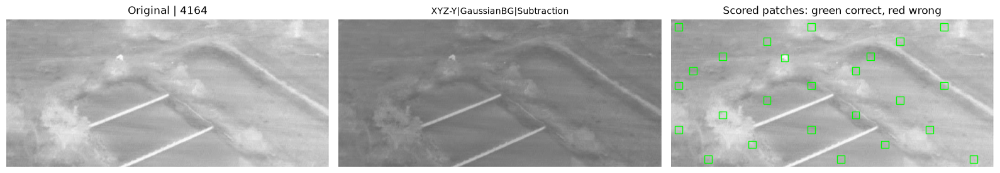

These are the scored sample patches, not a whole-image animal detector.


In [94]:
# Cell 94 — Show the locked winner and its errors
# Output: The chosen pipeline, real test predictions, and visible mistakes.
pred,score=TEST_CACHE100[BEST_KEY100];test_samples=B100[testmask].copy()
test_samples['prediction']=pred;test_samples['score']=score;test_samples['correct']=pred==test_samples.label.to_numpy()
table(test_samples,'benchmark_winner_test_predictions')
# Show the first test frame with animals, a fixed choice rather than a pretty result.
frame=int(BENCH[BENCH.split=='test'].iloc[0].frame);a=A100[frame];processed=process100(BEST100.method,a)
fig,axes=plt.subplots(1,3,figsize=(16,4))
axes[0].imshow(a,cmap='gray',vmin=0,vmax=1);axes[0].set_title(f'Original | {frame}')
axes[1].imshow(processed,cmap='gray',vmin=0,vmax=1);axes[1].set_title(BEST100.method,fontsize=10)
axes[2].imshow(a,cmap='gray',vmin=0,vmax=1);axes[2].set_title('Scored patches: green correct, red wrong')
size=int(BEST100['size'])
for row in test_samples[test_samples.frame==frame].itertuples():
    axes[2].add_patch(Rectangle((max(0,row.cx-size//2),max(0,row.cy-size//2)),
                       min(size,a.shape[1]-max(0,row.cx-size//2)),min(size,a.shape[0]-max(0,row.cy-size//2)),
                       fill=False,edgecolor='lime' if row.correct else 'red',lw=1))
for ax in axes:ax.axis('off')
savefig('benchmark_locked_winner_example')
print('These are the scored sample patches, not a whole-image animal detector.')


In [95]:
# Cell 95 — Final answer from the actual test
# Output: The validation-selected pipeline and its final test scores, with the scope stated clearly.
winner_result=test100[(test100.method==BEST100.method)&(~test100.rank_control)].iloc[0]
final_summary100=pd.DataFrame([dict(pipeline=BEST100.method,window=BEST100['size'],distance=BEST100.distance,
    validation_frame_balanced_accuracy=BEST100.frame_balanced_accuracy,test_accuracy=winner_result.accuracy,
    test_balanced_accuracy=winner_result.balanced_accuracy,test_frame_balanced_accuracy=winner_result.frame_balanced_accuracy,
    test_precision=winner_result.precision,test_recall=winner_result.recall,test_f1=winner_result.f1,
    test_D_AB=winner_result.D_AB,test_D_within=winner_result.D_within,test_D_margin=winner_result.D_margin)])
table(final_summary100,'FINAL_100_IMAGE_SUMMARY')
print('Best here means best validation score among the tested choices, with these fixed parameters.')
print('It does not mean best on all wildlife data. We used one video and box-based patch labels.')
print('No threshold baseline. No made-up GT. No test-score tuning.')
print('All plots and CSV files are in:',OUT.resolve())


,pipeline,window,distance,validation_frame_balanced_accuracy,test_accuracy,test_balanced_accuracy,test_frame_balanced_accuracy,test_precision,test_recall,test_f1,test_D_AB,test_D_within,test_D_margin
0,XYZ-Y|GaussianBG|Subtraction,16,L1,0.989762,0.96633,0.969134,0.973859,0.867188,0.973684,0.917355,0.801535,0.453697,0.347838


Best here means best validation score among the tested choices, with these fixed parameters.
It does not mean best on all wildlife data. We used one video and box-based patch labels.
No threshold baseline. No made-up GT. No test-score tuning.
All plots and CSV files are in: /Users/yingying/.codex/.chatgpt-projects/g-p-6a9853e50250819194465d3e0ed1452b/output/Wildlife_Midterm_GT/results


In [2]:
# Cell 96 — Is sigma 24 too much?
# Output: Separate scale formulas and a plain-language explanation.
# A denoising blur and a background blur have different jobs.
# Here we subtract the blur from the original. We do not replace the original with the blur.
# Test the scale, rather than saying 24 must be right.
display(Math(r'B_\sigma=G_\sigma*I,\quad D_\sigma=I-B_\sigma,\quad\sigma\in\{4,8,12,16,24,32,48\}'))
display(Math(r'\mathrm{FWHM}=2\sqrt{2\ln2}\,\sigma\approx2.355\sigma,\quad\mathrm{kernel\ width}=2\,\mathrm{round}(4\sigma)+1'))
print('For sigma 24: FWHM is about 56.5 pixels. SciPy uses a 193-pixel full kernel at its default cutoff.')
print('That is a broad background guess. It would be a very strong ordinary denoising blur.')
print('Large animals can still leak into the background guess. Bigger sigma is not always better.')


<IPython.core.display.Math object>

<IPython.core.display.Math object>

For sigma 24: FWHM is about 56.5 pixels. SciPy uses a 193-pixel full kernel at its default cutoff.
That is a broad background guess. It would be a very strong ordinary denoising blur.
Large animals can still leak into the background guess. Bigger sigma is not always better.


In [3]:
# Cell 97 — Check Gaussian scale on validation only
# Output: A controlled sigma sweep using train and validation only; old results checked for agreement.
# Keep window=16. Compare L1 and chi-square with the same labels and samples.
# Do not use test scores to choose sigma.
SIGMAS=[4,8,12,16,24,32,48]
scale_samples=B100[B100.split!='test'].reset_index(drop=True)
scale_train=scale_samples.split.to_numpy()=='train';scale_val=~scale_train
scale_y=scale_samples.label.to_numpy();scale_frames=scale_samples.frame.to_numpy()
SCALE_ROWS=[]
for rep,base in BASE_REPS.items():
    for sigma in SIGMAS:
        features={op:np.empty((len(scale_samples),256),np.float32) for op in ['Subtraction','PLIPDifference','Ratio']}
        for frame,rows in scale_samples.groupby('frame',sort=False):
            u=process100(base,A100[frame]);b=ndi.gaussian_filter(u,sigma,mode='reflect')
            d=u-b;pdiff=M*d/(M-1+u);q=np.log((u+CFG['ratio_epsilon'])/(b+CFG['ratio_epsilon']))
            mapped={'Subtraction':(1+d)/2,'PLIPDifference':(1+pdiff/(1+np.abs(pdiff)))/2,
                    'Ratio':(1+np.tanh(q/CFG['ratio_log_scale']))/2}
            for op,a in mapped.items():
                for i,row in rows.iterrows():features[op][i]=hist(center_patch(a,int(row.cx),int(row.cy),16))
        for op,X in features.items():
            refs={c:X[scale_train&(scale_y==c)].mean(axis=0) for c in [0,1]}
            dd=pair_distances(X[scale_val],scale_y[scale_val])
            for kind in ['L1','chi2']:
                d0=distance(X[scale_val],refs[0],kind);d1=distance(X[scale_val],refs[1],kind)
                SCALE_ROWS.append(dict(representation=rep,operation=op,sigma=sigma,size=16,distance=kind,**dd,
                    **score100(scale_y[scale_val],(d1<d0).astype(int),d0-d1,scale_frames[scale_val])))
        print(f'Scale check: {rep}, sigma={sigma}',flush=True)
scale_results=pd.DataFrame(SCALE_ROWS);table(scale_results,'gaussian_sigma_validation_sweep')
# The sigma=24 rows must match the earlier validation results. Same math, same samples.
old_valid=pd.read_csv(OUT/'benchmark_validation_all_settings.csv')
for row in scale_results[scale_results.sigma==24].itertuples():
    old=old_valid[(old_valid.method==f'{row.representation}|GaussianBG|{row.operation}')&
                 (old_valid['size'].astype(str)=='16')&(old_valid.distance==row.distance)&(~old_valid.rank_control)].iloc[0]
    assert np.isclose(old.frame_balanced_accuracy,row.frame_balanced_accuracy)
    assert np.isclose(old.D_margin,row.D_margin,atol=1e-6)


Scale check: Gray, sigma=4


Scale check: Gray, sigma=8


Scale check: Gray, sigma=12


Scale check: Gray, sigma=16


Scale check: Gray, sigma=24


Scale check: Gray, sigma=32


... (12 outputs left out)

Scale check: Lab-L*, sigma=24


Scale check: Lab-L*, sigma=32


Scale check: Lab-L*, sigma=48


,representation,operation,sigma,size,distance,D_AB,D_AA,D_BB,D_within,D_margin,n,n_animal,n_background,accuracy,balanced_accuracy,frame_balanced_accuracy,precision,recall,f1,auc
0,Gray,Subtraction,4,16,L1,0.425501,0.367422,0.100448,0.233935,0.191566,638,158,480,0.873041,0.752162,0.782301,0.952941,0.512658,0.666667,0.983175
1,Gray,Subtraction,4,16,chi2,0.425501,0.367422,0.100448,0.233935,0.191566,638,158,480,0.879310,0.762698,0.794592,0.965517,0.531646,0.685714,0.979417
2,Gray,PLIPDifference,4,16,L1,0.401030,0.375727,0.113436,0.244581,0.156449,638,158,480,0.858934,0.730050,0.762429,0.914634,0.474684,0.625000,0.973787
3,Gray,PLIPDifference,4,16,chi2,0.401030,0.375727,0.113436,0.244581,0.156449,638,158,480,0.858934,0.725804,0.737012,0.935897,0.462025,0.618644,0.968908
4,Gray,Ratio,4,16,L1,0.355445,0.328471,0.095895,0.212183,0.143262,638,158,480,0.858934,0.730050,0.762429,0.914634,0.474684,0.625000,0.960997
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
121,Lab-L*,Subtraction,48,16,chi2,0.931120,0.768190,0.475105,0.621647,0.309473,638,158,480,0.974922,0.970596,0.957024,0.938272,0.962025,0.950000,0.992194
122,Lab-L*,PLIPDifference,48,16,L1,0.923497,0.769679,0.488379,0.629029,0.294468,638,158,480,0.967085,0.967511,0.953274,0.905325,0.968354,0.935780,0.986379
123,Lab-L*,PLIPDifference,48,16,chi2,0.923497,0.769679,0.488379,0.629029,0.294468,638,158,480,0.963950,0.965427,0.951190,0.894737,0.968354,0.930091,0.986472
124,Lab-L*,Ratio,48,16,L1,0.919515,0.766841,0.470576,0.618708,0.300807,638,158,480,0.968652,0.968552,0.954315,0.910714,0.968354,0.938650,0.986419


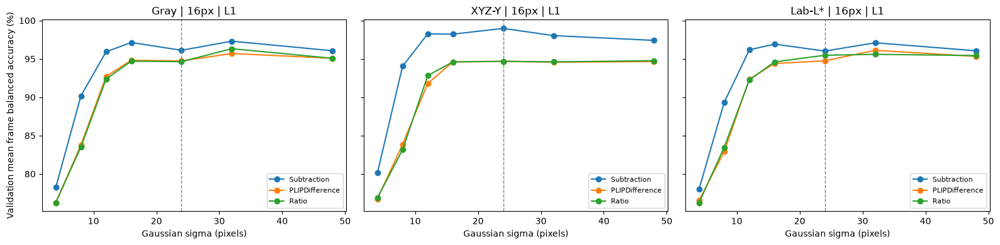

,representation,operation,sigma,size,distance,D_AB,D_AA,D_BB,D_within,D_margin,n,n_animal,n_background,accuracy,balanced_accuracy,frame_balanced_accuracy,precision,recall,f1,auc
66,XYZ-Y,Subtraction,24,16,L1,0.926445,0.699582,0.418017,0.558800,0.367645,638,158,480,0.990596,0.989504,0.989762,0.975000,0.987342,0.981132,0.996479
55,XYZ-Y,Subtraction,12,16,chi2,0.901828,0.585877,0.308543,0.447210,0.454618,638,158,480,0.990596,0.987381,0.982639,0.981013,0.981013,0.981013,0.996545
30,Gray,Subtraction,32,16,L1,0.917830,0.735250,0.428308,0.581779,0.336051,638,158,480,0.984326,0.981092,0.973095,0.962500,0.974684,0.968553,0.994673
31,Gray,Subtraction,32,16,chi2,0.917830,0.735250,0.428308,0.581779,0.336051,638,158,480,0.984326,0.981092,0.973095,0.962500,0.974684,0.968553,0.995491
114,Lab-L*,Subtraction,32,16,L1,0.915573,0.736061,0.426556,0.581308,0.334265,638,158,480,0.981191,0.979008,0.971012,0.950617,0.974684,0.962500,0.994238
115,Lab-L*,Subtraction,32,16,chi2,0.915573,0.736061,0.426556,0.581308,0.334265,638,158,480,0.979624,0.975844,0.967440,0.950311,0.968354,0.959248,0.995069
34,Gray,Ratio,32,16,L1,0.897044,0.735031,0.422357,0.578694,0.318351,638,158,480,0.973354,0.971677,0.963274,0.927273,0.968354,0.947368,0.990229
116,Lab-L*,PLIPDifference,32,16,L1,0.900652,0.740950,0.439361,0.590155,0.310497,638,158,480,0.970219,0.969594,0.961190,0.916168,0.968354,0.941538,0.989636
32,Gray,PLIPDifference,32,16,L1,0.902316,0.740256,0.441197,0.590727,0.311589,638,158,480,0.971787,0.968513,0.957024,0.926829,0.962025,0.944099,0.990045
118,Lab-L*,Ratio,32,16,L1,0.895656,0.731693,0.420019,0.575856,0.319800,638,158,480,0.970219,0.967471,0.955982,0.921212,0.962025,0.941176,0.989834


,method,size,distance,D_AB,D_AA,D_BB,D_within,D_margin,n,n_animal,n_background,accuracy,balanced_accuracy,frame_balanced_accuracy,precision,recall,f1,auc
14,Gray|GaussianBG|Subtraction,16,chi2,0.785791,0.475129,0.399764,0.437446,0.348345,594,114,480,0.969697,0.971217,0.975942,0.880952,0.973684,0.925000,0.993512
16,Gray|GaussianBG|Ratio,16,chi2,0.769793,0.478749,0.387408,0.433078,0.336715,594,114,480,0.968013,0.973520,0.977431,0.868217,0.982456,0.921811,0.991813
20,XYZ-Y|GaussianBG|Subtraction,16,chi2,0.801535,0.480618,0.426776,0.453697,0.347838,594,114,480,0.966330,0.969134,0.973859,0.867188,0.973684,0.917355,0.994189
22,XYZ-Y|GaussianBG|Ratio,16,chi2,0.779154,0.524071,0.411015,0.467543,0.311612,594,114,480,0.964646,0.968092,0.972817,0.860465,0.973684,0.913580,0.991393
26,Lab-L*|GaussianBG|Subtraction,16,chi2,0.783698,0.473634,0.397595,0.435614,0.348084,594,114,480,0.969697,0.971217,0.975942,0.880952,0.973684,0.925000,0.993403
28,Lab-L*|GaussianBG|Ratio,16,chi2,0.768066,0.472989,0.384567,0.428778,0.339289,594,114,480,0.968013,0.973520,0.977431,0.868217,0.982456,0.921811,0.992032


The table above uses sigma=24, window=16 and chi-square matching for BOTH operations.
The new sigma sweep is validation-only. It does not replace the earlier locked test result.
Use it to judge whether 24 is reasonable, not to claim a new untouched test score.


In [4]:
# Cell 98 — Read the scale check and compare division with subtraction
# Output: Sigma sensitivity plots and a fair division/subtraction test table.
fig,axes=plt.subplots(1,3,figsize=(16,4),sharey=True)
for ax,rep in zip(axes,BASE_REPS):
    for op in ['Subtraction','PLIPDifference','Ratio']:
        rows=scale_results[(scale_results.representation==rep)&(scale_results.operation==op)&(scale_results.distance=='L1')]
        ax.plot(rows.sigma,rows.frame_balanced_accuracy*100,marker='o',label=op)
    ax.axvline(24,color='gray',ls='--',lw=1);ax.set_title(rep+' | 16px | L1');ax.set_xlabel('Gaussian sigma (pixels)');ax.legend(fontsize=8)
axes[0].set_ylabel('Validation mean frame balanced accuracy (%)');savefig('gaussian_sigma_validation_curves')
scale_best=scale_results.sort_values(['frame_balanced_accuracy','balanced_accuracy','D_margin','sigma'],ascending=[False,False,False,True]).drop_duplicates(['representation','operation','distance'])
table(scale_best,'gaussian_sigma_best_validation_per_operation')
# Division here is a safe log-ratio, not raw division or PLIP division.
# q=log((I+epsilon)/(B+epsilon)); output=(1+tanh(q/tau))/2.
# Compare only the SAME representation, sigma, window and matching rule.
common_test=pd.read_csv(OUT/'benchmark_test_common_16_chi2.csv')
comparison=common_test[common_test.method.isin([f'{rep}|GaussianBG|{op}' for rep in BASE_REPS for op in ['Subtraction','Ratio']])]
table(comparison,'division_vs_subtraction_test_same_setting')
print('The table above uses sigma=24, window=16 and chi-square matching for BOTH operations.')
print('The new sigma sweep is validation-only. It does not replace the earlier locked test result.')
print('Use it to judge whether 24 is reasonable, not to claim a new untouched test score.')
